# Custom CNN for Rice Leaf Disease Classification

This notebook presents an end-to-end custom CNN workflow for classifying rice leaf disease images into four categories: Bacterialblight, Blast, Brownspot, and Tungro.

The workflow covers dataset loading, data-quality checks, duplicate and near-duplicate handling, split validation, CNN experiment comparison, final held-out testing, and Grad-CAM based interpretability.


### Cell 1: Download and Load Dataset

Installs the required packages, downloads the rice leaf disease dataset from KaggleHub, and prepares the dataset path for the rest of the workflow.


In [2]:
!pip -q install kagglehub pillow pandas

import kagglehub
from pathlib import Path

# Download Rice Leaf Disease dataset
path = kagglehub.dataset_download(
    "nirmalsankalana/rice-leaf-disease-image"
)

# Define dataset directory
root = Path(path)

print("Dataset location:", root)
print("Dataset exists:", root.exists())

100%|██████████| 195M/195M [00:02<00:00, 102MB/s] 

Extracting files...


Dataset location: /root/.cache/kagglehub/datasets/nirmalsankalana/rice-leaf-disease-image/versions/1
Dataset exists: True


## 1. Dataset Loading and Initial Validation

The dataset is downloaded from KaggleHub, scanned with Pillow, and converted into a dataframe containing image paths and class labels. The initial class distribution is checked before any cleaning is performed.


### Cell 2: Validate Image Files

Scans every file in the dataset, keeps readable image files, records their class labels, and prints the initial class distribution.


In [3]:
from pathlib import Path
from PIL import Image
import pandas as pd

records = []
invalid_files = []

for file in root.rglob("*"):
    if not file.is_file():
        continue

    if file.suffix.lower() not in {
        ".jpg", ".jpeg", ".png", ".webp", ".bmp"
    }:
        continue

    try:
        with Image.open(file) as img:
            width, height = img.size

            records.append({
                "filepath": str(file),
                "class": file.parent.name,
                "width": width,
                "height": height,
                "resolution": f"{width}x{height}",
                "aspect_ratio": round(width / height, 3),
                "mode": img.mode
            })

    except Exception as e:
        invalid_files.append((str(file), str(e)))

df = pd.DataFrame(records)

print("Total valid images:", len(df))
print("Unreadable images:", len(invalid_files))

if not df.empty:
    print("\nClass distribution:")
    print(df["class"].value_counts())

    print("\nTop 15 image resolutions:")
    print(df["resolution"].value_counts().head(15))

    print("\nImage color modes:")
    print(df["mode"].value_counts())

    print("\nImage dimensions:")
    print(df[["width", "height", "aspect_ratio"]].describe())

print("\nInvalid files:")
print(invalid_files[:10])

Total valid images: 5932
Unreadable images: 0

Class distribution:
class
Brownspot          1600
Bacterialblight    1584
Blast              1440
Tungro             1308
Name: count, dtype: int64

Top 15 image resolutions:
resolution
300x300    4624
499x332      12
221x295      12
295x221      12
521x348      11
288x216      11
331x497      10
284x426      10
381x571      10
538x359       9
571x381       9
359x538       9
426x284       9
219x292       9
217x289       9
Name: count, dtype: int64

Image color modes:
mode
RGB     5776
RGBA     156
Name: count, dtype: int64

Image dimensions:
             width       height  aspect_ratio
count  5932.000000  5932.000000   5932.000000
mean    312.243763   312.203641      1.015545
std      53.418987    53.445428      0.181397
min     209.000000   209.000000      0.664000
25%     300.000000   300.000000      1.000000
50%     300.000000   300.000000      1.000000
75%     300.000000   300.000000      1.000000
max     603.000000   603.000000      

## 2. Duplicate and Near-Duplicate Analysis

Exact duplicate files are detected using SHA-256 hashes. Perceptual hashing, SSIM inspection, and visual samples are then used to identify near-duplicate images that could otherwise inflate model performance.


### Cell 3: Detect Exact Duplicates

Computes SHA-256 hashes for image files so exact duplicate images can be identified before training.


In [4]:
import hashlib
from collections import defaultdict
import pandas as pd

def calculate_sha256(filepath):
    sha256 = hashlib.sha256()

    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


hash_groups = defaultdict(list)

for filepath in df["filepath"]:
    file_hash = calculate_sha256(filepath)
    hash_groups[file_hash].append(filepath)


# Groups containing more than one identical file
duplicate_groups = {
    h: paths
    for h, paths in hash_groups.items()
    if len(paths) > 1
}

total_duplicate_files = sum(
    len(paths) - 1
    for paths in duplicate_groups.values()
)

print("Total images:", len(df))
print("Unique file hashes:", len(hash_groups))
print("Duplicate groups:", len(duplicate_groups))
print("Extra duplicate files:", total_duplicate_files)

print("\nExample duplicate groups:")

for i, (h, paths) in enumerate(
    list(duplicate_groups.items())[:5],
    start=1
):
    print(f"\nGroup {i}:")

    for p in paths:
        print(" ", p)


# Check whether identical files have different labels
cross_class_duplicates = []

for paths in duplicate_groups.values():
    classes = {Path(p).parent.name for p in paths}

    if len(classes) > 1:
        cross_class_duplicates.append(paths)

print("\nCross-class duplicate groups:",
      len(cross_class_duplicates))

Total images: 5932
Unique file hashes: 4794
Duplicate groups: 1096
Extra duplicate files: 1138

Example duplicate groups:

Group 1:
  /root/.cache/kagglehub/datasets/nirmalsankalana/rice-leaf-disease-image/versions/1/Brownspot/BROWNSPOT1_049.jpg
  /root/.cache/kagglehub/datasets/nirmalsankalana/rice-leaf-disease-image/versions/1/Brownspot/BROWNSPOT4_049.jpg

Group 2:
  /root/.cache/kagglehub/datasets/nirmalsankalana/rice-leaf-disease-image/versions/1/Brownspot/BROWNSPOT1_192.jpg
  /root/.cache/kagglehub/datasets/nirmalsankalana/rice-leaf-disease-image/versions/1/Brownspot/BROWNSPOT4_192.jpg

Group 3:
  /root/.cache/kagglehub/datasets/nirmalsankalana/rice-leaf-disease-image/versions/1/Brownspot/BROWNSPOT4_042.jpg
  /root/.cache/kagglehub/datasets/nirmalsankalana/rice-leaf-disease-image/versions/1/Brownspot/BROWNSPOT1_042.jpg

Group 4:
  /root/.cache/kagglehub/datasets/nirmalsankalana/rice-leaf-disease-image/versions/1/Brownspot/BROWNSPOT5_062.jpg
  /root/.cache/kagglehub/datasets/nirmal

### Cell 4: Detect Exact Duplicates

Computes SHA-256 hashes for image files so exact duplicate images can be identified before training.


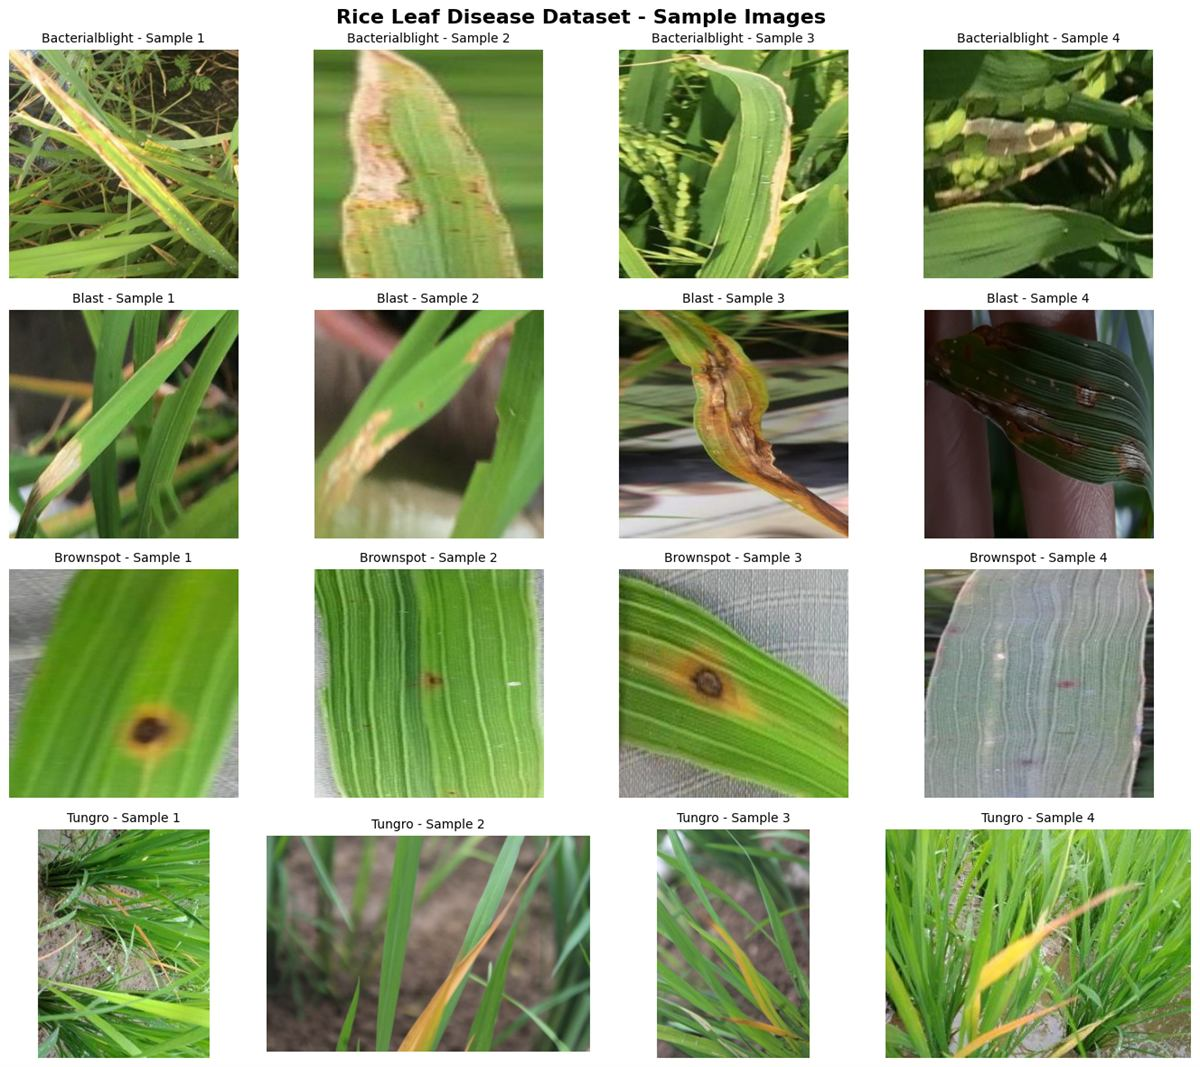

In [6]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

# Recreate class order from the dataset
class_order = sorted(df["class"].unique())

# Use deduplicated data if available
if "unique_df" not in globals():
    import hashlib

    def file_hash(filepath):
        with open(filepath, "rb") as f:
            return hashlib.sha256(f.read()).hexdigest()

    unique_df = df.copy()
    unique_df["sha256"] = unique_df["filepath"].apply(file_hash)
    unique_df = unique_df.drop_duplicates(
        subset="sha256"
    ).copy()

# Display 4 images per class
fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for row, disease in enumerate(class_order):

    samples = unique_df[
        unique_df["class"] == disease
    ].sample(n=4, random_state=42)

    for col, filepath in enumerate(samples["filepath"]):

        with Image.open(filepath) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].axis("off")
        axes[row, col].set_title(
            f"{disease} - Sample {col + 1}",
            fontsize=10
        )

plt.suptitle(
    "Rice Leaf Disease Dataset - Sample Images",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Cell 5: Compute Perceptual Hashes

Uses perceptual hashing to detect visually similar images that may not be byte-for-byte duplicates.


In [7]:
!pip -q install imagehash

import imagehash
from PIL import Image
import pandas as pd
from collections import defaultdict

# Ensure the exact-deduplicated dataframe is available
if "unique_df" not in globals():
    raise RuntimeError(
        "Run the exact-deduplication EDA cell first "
        "to create unique_df."
    )

phashes = []

for filepath in unique_df["filepath"]:
    with Image.open(filepath) as img:
        phash = imagehash.phash(
            img.convert("RGB"),
            hash_size=8
        )
        phashes.append(phash)

unique_df = unique_df.copy()
unique_df["phash"] = phashes

# Group images with identical perceptual hashes
phash_groups = defaultdict(list)

for _, row in unique_df.iterrows():
    phash_groups[str(row["phash"])].append(
        (row["filepath"], row["class"])
    )

identical_phash_groups = {
    h: images
    for h, images in phash_groups.items()
    if len(images) > 1
}

print("Unique files:", len(unique_df))
print("Unique perceptual hashes:", len(phash_groups))
print("Identical pHash groups:",
      len(identical_phash_groups))

print("Additional candidate duplicates:",
      sum(
          len(images) - 1
          for images in identical_phash_groups.values()
      ))

cross_class_phash = [
    images
    for images in identical_phash_groups.values()
    if len(set(label for _, label in images)) > 1
]

print("Cross-class pHash groups:",
      len(cross_class_phash))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 11.8 MB/s eta 0:00:00
Unique files: 4794
Unique perceptual hashes: 2927
Identical pHash groups: 1500
Additional candidate duplicates: 1867
Cross-class pHash groups: 0


### Cell 6: Download and Load Dataset

Installs the required packages, downloads the rice leaf disease dataset from KaggleHub, and prepares the dataset path for the rest of the workflow.


In [10]:
!pip -q install kagglehub imagehash seaborn pandas pillow

import kagglehub
import hashlib
import imagehash
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

# Dataset location
path = kagglehub.dataset_download(
    "nirmalsankalana/rice-leaf-disease-image"
)

root = Path(path)

# Collect image information
records = []

for file in root.rglob("*"):
    if file.suffix.lower() not in {
        ".jpg", ".jpeg", ".png", ".webp", ".bmp"
    }:
        continue

    try:
        with Image.open(file) as img:
            records.append({
                "filepath": str(file),
                "class": file.parent.name,
                "width": img.width,
                "height": img.height,
                "aspect_ratio": img.width / img.height,
                "resolution": f"{img.width}x{img.height}",
                "mode": img.mode
            })
    except Exception as e:
        print("Unreadable:", file, e)

df = pd.DataFrame(records)
eda_df = df.copy()

# Calculate exact file hashes
def sha256_file(filepath):
    h = hashlib.sha256()
    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()

eda_df["sha256"] = eda_df["filepath"].apply(sha256_file)

# Remove exact duplicates from analysis dataframe only
unique_df = eda_df.drop_duplicates(
    subset="sha256"
).copy()

# Calculate perceptual hashes
def calculate_phash(filepath):
    with Image.open(filepath) as img:
        return imagehash.phash(img.convert("RGB"))

unique_df["phash"] = unique_df["filepath"].apply(
    calculate_phash
)

unique_df["phash_str"] = unique_df["phash"].astype(str)

class_order = sorted(eda_df["class"].unique())

print("Original images:", len(eda_df))
print("Unique SHA-256 files:", len(unique_df))
print("Unique perceptual hashes:",
      unique_df["phash_str"].nunique())
print("Detected classes:", class_order)

Using Colab cache for faster access to the 'rice-leaf-disease-image' dataset.
Original images: 5932
Unique SHA-256 files: 4794
Unique perceptual hashes: 2927
Detected classes: ['Bacterialblight', 'Blast', 'Brownspot', 'Tungro']


### Cell 7: Compare Dataset Before and After Deduplication

Visualizes how the dataset distribution changes after exact and perceptual duplicate filtering.


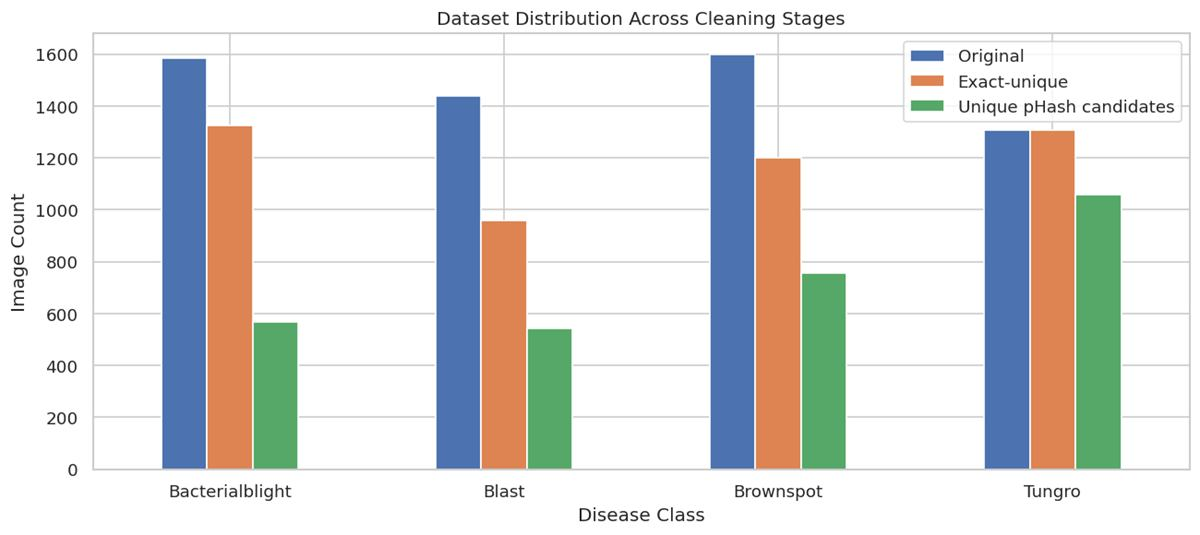

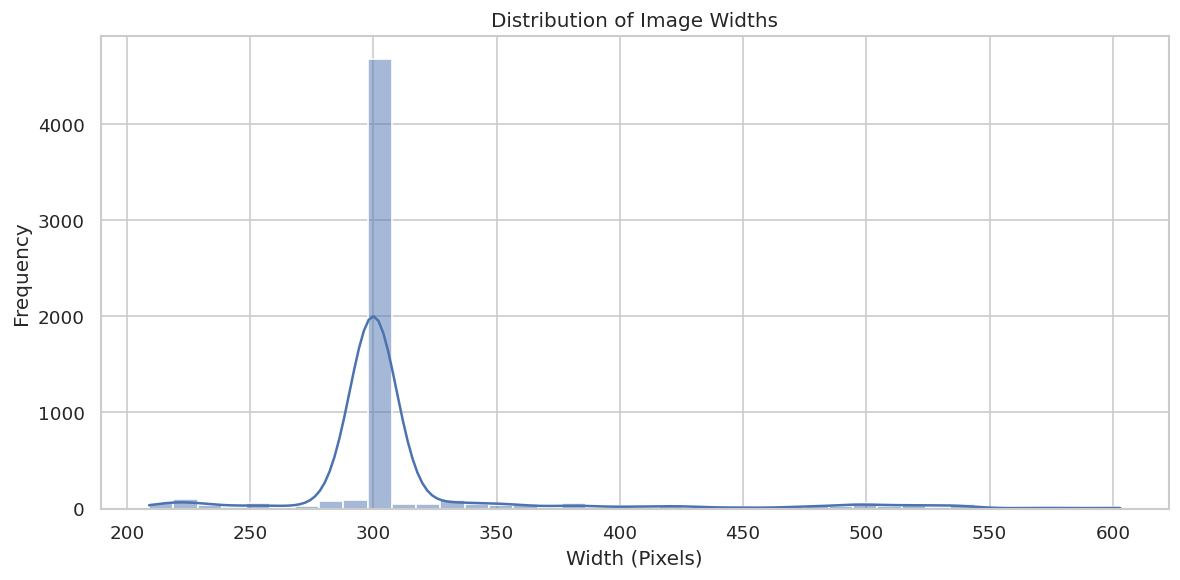

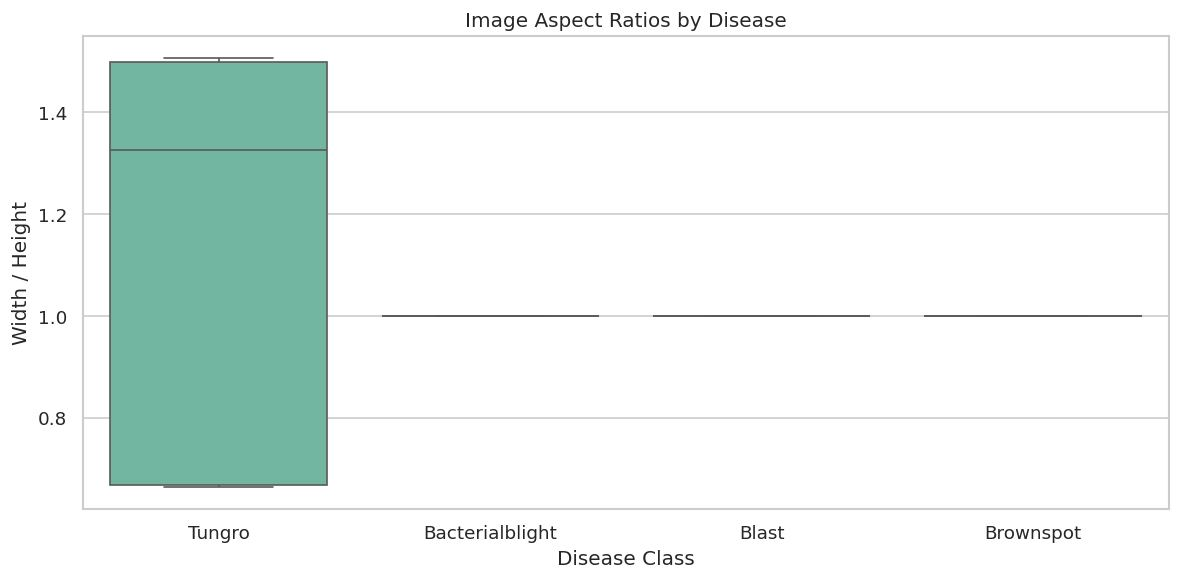

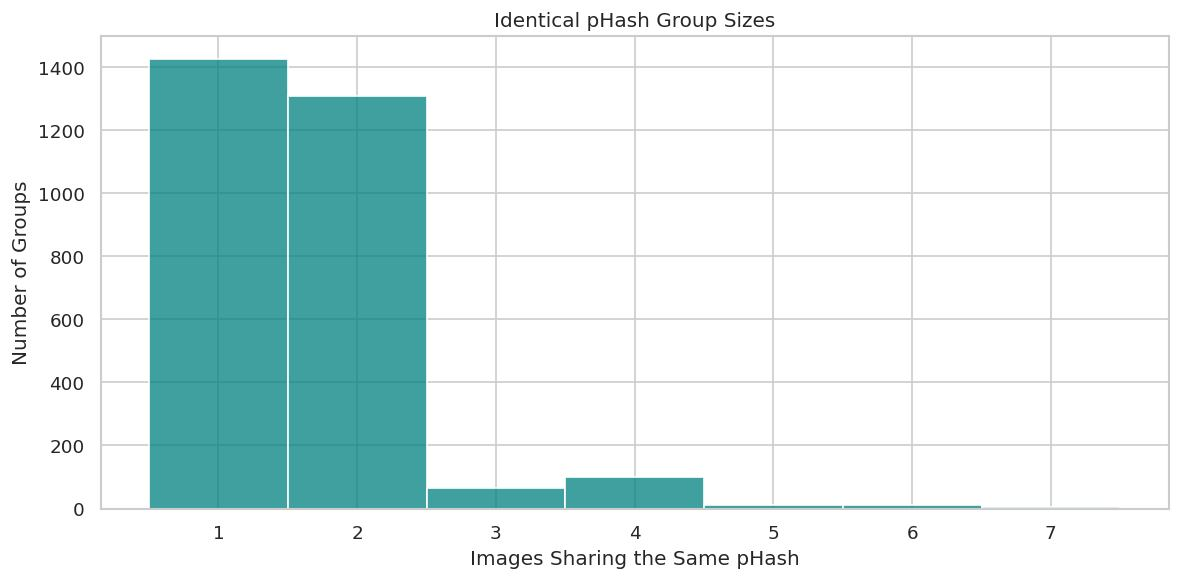

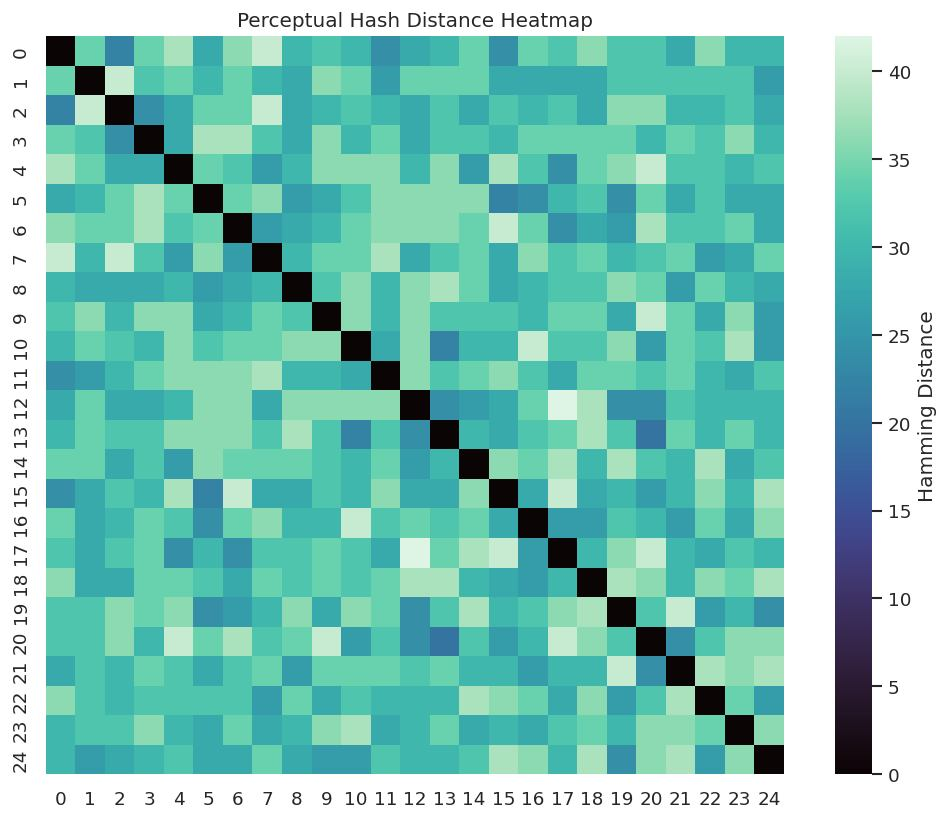

In [11]:
sns.set_theme(style="whitegrid")

# 1. Dataset distribution before and after deduplication

phash_unique_df = unique_df.drop_duplicates(
    subset="phash_str"
)

comparison = pd.DataFrame({
    "Original": eda_df["class"].value_counts(),
    "Exact-unique": unique_df["class"].value_counts(),
    "Unique pHash candidates":
        phash_unique_df["class"].value_counts()
}).fillna(0)

comparison.plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

plt.title("Dataset Distribution Across Cleaning Stages")
plt.ylabel("Image Count")
plt.xlabel("Disease Class")
plt.tight_layout()
plt.show()


# 2. Image width histogram

plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="width",
    bins=40,
    kde=True
)

plt.title("Distribution of Image Widths")
plt.xlabel("Width (Pixels)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 3. Aspect ratio boxplot

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=eda_df,
    x="class",
    y="aspect_ratio",
    hue="class",
    palette="Set2",
    legend=False
)

plt.title("Image Aspect Ratios by Disease")
plt.xlabel("Disease Class")
plt.ylabel("Width / Height")
plt.tight_layout()
plt.show()


# 4. Perceptual hash group-size histogram

group_sizes = unique_df.groupby(
    "phash_str"
).size()

plt.figure(figsize=(10, 5))

sns.histplot(
    group_sizes,
    discrete=True,
    color="teal"
)

plt.title("Identical pHash Group Sizes")
plt.xlabel("Images Sharing the Same pHash")
plt.ylabel("Number of Groups")
plt.tight_layout()
plt.show()


# 5. Perceptual hash similarity heatmap

sample = unique_df.drop_duplicates(
    "phash_str"
).sample(n=25, random_state=42)

hashes = sample["phash"].tolist()

matrix = np.array([
    [h1 - h2 for h2 in hashes]
    for h1 in hashes
])

plt.figure(figsize=(9, 7))

sns.heatmap(
    matrix,
    cmap="mako",
    square=True,
    cbar_kws={"label": "Hamming Distance"}
)

plt.title("Perceptual Hash Distance Heatmap")
plt.tight_layout()
plt.show()

### Cell 8: Inspect Near-Duplicate Groups

Shows examples of images grouped by similar perceptual hashes so the duplicate-removal decision can be checked visually.


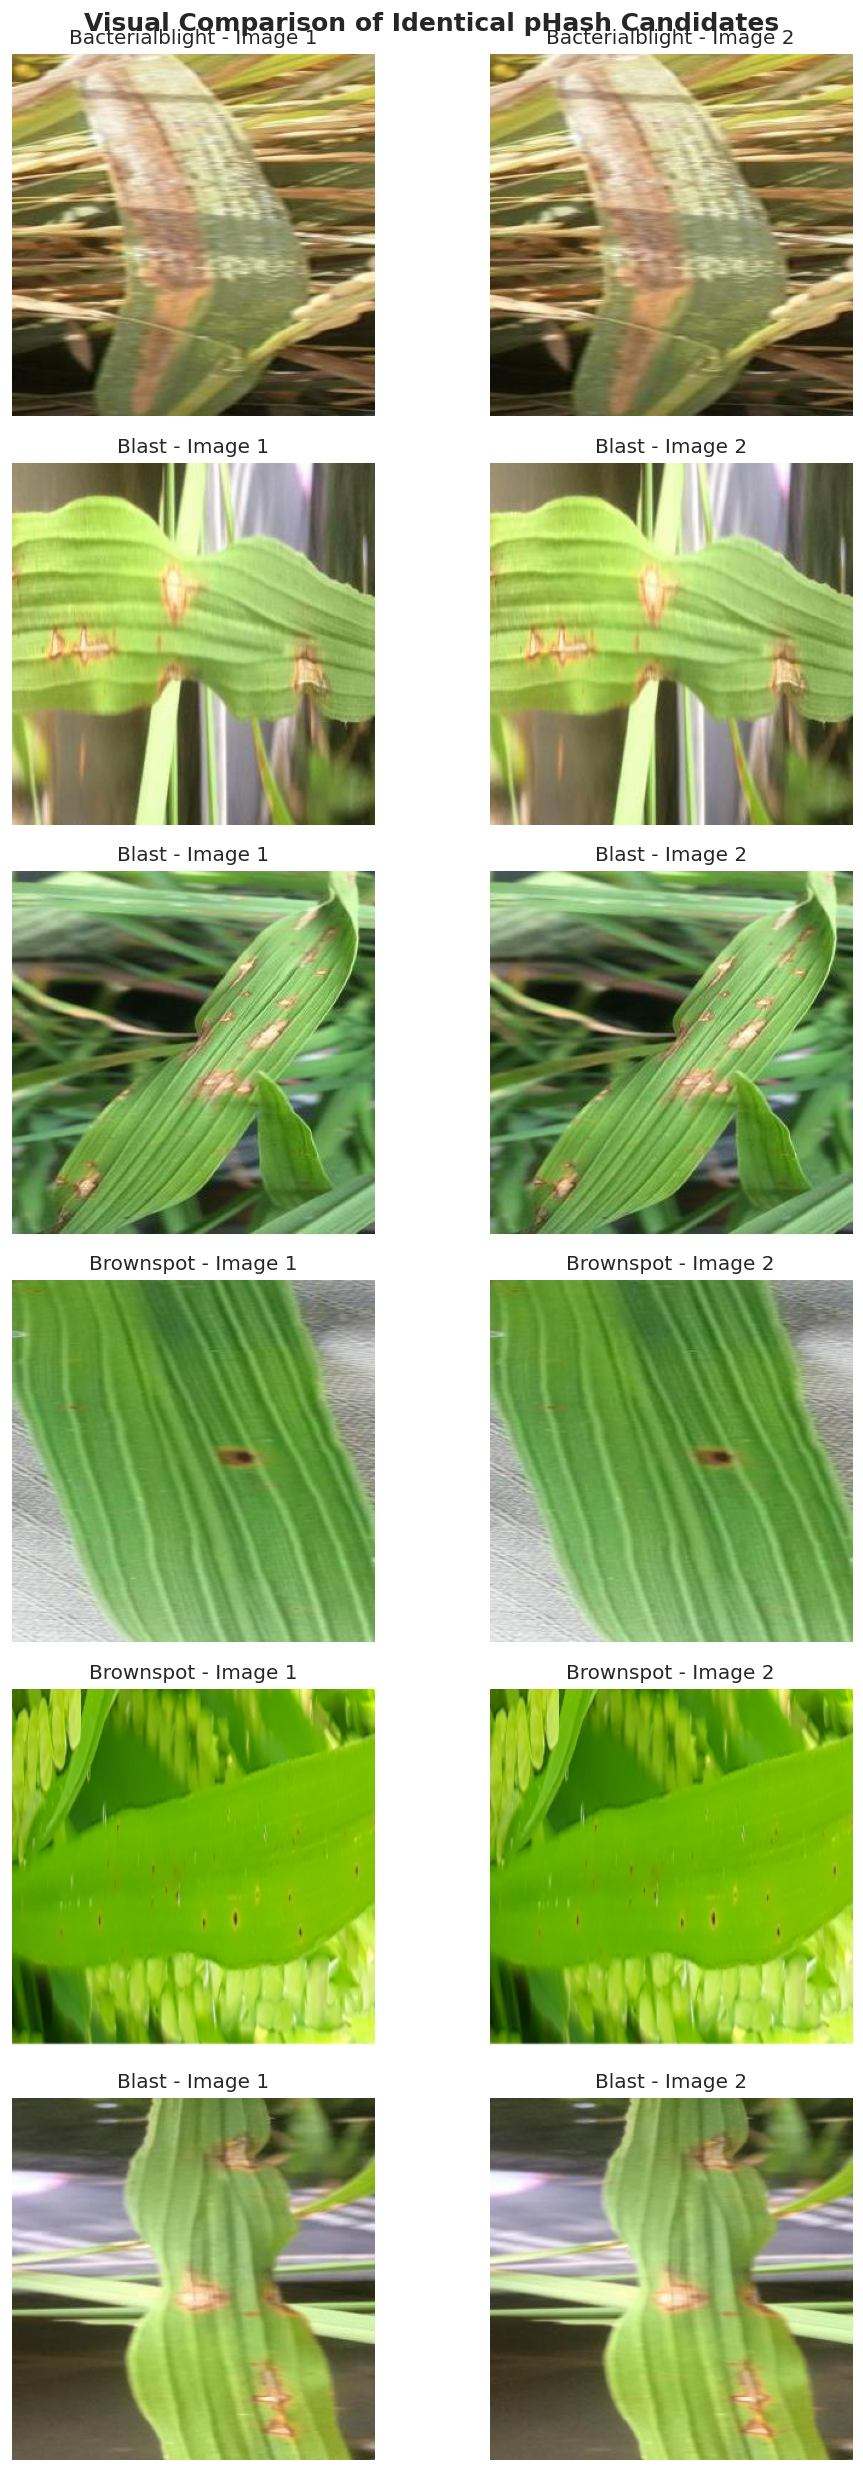

In [12]:
candidate_groups = [
    group
    for _, group in unique_df.groupby("phash_str")
    if len(group) > 1
]

rng = np.random.default_rng(42)

selected = rng.choice(
    len(candidate_groups),
    size=min(6, len(candidate_groups)),
    replace=False
)

fig, axes = plt.subplots(
    len(selected),
    2,
    figsize=(9, 3.5 * len(selected)),
    squeeze=False
)

for row, idx in enumerate(selected):

    group = candidate_groups[idx]
    paths = group["filepath"].iloc[:2].tolist()

    for col, filepath in enumerate(paths):

        with Image.open(filepath) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].axis("off")
        axes[row, col].set_title(
            f"{Path(filepath).parent.name} - Image {col + 1}"
        )

plt.suptitle(
    "Visual Comparison of Identical pHash Candidates",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Cell 9: Measure Similarity with SSIM

Calculates structural similarity scores for near-duplicate candidates to quantify how visually similar the images are.


Candidate comparisons: 1867

SSIM statistics:
count    1867.000000
mean        0.961076
std         0.070118
min         0.170375
25%         0.970092
50%         0.978178
75%         0.985900
max         1.000000
Name: ssim, dtype: float64

SSIM >= 0.99: 326
SSIM >= 0.95: 1635
SSIM < 0.95: 232


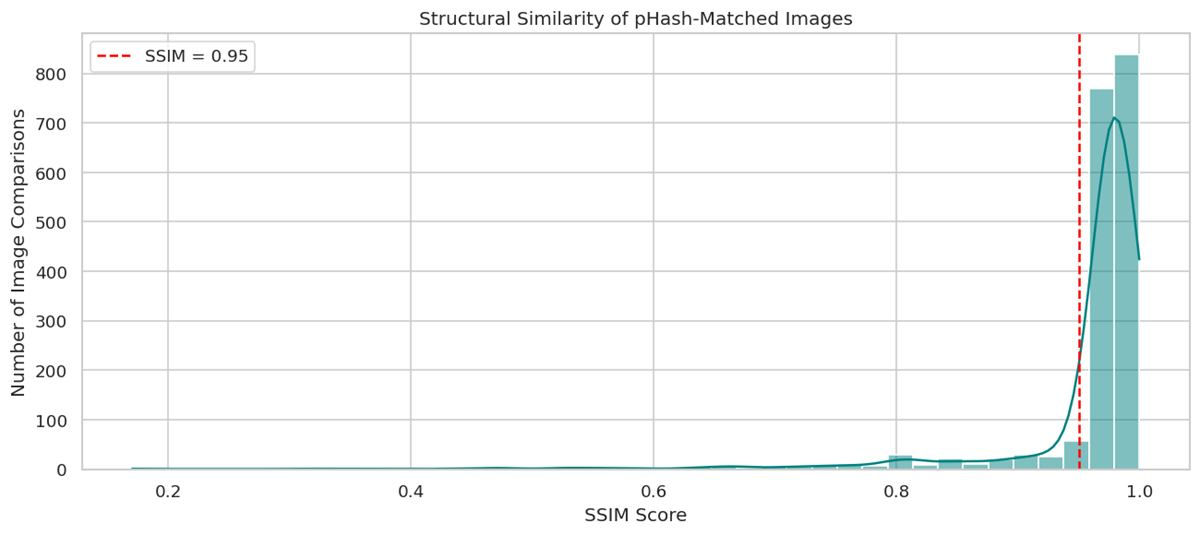

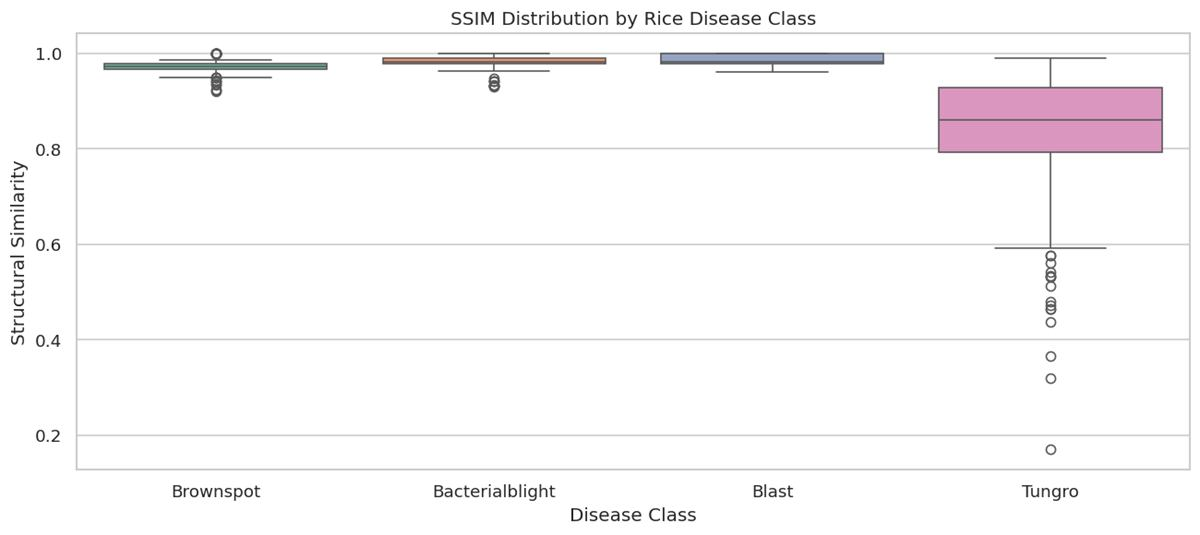

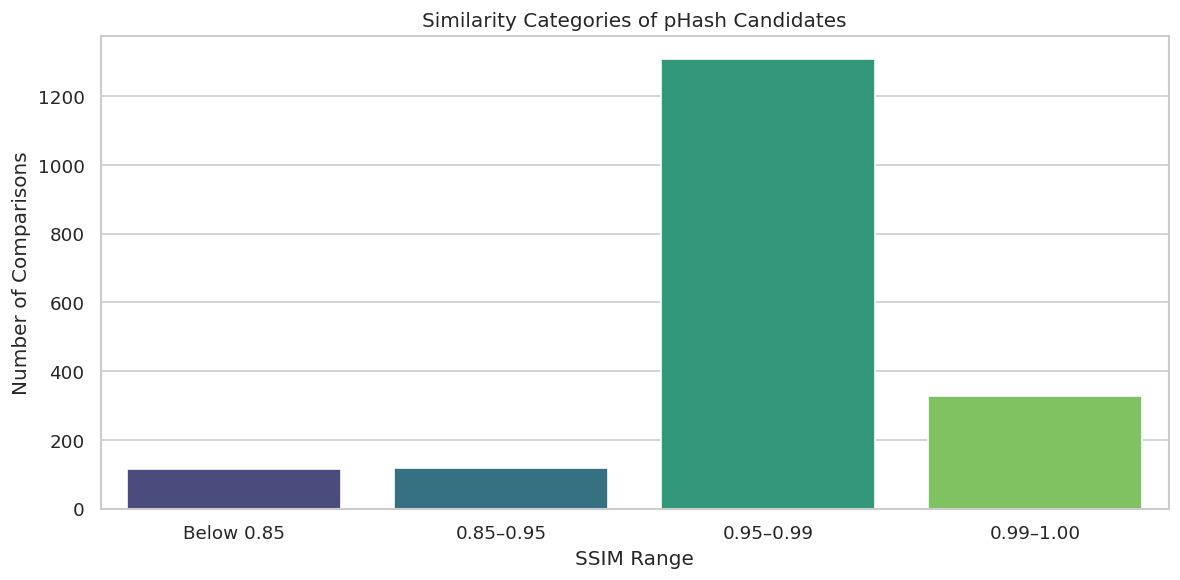

In [13]:
!pip -q install scikit-image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from skimage.metrics import structural_similarity as ssim

sns.set_theme(style="whitegrid")

def load_grayscale(filepath, size=(224, 224)):
    with Image.open(filepath) as img:
        img = img.convert("L")
        img = img.resize(size, Image.Resampling.LANCZOS)
        return np.asarray(img, dtype=np.uint8)


results = []

for phash, group in unique_df.groupby("phash_str"):

    if len(group) < 2:
        continue

    reference = group.iloc[0]
    reference_img = load_grayscale(reference["filepath"])

    for _, candidate in group.iloc[1:].iterrows():

        candidate_img = load_grayscale(
            candidate["filepath"]
        )

        similarity = ssim(
            reference_img,
            candidate_img,
            data_range=255
        )

        results.append({
            "phash": phash,
            "class": reference["class"],
            "reference": reference["filepath"],
            "candidate": candidate["filepath"],
            "ssim": similarity
        })


ssim_df = pd.DataFrame(results)

print("Candidate comparisons:", len(ssim_df))

print("\nSSIM statistics:")
print(ssim_df["ssim"].describe())

print("\nSSIM >= 0.99:",
      (ssim_df["ssim"] >= 0.99).sum())

print("SSIM >= 0.95:",
      (ssim_df["ssim"] >= 0.95).sum())

print("SSIM < 0.95:",
      (ssim_df["ssim"] < 0.95).sum())


# Diagram 1: SSIM distribution

plt.figure(figsize=(11, 5))

sns.histplot(
    data=ssim_df,
    x="ssim",
    bins=40,
    kde=True,
    color="teal"
)

plt.axvline(
    0.95,
    color="red",
    linestyle="--",
    label="SSIM = 0.95"
)

plt.title("Structural Similarity of pHash-Matched Images")
plt.xlabel("SSIM Score")
plt.ylabel("Number of Image Comparisons")
plt.legend()
plt.tight_layout()
plt.show()


# Diagram 2: SSIM by disease class

plt.figure(figsize=(11, 5))

sns.boxplot(
    data=ssim_df,
    x="class",
    y="ssim",
    hue="class",
    palette="Set2",
    legend=False
)

plt.title("SSIM Distribution by Rice Disease Class")
plt.xlabel("Disease Class")
plt.ylabel("Structural Similarity")
plt.tight_layout()
plt.show()


# Diagram 3: SSIM category counts

ssim_df["similarity_level"] = pd.cut(
    ssim_df["ssim"],
    bins=[-1, 0.85, 0.95, 0.99, 1.01],
    labels=[
        "Below 0.85",
        "0.85–0.95",
        "0.95–0.99",
        "0.99–1.00"
    ]
)

plt.figure(figsize=(10, 5))

sns.countplot(
    data=ssim_df,
    x="similarity_level",
    hue="similarity_level",
    palette="viridis",
    legend=False
)

plt.title("Similarity Categories of pHash Candidates")
plt.xlabel("SSIM Range")
plt.ylabel("Number of Comparisons")
plt.tight_layout()
plt.show()

### Cell 10: Review Lowest-SSIM Pairs

Displays the least similar candidate pairs to verify whether the perceptual-hash grouping is still reasonable.


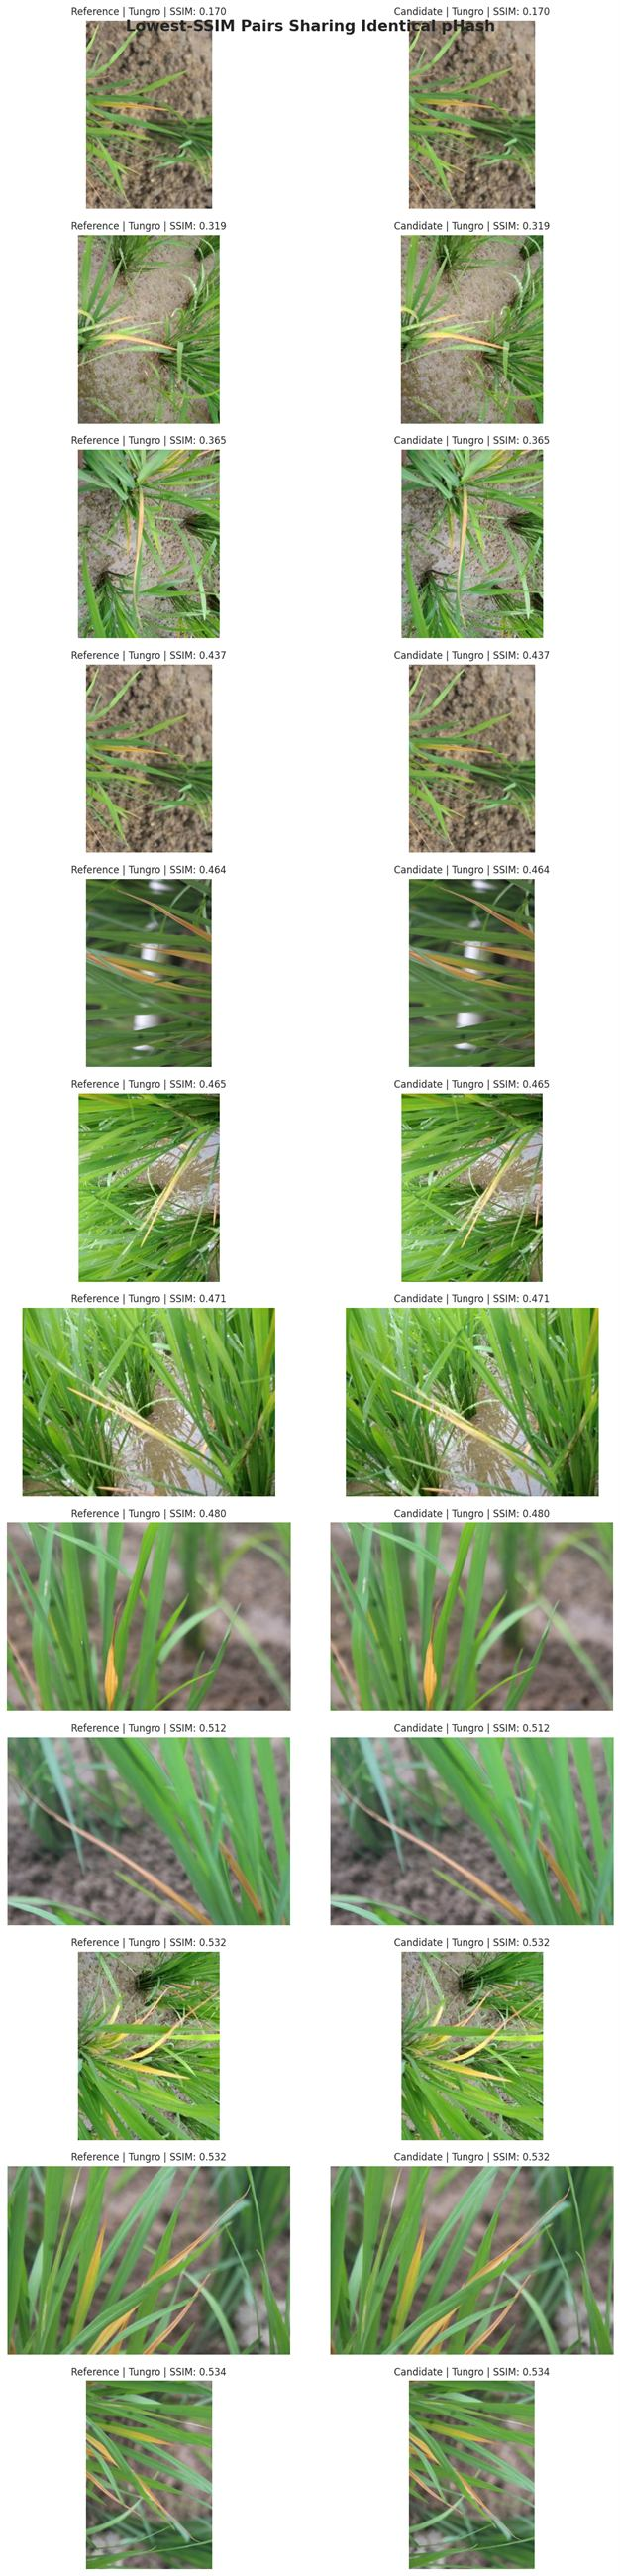

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Select the 12 lowest-SSIM comparisons
suspicious = ssim_df.nsmallest(12, "ssim")

fig, axes = plt.subplots(
    12, 2,
    figsize=(10, 38)
)

for row, (_, record) in enumerate(suspicious.iterrows()):

    for col, field in enumerate(["reference", "candidate"]):

        filepath = record[field]

        with Image.open(filepath) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].axis("off")

        axes[row, col].set_title(
            f"{'Reference' if col == 0 else 'Candidate'} "
            f"| {record['class']} "
            f"| SSIM: {record['ssim']:.3f}",
            fontsize=10
        )

plt.suptitle(
    "Lowest-SSIM Pairs Sharing Identical pHash",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 3. Cleaned Representative Dataset

One representative image is retained from each duplicate or highly similar image group. This creates a cleaner dataset while preserving the disease classes needed for model training and evaluation.


### Cell 11: Build Clean Representative Dataset

Creates the first cleaned dataframe by keeping one representative image from each identical perceptual-hash group.


In [15]:
# One representative per identical pHash group
clean_df = (
    unique_df
    .sort_values("filepath")
    .drop_duplicates(subset="phash_str")
    .reset_index(drop=True)
)

print("Original images:", len(eda_df))
print("After exact deduplication:", len(unique_df))
print("Provisional pHash-unique images:", len(clean_df))

print("\nClass distribution:")
print(clean_df["class"].value_counts())

Original images: 5932
After exact deduplication: 4794
Provisional pHash-unique images: 2927

Class distribution:
class
Tungro             1060
Brownspot           757
Bacterialblight     569
Blast               541
Name: count, dtype: int64


### Cell 12: Plot Cleaned Class Distribution

Plots the class balance after duplicate removal to check whether the dataset is still usable for supervised training.


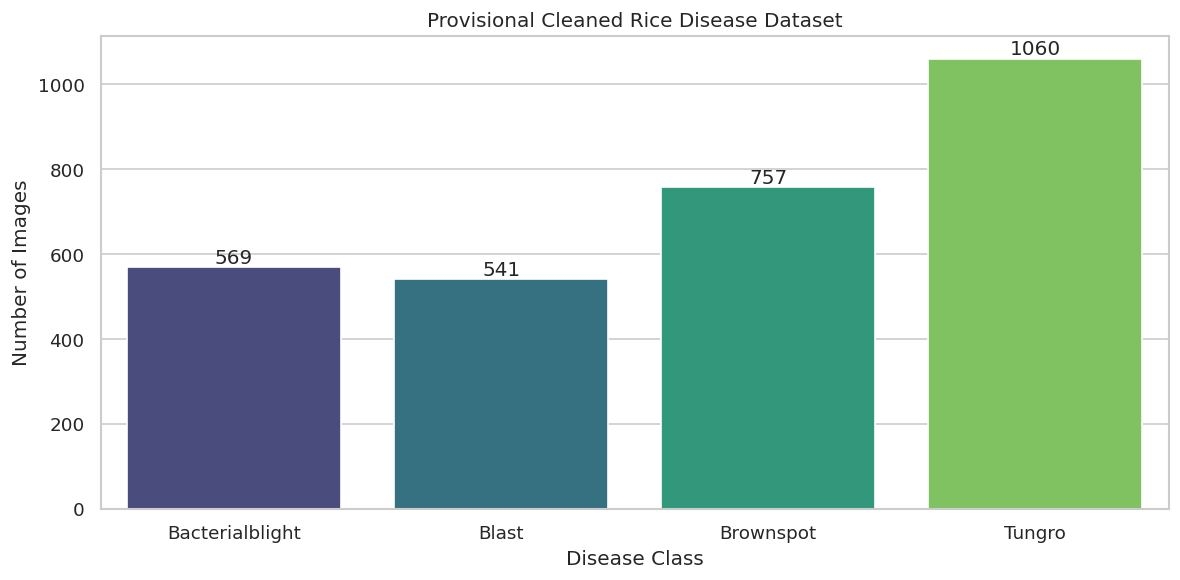

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

ax = sns.countplot(
    data=clean_df,
    x="class",
    hue="class",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Provisional Cleaned Rice Disease Dataset")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

### Cell 13: Find Near-Duplicate Distances

Computes Hamming distances between perceptual hashes to identify remaining near-duplicate image pairs.


In [17]:
!pip -q install scipy

import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist

# One representative per pHash
representatives = clean_df.reset_index(drop=True).copy()

# Convert hexadecimal perceptual hashes to bit arrays
def hash_to_bits(hash_str):
    number = int(hash_str, 16)
    return np.array(
        [(number >> i) & 1 for i in range(63, -1, -1)],
        dtype=np.uint8
    )

hash_bits = np.stack([
    hash_to_bits(h)
    for h in representatives["phash_str"]
])

# Calculate pairwise Hamming distances
# scipy returns normalized Hamming distance
distances = pdist(hash_bits, metric="hamming") * 64

# Reconstruct only candidate pairs
candidate_indices = np.where(distances <= 5)[0]

n = len(representatives)

# Convert condensed matrix indices to pairs
def condensed_to_pair(k, n):
    i = n - 2 - np.floor(
        np.sqrt(-8*k + 4*n*(n-1)-7)/2 - 0.5
    ).astype(int)

    j = k + i + 1 - n*(n-1)//2 + (
        (n-i)*(n-i-1)
    )//2

    return int(i), int(j)

near_duplicate_pairs = []

for index in candidate_indices:
    i, j = condensed_to_pair(index, n)

    if i == j:
        continue

    near_duplicate_pairs.append({
        "image_1": representatives.iloc[i]["filepath"],
        "image_2": representatives.iloc[j]["filepath"],
        "class_1": representatives.iloc[i]["class"],
        "class_2": representatives.iloc[j]["class"],
        "distance": int(round(distances[index]))
    })

near_df = pd.DataFrame(near_duplicate_pairs)

print("Candidate near-duplicate pairs:", len(near_df))

if not near_df.empty:
    print("\nHamming distance distribution:")
    print(near_df["distance"].value_counts().sort_index())

    print("\nCross-class candidate pairs:")
    print(
        (near_df["class_1"] != near_df["class_2"]).sum()
    )

Candidate near-duplicate pairs: 1151

Hamming distance distribution:
distance
2    715
4    436
Name: count, dtype: int64

Cross-class candidate pairs:
0


### Cell 14: Visualize Near-Duplicate Distances

Plots the distribution of near-duplicate distances so the chosen similarity threshold can be understood.


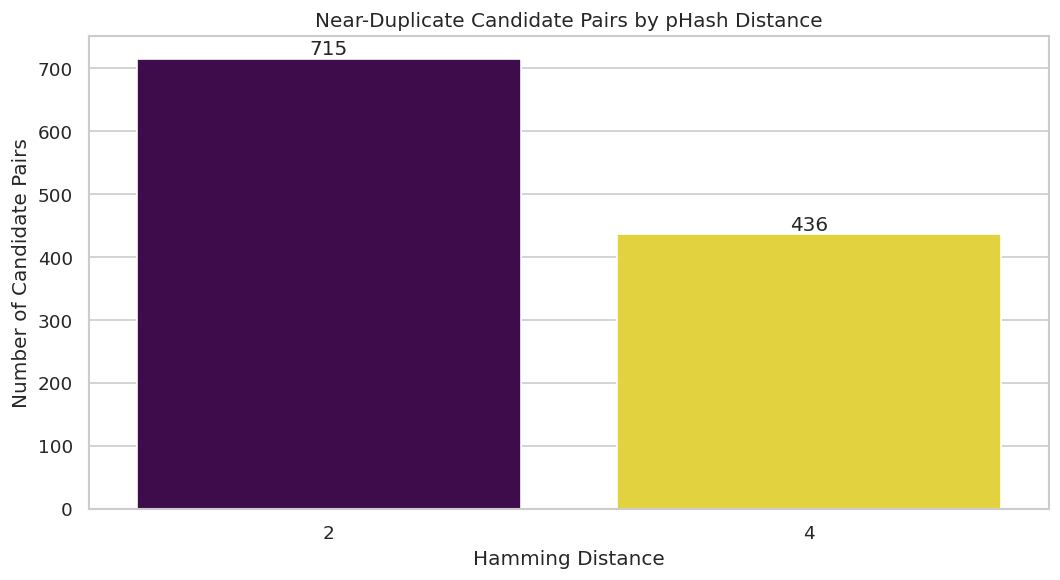

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

if not near_df.empty:
    plt.figure(figsize=(9, 5))

    ax = sns.countplot(
        data=near_df,
        x="distance",
        hue="distance",
        palette="viridis",
        legend=False
    )

    for container in ax.containers:
        ax.bar_label(container)

    plt.title("Near-Duplicate Candidate Pairs by pHash Distance")
    plt.xlabel("Hamming Distance")
    plt.ylabel("Number of Candidate Pairs")

    plt.tight_layout()
    plt.show()

### Cell 15: Inspect Near-Duplicate Examples

Displays near-duplicate examples and confirms whether similar images cross disease-class boundaries.


Cross-class candidate pairs: 0


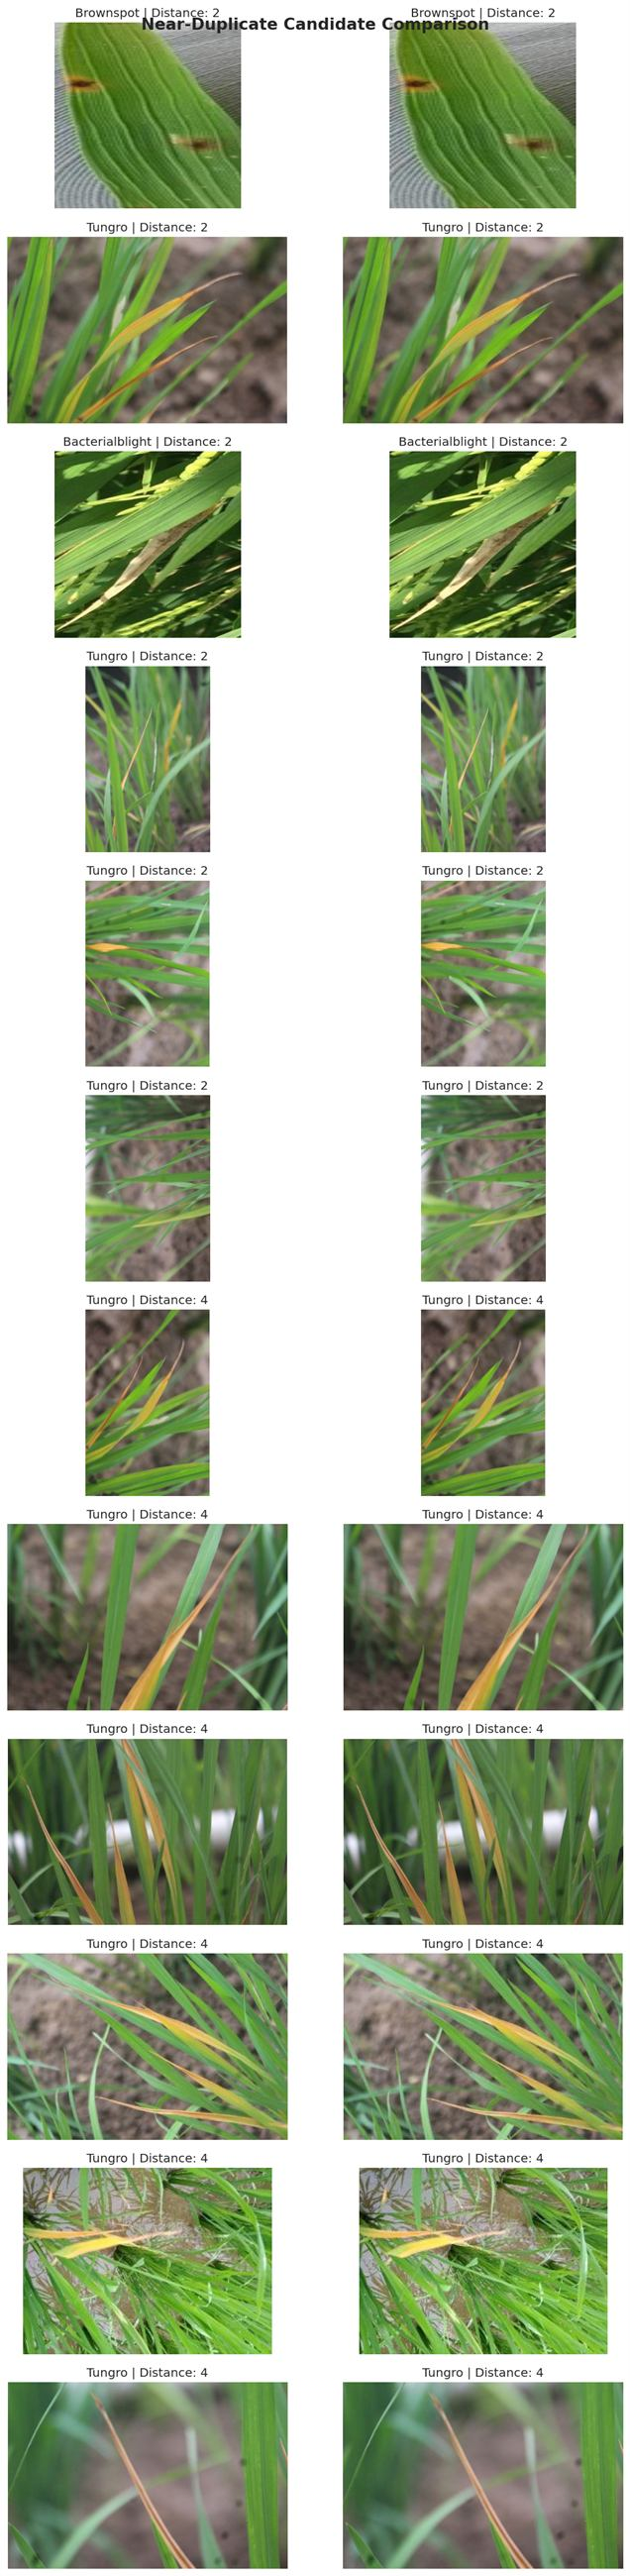

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("Cross-class candidate pairs:",
      (near_df["class_1"] != near_df["class_2"]).sum())

fig, axes = plt.subplots(
    12, 2,
    figsize=(10, 36)
)

row = 0

for distance in [2, 4]:

    subset = near_df[
        near_df["distance"] == distance
    ]

    samples = subset.sample(
        n=min(6, len(subset)),
        random_state=42
    )

    for _, pair in samples.iterrows():

        for col, field in enumerate(["image_1", "image_2"]):

            with Image.open(pair[field]) as img:
                axes[row, col].imshow(img.convert("RGB"))

            axes[row, col].axis("off")
            axes[row, col].set_title(
                f"{pair[f'class_{col+1}']} "
                f"| Distance: {distance}"
            )

        row += 1

for remaining in range(row, 12):
    for col in range(2):
        axes[remaining, col].axis("off")

plt.suptitle(
    "Near-Duplicate Candidate Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Cell 16: Create Similarity Groups

Uses a union-find structure to merge connected near-duplicate pairs into similarity groups.


In [20]:
import numpy as np
import pandas as pd
from collections import Counter

# Union-Find data structure
class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
        self.rank = [0] * n

    def find(self, x):
        if self.parent[x] != x:
            self.parent[x] = self.find(self.parent[x])
        return self.parent[x]

    def union(self, a, b):
        root_a = self.find(a)
        root_b = self.find(b)

        if root_a == root_b:
            return

        if self.rank[root_a] < self.rank[root_b]:
            root_a, root_b = root_b, root_a

        self.parent[root_b] = root_a

        if self.rank[root_a] == self.rank[root_b]:
            self.rank[root_a] += 1


group_df = clean_df.reset_index(drop=True).copy()

uf = UnionFind(len(group_df))

path_to_index = {
    path: i
    for i, path in enumerate(group_df["filepath"])
}

# Join candidates with pHash distance <= 4
for _, pair in near_df.iterrows():
    a = path_to_index[pair["image_1"]]
    b = path_to_index[pair["image_2"]]

    if pair["distance"] <= 4:
        uf.union(a, b)

group_df["similarity_group"] = [
    uf.find(i)
    for i in range(len(group_df))
]

group_sizes = group_df.groupby(
    "similarity_group"
).size()

print("Provisional pHash representatives:", len(group_df))
print("Similarity groups:", group_sizes.shape[0])
print("Largest group:", group_sizes.max())

print("\nGroup size distribution:")
print(group_sizes.value_counts().sort_index())

# Check groups for conflicting disease labels
conflicting_groups = (
    group_df.groupby("similarity_group")["class"]
    .nunique()
)

print("\nGroups containing multiple classes:",
      (conflicting_groups > 1).sum())

Provisional pHash representatives: 2927
Similarity groups: 2138
Largest group: 11

Group size distribution:
1     1656
2      351
3       48
4       33
5       28
6       10
7        6
8        5
11       1
Name: count, dtype: int64

Groups containing multiple classes: 0


### Cell 17: Plot Similarity Group Sizes

Shows how many images appear in each similarity group and whether any groups are unusually large.


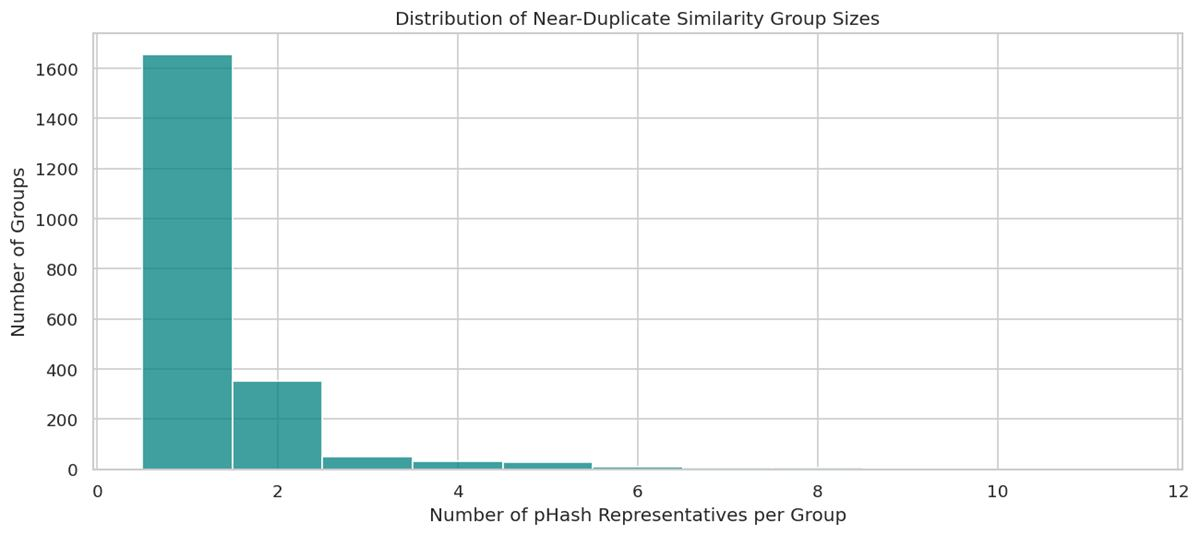

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(11, 5))

sns.histplot(
    group_sizes,
    discrete=True,
    color="teal"
)

plt.title("Distribution of Near-Duplicate Similarity Group Sizes")
plt.xlabel("Number of pHash Representatives per Group")
plt.ylabel("Number of Groups")

plt.tight_layout()
plt.show()

### Cell 18: Inspect Largest Similarity Groups

Displays the largest similarity groups to manually check that grouped images really belong together.


Total similarity groups: 2138
Largest group size: 11

Largest groups:
similarity_group
2067    11
2260     8
2395     8
2719     8
2483     8
dtype: int64

Groups containing multiple disease classes: 0


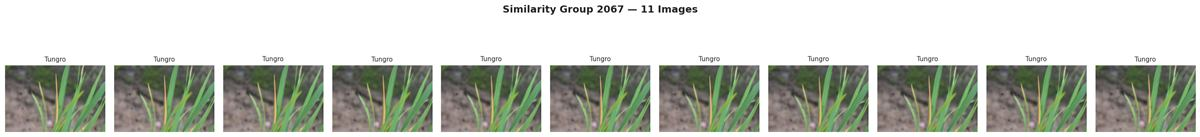

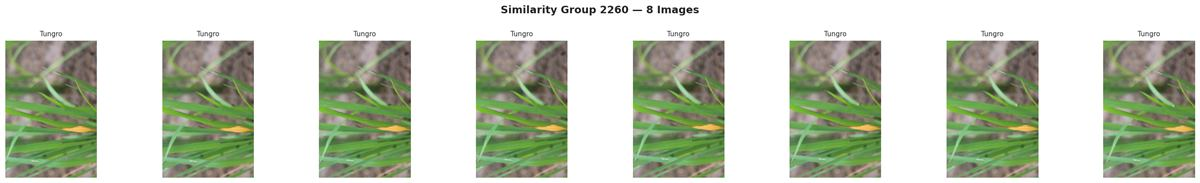

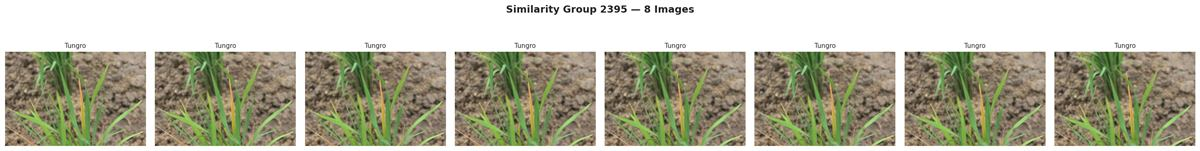

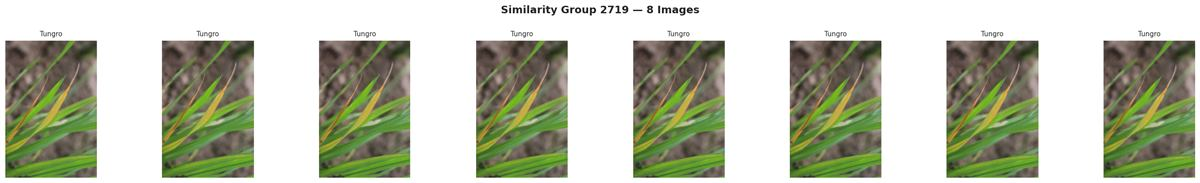

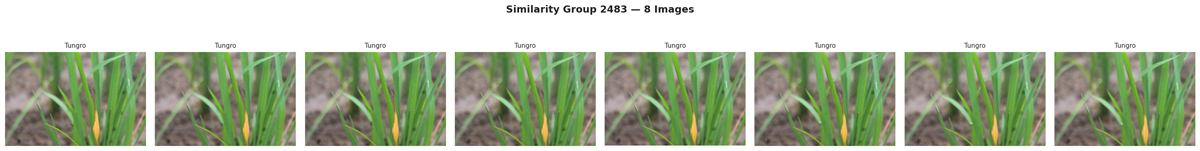

In [22]:
import matplotlib.pyplot as plt
from PIL import Image

# Find five largest groups
largest_groups = (
    group_df.groupby("similarity_group")
    .size()
    .sort_values(ascending=False)
    .head(5)
)

print("Total similarity groups:", group_sizes.shape[0])
print("Largest group size:", group_sizes.max())

print("\nLargest groups:")
print(largest_groups)

conflicting = (
    group_df.groupby("similarity_group")["class"]
    .nunique()
)

print("\nGroups containing multiple disease classes:",
      (conflicting > 1).sum())

# Visualize members of each large group
for group_id in largest_groups.index:

    members = group_df[
        group_df["similarity_group"] == group_id
    ]

    n = len(members)

    fig, axes = plt.subplots(
        1, n,
        figsize=(min(3 * n, 24), 3.5),
        squeeze=False
    )

    for j, (_, row) in enumerate(members.iterrows()):

        with Image.open(row["filepath"]) as img:
            axes[0, j].imshow(img.convert("RGB"))

        axes[0, j].set_title(
            row["class"],
            fontsize=9
        )
        axes[0, j].axis("off")

    plt.suptitle(
        f"Similarity Group {group_id} — {n} Images",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

### Cell 19: Build Clean Representative Dataset

Creates the first cleaned dataframe by keeping one representative image from each identical perceptual-hash group.


Original images: 5932
Exact unique images: 4794
pHash representatives: 2927
Final provisional representatives: 2138

Final class distribution:
class
Brownspot          606
Tungro             538
Bacterialblight    514
Blast              480
Name: count, dtype: int64

Missing values:
filepath    0
class       0
dtype: int64

Duplicate similarity groups: 0


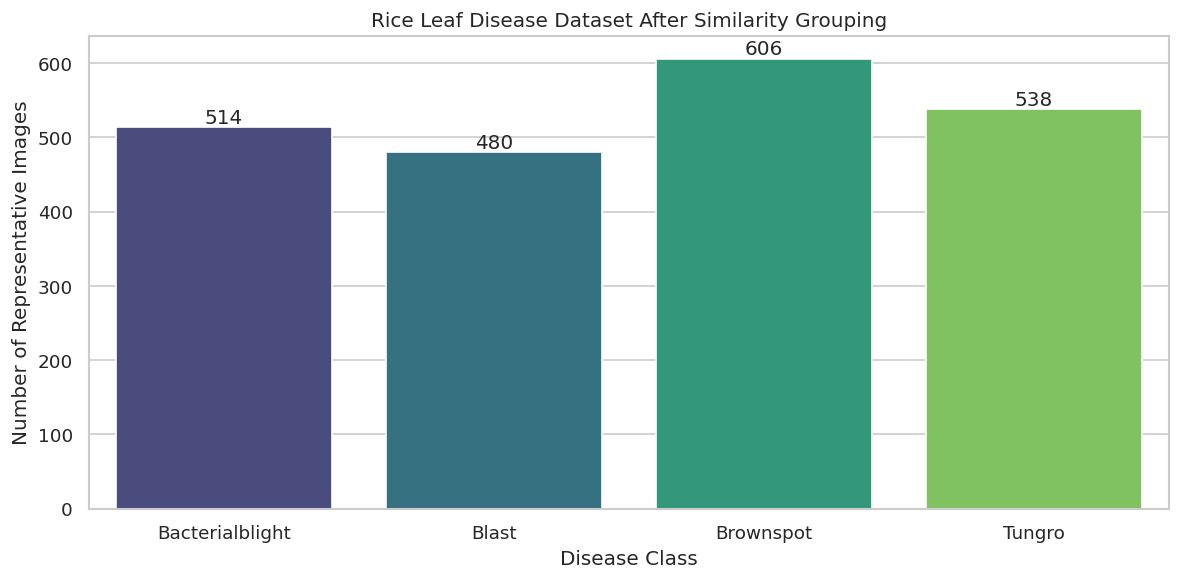

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select one representative from each similarity group
final_df = (
    group_df
    .sort_values("filepath")
    .drop_duplicates(subset="similarity_group")
    .reset_index(drop=True)
    .copy()
)

print("Original images:", len(eda_df))
print("Exact unique images:", len(unique_df))
print("pHash representatives:", len(clean_df))
print("Final provisional representatives:", len(final_df))

print("\nFinal class distribution:")
print(final_df["class"].value_counts())

print("\nMissing values:")
print(final_df[["filepath", "class"]].isnull().sum())

print("\nDuplicate similarity groups:",
      final_df["similarity_group"].duplicated().sum())

# Visualize final class balance
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

ax = sns.countplot(
    data=final_df,
    x="class",
    hue="class",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Rice Leaf Disease Dataset After Similarity Grouping")
plt.xlabel("Disease Class")
plt.ylabel("Number of Representative Images")
plt.tight_layout()
plt.show()

## 4. Initial Train, Validation, and Test Split

The cleaned dataset is split into training, validation, and testing partitions. The split is checked for overlap so that the same file or similarity group does not appear across partitions.


### Cell 20: Create Initial Train Validation Test Split

Splits the representative dataset into training, validation, and testing sets with stratification by disease class.


In [24]:
from sklearn.model_selection import train_test_split
import pandas as pd

SEED = 42

# 70% training, 30% temporary
train_df, temp_df = train_test_split(
    final_df,
    test_size=0.30,
    stratify=final_df["class"],
    random_state=SEED
)

# Split temporary data into 15% validation and 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

# Confirm no path or similarity-group overlap
for column in ["filepath", "similarity_group"]:
    train_set = set(train_df[column])
    val_set = set(val_df[column])
    test_set = set(test_df[column])

    assert not (train_set & val_set)
    assert not (train_set & test_set)
    assert not (val_set & test_set)

print("\nNo filepath or similarity-group overlap detected.")

print("\nTraining class distribution:")
print(train_df["class"].value_counts())

print("\nValidation class distribution:")
print(val_df["class"].value_counts())

print("\nTesting class distribution:")
print(test_df["class"].value_counts())

Training images: 1496
Validation images: 321
Testing images: 321
Total: 2138

No filepath or similarity-group overlap detected.

Training class distribution:
class
Brownspot          424
Tungro             376
Bacterialblight    360
Blast              336
Name: count, dtype: int64

Validation class distribution:
class
Brownspot          91
Tungro             81
Bacterialblight    77
Blast              72
Name: count, dtype: int64

Testing class distribution:
class
Brownspot          91
Tungro             81
Bacterialblight    77
Blast              72
Name: count, dtype: int64


### Cell 21: Visualize Split Distribution

Plots class counts across train, validation, and test partitions to verify class balance.


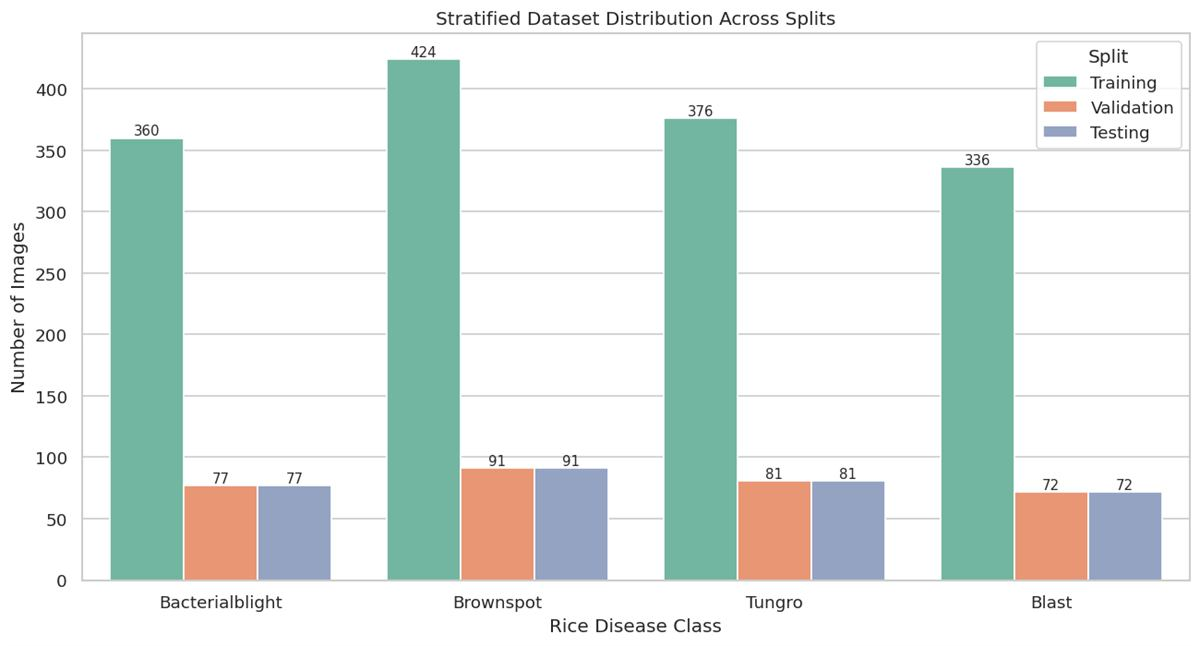

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

split_data = pd.concat([
    train_df.assign(Split="Training"),
    val_df.assign(Split="Validation"),
    test_df.assign(Split="Testing")
])

plt.figure(figsize=(11, 6))

ax = sns.countplot(
    data=split_data,
    x="class",
    hue="Split",
    palette="Set2"
)

for container in ax.containers:
    ax.bar_label(container, fontsize=9)

plt.title("Stratified Dataset Distribution Across Splits")
plt.xlabel("Rice Disease Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

### Cell 22: Save Split Manifests

Mounts Google Drive in Colab and saves CSV manifest files for the dataset splits.


In [26]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

output_dir = Path(
    "/content/drive/MyDrive/Rice_CNN_Project/dataset_splits"
)

output_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(output_dir / "train.csv", index=False)
val_df.to_csv(output_dir / "validation.csv", index=False)
test_df.to_csv(output_dir / "test.csv", index=False)

print("Split manifests saved:", output_dir)

Mounted at /content/drive
Split manifests saved: /content/drive/MyDrive/Rice_CNN_Project/dataset_splits


## 5. TensorFlow Input Pipeline

Images are resized to 224 x 224, normalized to the 0-1 range, batched, and prefetched. This section also verifies shapes, labels, and pixel-value ranges before model training.


### Cell 23: Define TensorFlow Class Mapping

Defines image size, batch size, class names, and the numeric label mapping used consistently across experiments.


In [27]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Fixed mapping used for all experiments
class_names = sorted(final_df["class"].unique())
class_to_index = {
    name: i for i, name in enumerate(class_names)
}

print("Class mapping:", class_to_index)

def preprocess_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)

    # Supports JPG, PNG and other compatible image formats.
    # Converts grayscale/RGBA to RGB.
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Preserve original aspect ratio using padding
    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE,
        IMG_SIZE,
        method="bilinear"
    )

    # Normalize pixels to [0, 1]
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

Class mapping: {'Bacterialblight': 0, 'Blast': 1, 'Brownspot': 2, 'Tungro': 3}


### Cell 24: Define TensorFlow Class Mapping

Defines image size, batch size, class names, and the numeric label mapping used consistently across experiments.


In [28]:
def create_dataset(dataframe, training=False):

    paths = dataframe["filepath"].astype(str).to_numpy()

    labels = dataframe["class"].map(
        class_to_index
    ).to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

for images, labels in train_ds.take(1):
    print("\nImage batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel minimum:", tf.reduce_min(images).numpy())
    print("Pixel maximum:", tf.reduce_max(images).numpy())

Training batches: 47
Validation batches: 11
Testing batches: 11

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel minimum: 0.0
Pixel maximum: 1.0


### Cell 25: Preview Training Batch

Displays a batch of preprocessed training images to confirm that labels and image loading look correct.


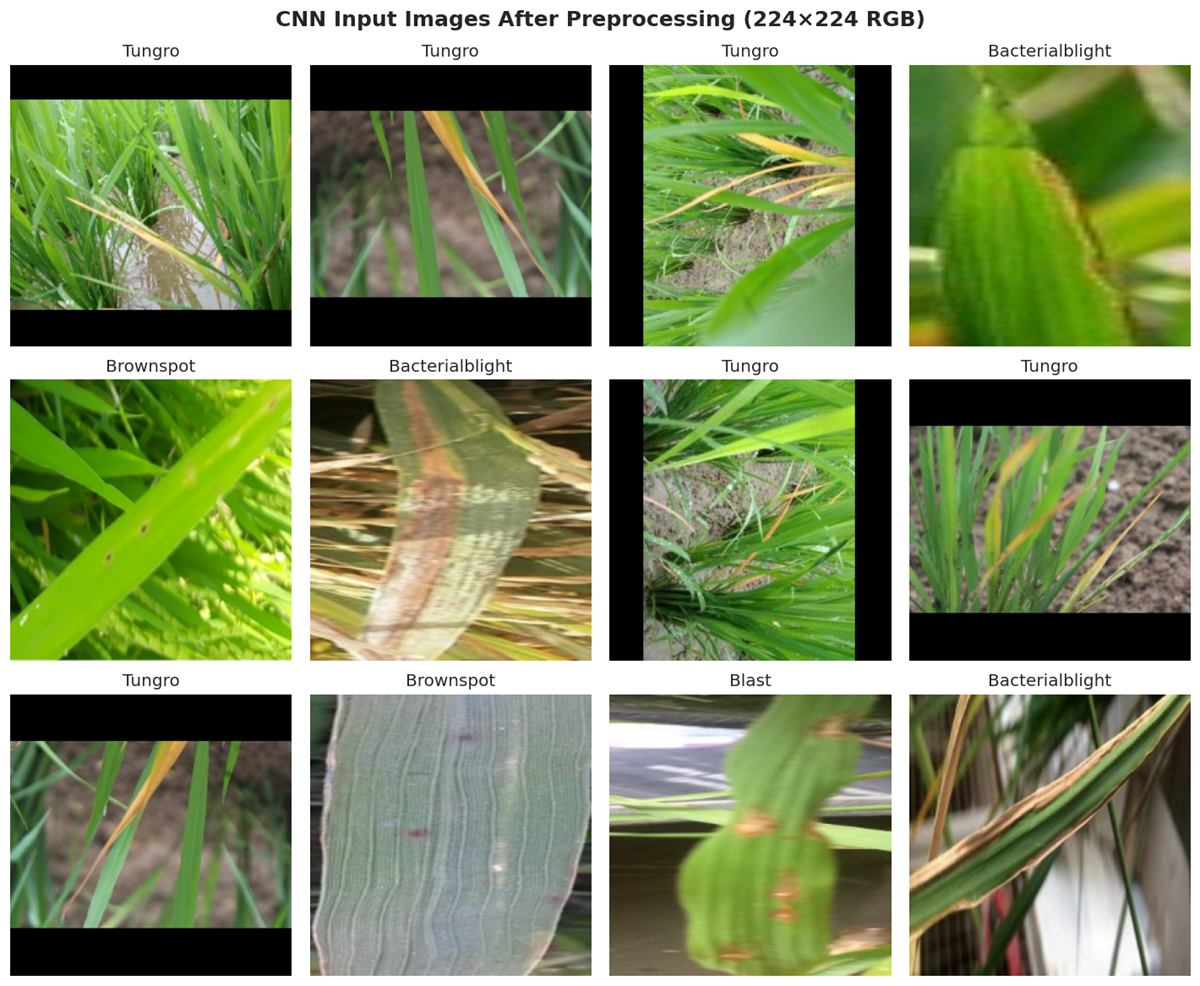

In [29]:
fig, axes = plt.subplots(3, 4, figsize=(12, 10))

for images, labels in train_ds.take(1):

    for i, ax in enumerate(axes.flat):

        ax.imshow(images[i].numpy())
        ax.set_title(class_names[int(labels[i])])
        ax.axis("off")

plt.suptitle(
    "CNN Input Images After Preprocessing (224×224 RGB)",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Cell 26: Validate Input Pipeline

Checks batch shapes and normalized pixel ranges for the train, validation, and test datasets.


In [30]:
for dataset_name, dataset in [
    ("Training", train_ds),
    ("Validation", val_ds),
    ("Testing", test_ds)
]:
    for images, labels in dataset.take(1):

        assert images.shape[1:] == (224, 224, 3)
        assert images.dtype == tf.float32

        assert tf.reduce_min(images).numpy() >= 0.0
        assert tf.reduce_max(images).numpy() <= 1.0

        assert tf.reduce_min(labels).numpy() >= 0
        assert tf.reduce_max(labels).numpy() < 4

    print(f"{dataset_name}: PASSED")

print("\nPreprocessing validation completed.")

Training: PASSED
Validation: PASSED
Testing: PASSED

Preprocessing validation completed.


## 6. CNN V1: Baseline Model

The first custom CNN establishes a baseline using convolution, pooling, and dense layers. Its validation performance gives a reference point for later model improvements.


### Cell 27: Build CNN V1 Baseline

Defines the first custom CNN architecture. This baseline model is used as the reference for later V2, V3, V4, and V5 experiments.


In [31]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

def build_baseline_cnn():

    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),

        # Block 1
        layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same",
            name="conv_block_1"
        ),
        layers.MaxPooling2D((2, 2)),

        # Block 2
        layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same",
            name="conv_block_2"
        ),
        layers.MaxPooling2D((2, 2)),

        # Block 3
        layers.Conv2D(
            128, (3, 3),
            activation="relu",
            padding="same",
            name="conv_block_3"
        ),
        layers.MaxPooling2D((2, 2)),

        # Classification head
        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dense(
            4,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


cnn_v1 = build_baseline_cnn()

cnn_v1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_block_1 (Conv2D)           │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_2 (Conv2D)           │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_3 (Conv2D)           │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

### Cell 28: Train CNN V1 Baseline

Trains CNN V1 with early stopping and checkpointing, then stores the training history for comparison.


In [32]:
from pathlib import Path

MODEL_DIR = Path("/content/rice_cnn_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

callbacks_v1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "cnn_v1_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(MODEL_DIR / "cnn_v1_training.csv")
    )
]

history_v1 = cnn_v1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_v1,
    verbose=1
)

print("Baseline training completed.")

Epoch 1/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.4250 - loss: 1.3041
Epoch 1: val_loss improved from None to 0.80430, saving model to /content/rice_cnn_models/cnn_v1_best.keras

Epoch 1: finished saving model to /content/rice_cnn_models/cnn_v1_best.keras
47/47 ━━━━━━━━━━━━━━━━━━━━ 25s 277ms/step - accuracy: 0.5040 - loss: 1.1776 - val_accuracy: 0.7072 - val_loss: 0.8043
Epoch 2/40
46/47 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.6769 - loss: 0.7448
Epoch 2: val_loss improved from 0.80430 to 0.63022, saving model to /content/rice_cnn_models/cnn_v1_best.keras

Epoch 2: finished saving model to /content/rice_cnn_models/cnn_v1_best.keras
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.6852 - loss: 0.7147 - val_accuracy: 0.6854 - val_loss: 0.6302
Epoch 3/40
46/47 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.7085 - loss: 0.6088
Epoch 3: val_loss improved from 0.63022 to 0.60050, saving model to /content/rice_cnn_models/cnn_v1_best.keras

Epoch 3: finished savin

### Cell 29: Plot CNN V1 Training Curves

Plots CNN V1 accuracy and loss curves and reports its best validation accuracy, lowest validation loss, and completed epochs.


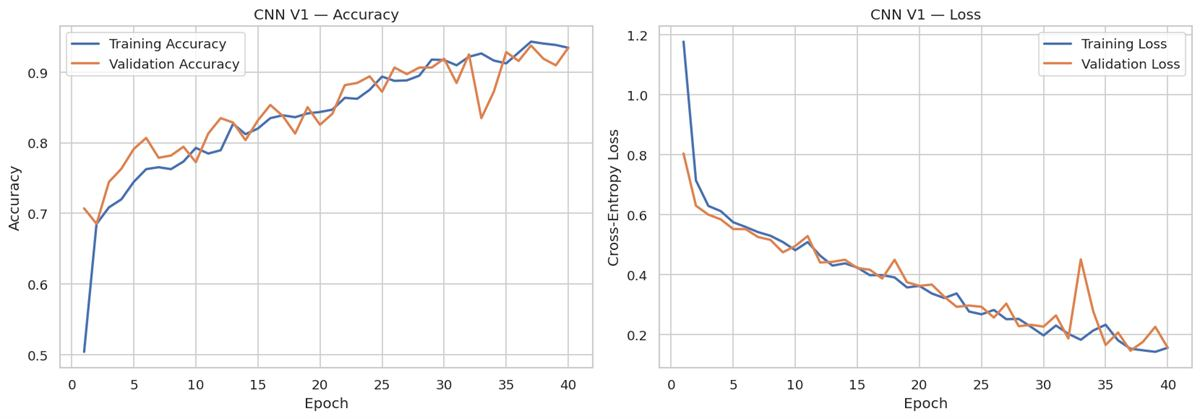

Best validation accuracy: 0.9376947283744812
Lowest validation loss: 0.146468386054039
Epochs completed: 40


In [33]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")

history_data = history_v1.history

epochs = np.arange(
    1,
    len(history_data["loss"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    epochs,
    history_data["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

axes[0].plot(
    epochs,
    history_data["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

axes[0].set_title("CNN V1 — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss
axes[1].plot(
    epochs,
    history_data["loss"],
    label="Training Loss",
    linewidth=2
)

axes[1].plot(
    epochs,
    history_data["val_loss"],
    label="Validation Loss",
    linewidth=2
)

axes[1].set_title("CNN V1 — Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

print(
    "Best validation accuracy:",
    max(history_data["val_accuracy"])
)

print(
    "Lowest validation loss:",
    min(history_data["val_loss"])
)

print(
    "Epochs completed:",
    len(epochs)
)

### Cell 30: Evaluate CNN V1

Loads the best CNN V1 checkpoint and reports validation accuracy, macro metrics, and the classification report.


In [34]:
import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Load the best baseline checkpoint
cnn_v1_best = tf.keras.models.load_model(
    "/content/rice_cnn_models/cnn_v1_best.keras"
)

# Collect validation labels in dataset order
y_true = np.concatenate([
    labels.numpy()
    for images, labels in val_ds
])

# Generate predictions
y_prob = cnn_v1_best.predict(val_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Compute metrics
v1_results = {
    "Model": "CNN V1 - Baseline",
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro Precision": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )
}

print("CNN V1 Validation Results\n")

for metric, value in v1_results.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

CNN V1 Validation Results

Model: CNN V1 - Baseline
Accuracy: 0.9377
Macro Precision: 0.9399
Macro Recall: 0.9356
Macro F1: 0.9357

Classification Report:

                 precision    recall  f1-score   support

Bacterialblight       0.89      1.00      0.94        77
          Blast       0.95      0.82      0.88        72
      Brownspot       0.92      0.92      0.92        91
         Tungro       1.00      1.00      1.00        81

       accuracy                           0.94       321
      macro avg       0.94      0.94      0.94       321
   weighted avg       0.94      0.94      0.94       321



### Cell 31: Plot CNN V1 Confusion Matrix

Visualizes CNN V1 predictions by class to show where the baseline model makes mistakes.


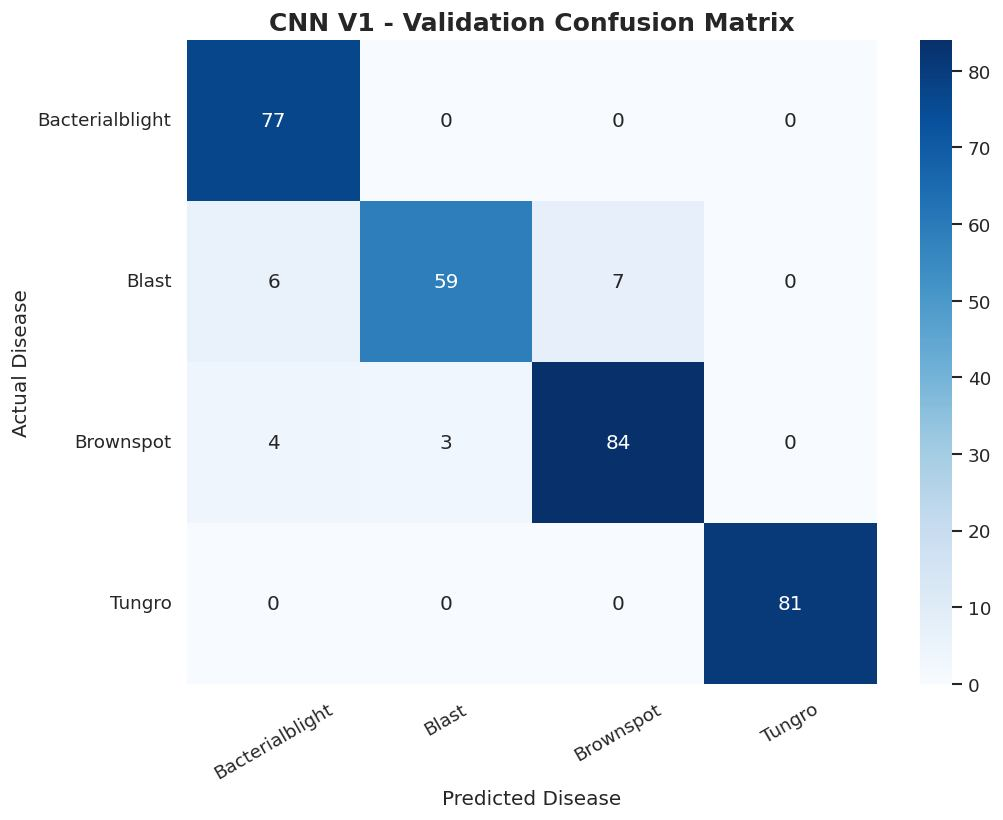

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "CNN V1 - Validation Confusion Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")

plt.xticks(rotation=30)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Cell 32: Plot CNN V1 Per-Class F1

Computes and plots per-class F1 scores for the baseline model.


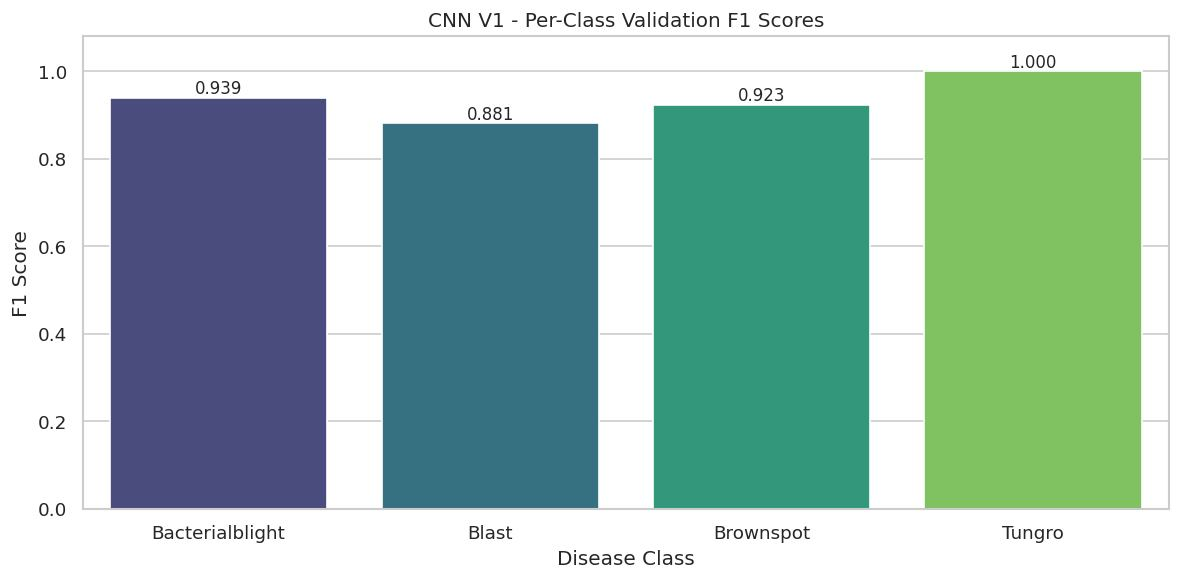

In [36]:
report = classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

per_class_f1 = [
    report[name]["f1-score"]
    for name in class_names
]

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=class_names,
    y=per_class_f1,
    hue=class_names,
    palette="viridis",
    legend=False
)

for i, score in enumerate(per_class_f1):
    ax.text(
        i,
        score + 0.01,
        f"{score:.3f}",
        ha="center",
        fontsize=10
    )

plt.ylim(0, 1.08)
plt.title("CNN V1 - Per-Class Validation F1 Scores")
plt.xlabel("Disease Class")
plt.ylabel("F1 Score")

plt.tight_layout()
plt.show()

## 7. CNN V2: Data Augmentation

The second model adds image augmentation to improve generalization. Its results are compared with the baseline to measure whether augmentation improves validation performance.


### Cell 33: Define CNN V2 Augmentation

Creates the augmentation pipeline used by CNN V2 to make training images more varied.


In [37]:
import tensorflow as tf
from tensorflow.keras import layers

augmentation_v2 = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.10)
], name="augmentation_v2")

### Cell 34: Preview CNN V2 Augmentation

Shows augmented versions of a sample training image so the CNN V2 transformation pipeline can be visually checked.


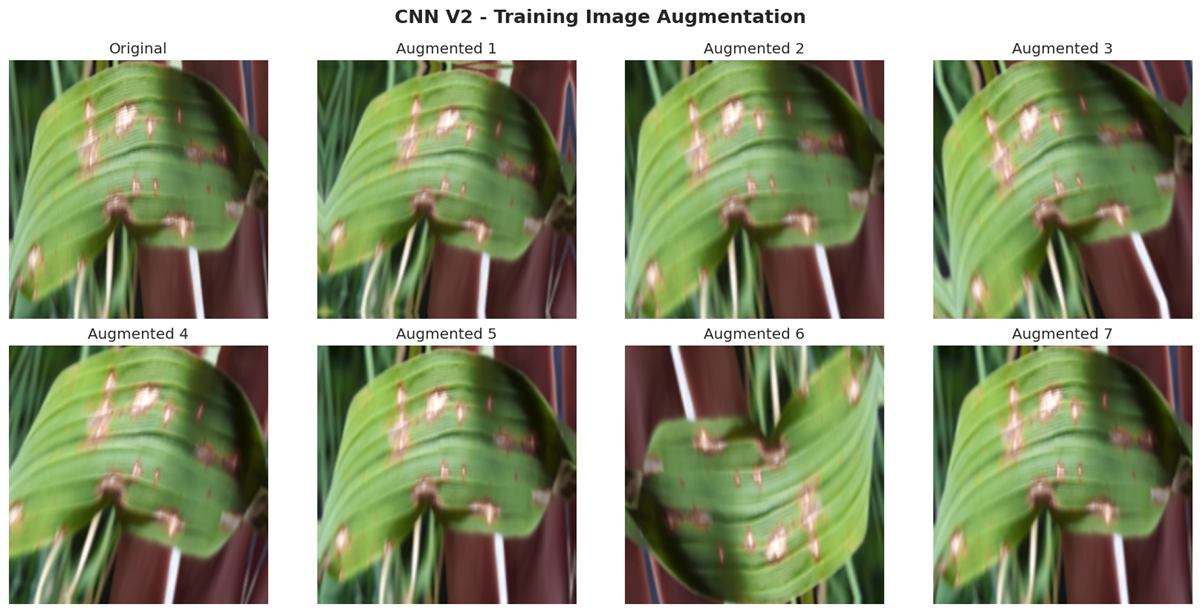

In [38]:
import matplotlib.pyplot as plt

sample_images, sample_labels = next(iter(train_ds.take(1)))

sample_image = sample_images[0:1]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):

    if i == 0:
        image = sample_image[0]
        title = "Original"
    else:
        augmented = augmentation_v2(
            sample_image,
            training=True
        )
        image = augmented[0]
        title = f"Augmented {i}"

    ax.imshow(tf.clip_by_value(image, 0, 1))
    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    "CNN V2 - Training Image Augmentation",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Cell 35: Build CNN V2

Builds CNN V2 by adding the augmentation pipeline before the baseline CNN architecture.


In [39]:
tf.keras.utils.set_random_seed(42)

cnn_v2 = tf.keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    augmentation_v2,
    build_baseline_cnn()
], name="cnn_v2")

cnn_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_v2.summary()

Model: "cnn_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation_v2 (Sequential)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 4)              │       110,276 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

### Cell 36: Train CNN V2

Trains the augmented CNN V2 model with early stopping and checkpointing.


In [40]:
callbacks_v2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "cnn_v2_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(MODEL_DIR / "cnn_v2_training.csv")
    )
]

history_v2 = cnn_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_v2,
    verbose=1
)

Epoch 1/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.3929 - loss: 1.2896
Epoch 1: val_loss improved from None to 0.87568, saving model to /content/rice_cnn_models/cnn_v2_best.keras

Epoch 1: finished saving model to /content/rice_cnn_models/cnn_v2_best.keras
47/47 ━━━━━━━━━━━━━━━━━━━━ 14s 106ms/step - accuracy: 0.4820 - loss: 1.1665 - val_accuracy: 0.6293 - val_loss: 0.8757
Epoch 2/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.7116 - loss: 0.7460
Epoch 2: val_loss improved from 0.87568 to 0.60936, saving model to /content/rice_cnn_models/cnn_v2_best.keras

Epoch 2: finished saving model to /content/rice_cnn_models/cnn_v2_best.keras
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.7025 - loss: 0.7093 - val_accuracy: 0.7632 - val_loss: 0.6094
Epoch 3/40
46/47 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.7403 - loss: 0.6002
Epoch 3: val_loss improved from 0.60936 to 0.59158, saving model to /content/rice_cnn_models/cnn_v2_best.keras

Epoch 3: finished saving

### Cell 37: Evaluate CNN V2

Evaluates CNN V2 on the validation set and prints accuracy, macro metrics, and the classification report.


In [41]:
import tensorflow as tf
import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cnn_v2_best = tf.keras.models.load_model(
    "/content/rice_cnn_models/cnn_v2_best.keras"
)

y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

y_prob_v2 = cnn_v2_best.predict(val_ds, verbose=0)
y_pred_v2 = np.argmax(y_prob_v2, axis=1)

v2_results = {
    "Model": "CNN V2 - Augmentation",
    "Accuracy": accuracy_score(y_true, y_pred_v2),
    "Macro Precision": precision_score(
        y_true, y_pred_v2,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred_v2,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_true, y_pred_v2,
        average="macro", zero_division=0
    )
}

for metric, value in v2_results.items():
    print(f"{metric}: {value}")

print("\nCNN V2 Classification Report:\n")

print(classification_report(
    y_true,
    y_pred_v2,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: CNN V2 - Augmentation
Accuracy: 0.940809968847352
Macro Precision: 0.9411390795830155
Macro Recall: 0.9399558774558774
Macro F1: 0.9401127389905033

CNN V2 Classification Report:

                 precision    recall  f1-score   support

Bacterialblight       0.97      0.91      0.94        77
          Blast       0.87      0.92      0.89        72
      Brownspot       0.92      0.93      0.93        91
         Tungro       1.00      1.00      1.00        81

       accuracy                           0.94       321
      macro avg       0.94      0.94      0.94       321
   weighted avg       0.94      0.94      0.94       321



### Cell 38: Compare CNN V1 and V2 Confusion Matrices

Shows CNN V1 and CNN V2 confusion matrices side by side to compare how augmentation changes class-level errors.


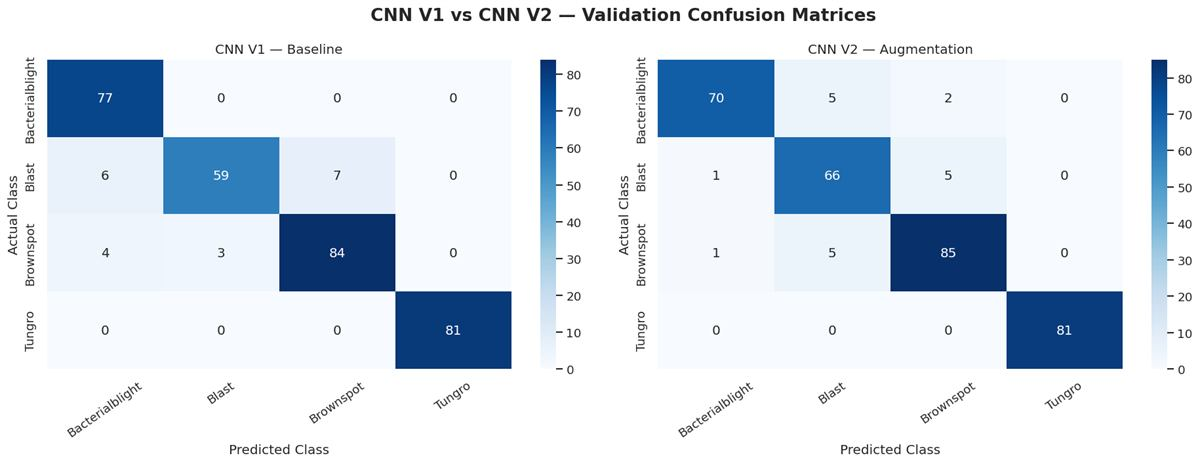

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_v1 = confusion_matrix(
    y_true, y_pred,
    labels=range(len(class_names))
)

cm_v2 = confusion_matrix(
    y_true, y_pred_v2,
    labels=range(len(class_names))
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, cm, title in zip(
    axes,
    [cm_v1, cm_v2],
    ["CNN V1 — Baseline", "CNN V2 — Augmentation"]
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.tick_params(axis="x", rotation=35)

plt.suptitle(
    "CNN V1 vs CNN V2 — Validation Confusion Matrices",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Cell 39: Compare CNN V1 and V2 Per-Class Scores

Compares CNN V1 and CNN V2 recall and F1-score for each disease class.


,Disease,V1 Recall,V2 Recall,V1 F1,V2 F1
0,Bacterialblight,1.0000,0.9091,0.9390,0.9396
1,Blast,0.8194,0.9167,0.8806,0.8919
2,Brownspot,0.9231,0.9341,0.9231,0.9290
3,Tungro,1.0000,1.0000,1.0000,1.0000


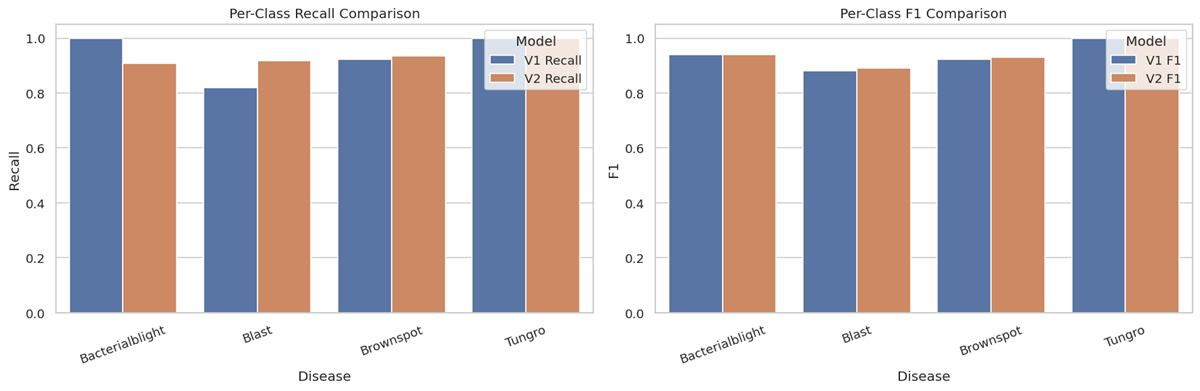

In [43]:
report_v1 = classification_report(
    y_true, y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_v2 = classification_report(
    y_true, y_pred_v2,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

comparison_rows = []

for disease in class_names:
    comparison_rows.append({
        "Disease": disease,
        "V1 Recall": report_v1[disease]["recall"],
        "V2 Recall": report_v2[disease]["recall"],
        "V1 F1": report_v1[disease]["f1-score"],
        "V2 F1": report_v2[disease]["f1-score"]
    })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

recall_plot = comparison_df.melt(
    id_vars="Disease",
    value_vars=["V1 Recall", "V2 Recall"],
    var_name="Model",
    value_name="Recall"
)

f1_plot = comparison_df.melt(
    id_vars="Disease",
    value_vars=["V1 F1", "V2 F1"],
    var_name="Model",
    value_name="F1"
)

sns.barplot(
    data=recall_plot,
    x="Disease", y="Recall",
    hue="Model", ax=axes[0]
)

sns.barplot(
    data=f1_plot,
    x="Disease", y="F1",
    hue="Model", ax=axes[1]
)

axes[0].set_title("Per-Class Recall Comparison")
axes[1].set_title("Per-Class F1 Comparison")

for ax in axes:
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 8. CNN V3: Batch Normalization and Dropout

The third model introduces batch normalization and dropout. This version produces the strongest early validation score, but additional checks are needed to confirm that the result is not caused by similarity leakage.


### Cell 40: Build CNN V3

Defines CNN V3 with batch normalization and dropout to improve stability and reduce overfitting.


In [44]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

def build_cnn_v3():
    inputs = layers.Input(shape=(224, 224, 3))

    # Same augmentation strategy as V2
    x = tf.keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.08),
        layers.RandomContrast(0.10)
    ], name="augmentation_v3")(inputs)

    # Convolution block 1
    x = layers.Conv2D(
        32, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)

    # Convolution block 2
    x = layers.Conv2D(
        64, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)

    # Convolution block 3
    x = layers.Conv2D(
        128, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)

    # Classification head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        4, activation="softmax"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="cnn_v3"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


cnn_v3 = build_cnn_v3()
cnn_v3.summary()

Model: "cnn_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_v3 (Sequential)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,948 (433.39 KB)

 Trainable params: 110,500 (431.64 KB)

 Non-trainable params: 448 (1.75 KB)

### Cell 41: Train CNN V3

Trains CNN V3 and saves the best checkpoint for validation comparison.


In [45]:
from pathlib import Path

MODEL_DIR = Path("/content/rice_cnn_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

callbacks_v3 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "cnn_v3_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(MODEL_DIR / "cnn_v3_training.csv")
    )
]

history_v3 = cnn_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_v3,
    verbose=1
)

Epoch 1/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.6618 - loss: 0.8861
Epoch 1: val_loss improved from None to 1.56877, saving model to /content/rice_cnn_models/cnn_v3_best.keras

Epoch 1: finished saving model to /content/rice_cnn_models/cnn_v3_best.keras
47/47 ━━━━━━━━━━━━━━━━━━━━ 13s 156ms/step - accuracy: 0.7373 - loss: 0.7197 - val_accuracy: 0.2835 - val_loss: 1.5688
Epoch 2/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.8144 - loss: 0.5023
Epoch 2: val_loss did not improve from 1.56877
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 127ms/step - accuracy: 0.8175 - loss: 0.4841 - val_accuracy: 0.2897 - val_loss: 2.0415
Epoch 3/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.8308 - loss: 0.4258
Epoch 3: val_loss did not improve from 1.56877
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 148ms/step - accuracy: 0.8389 - loss: 0.4002 - val_accuracy: 0.4237 - val_loss: 1.9210
Epoch 4/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.8565 - loss: 0.3880
Epoch 4: val_loss did no

### Cell 42: Compare CNN V1 V2 V3 Training Curves

Plots the training and validation curves for CNN V1, CNN V2, and CNN V3 to show how the architecture changes affect learning.


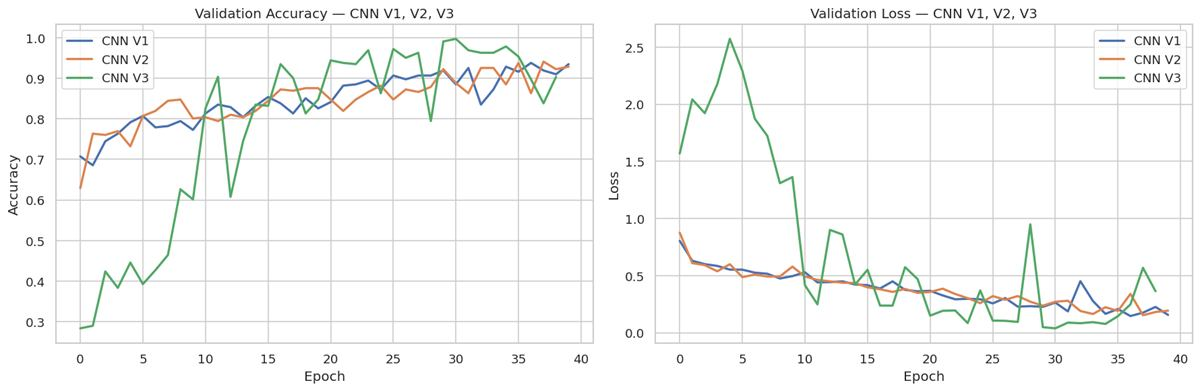

In [46]:
import matplotlib.pyplot as plt

histories = {
    "CNN V1": history_v1,
    "CNN V2": history_v2,
    "CNN V3": history_v3
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, history in histories.items():
    axes[0].plot(
        history.history["val_accuracy"],
        label=name,
        linewidth=2
    )

    axes[1].plot(
        history.history["val_loss"],
        label=name,
        linewidth=2
    )

axes[0].set_title("Validation Accuracy — CNN V1, V2, V3")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].set_title("Validation Loss — CNN V1, V2, V3")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

### Cell 43: Evaluate CNN V3

Evaluates CNN V3 and reports its validation metrics. This version becomes the strongest early candidate before leakage auditing.


In [47]:
import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

cnn_v3_best = tf.keras.models.load_model(
    "/content/rice_cnn_models/cnn_v3_best.keras"
)

y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

y_prob_v3 = cnn_v3_best.predict(val_ds, verbose=0)
y_pred_v3 = np.argmax(y_prob_v3, axis=1)

v3_results = {
    "Model": "CNN V3 - BN and Dropout",
    "Accuracy": accuracy_score(y_true, y_pred_v3),
    "Macro Precision": precision_score(
        y_true, y_pred_v3,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred_v3,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_true, y_pred_v3,
        average="macro", zero_division=0
    )
}

print("CNN V3 Validation Results\n")

for metric, value in v3_results.items():
    print(f"{metric}: {value}")

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred_v3,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

CNN V3 Validation Results

Model: CNN V3 - BN and Dropout
Accuracy: 0.9968847352024922
Macro Precision: 0.9972826086956521
Macro Recall: 0.9965277777777778
Macro F1: 0.996885628033169

Classification Report:

                 precision    recall  f1-score   support

Bacterialblight       1.00      1.00      1.00        77
          Blast       1.00      0.99      0.99        72
      Brownspot       0.99      1.00      0.99        91
         Tungro       1.00      1.00      1.00        81

       accuracy                           1.00       321
      macro avg       1.00      1.00      1.00       321
   weighted avg       1.00      1.00      1.00       321



### Cell 44: Plot CNN V3 Confusion Matrix

Plots CNN V3's confusion matrix to inspect which disease classes are predicted correctly or confused.


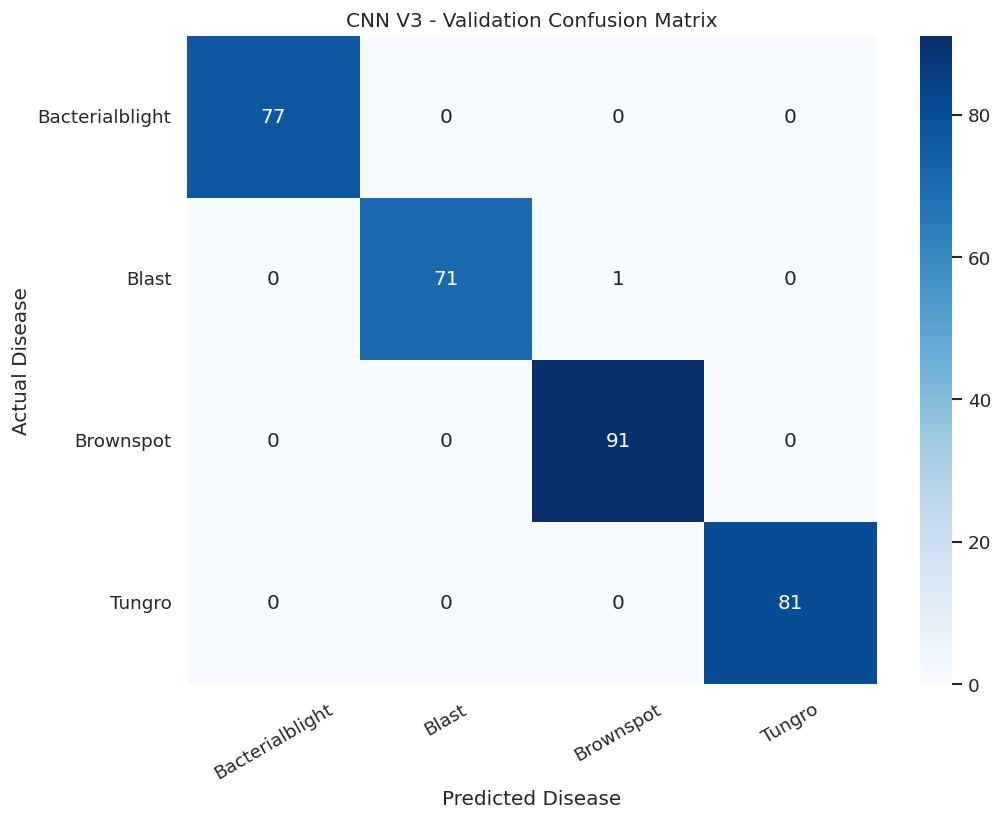

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_v3 = confusion_matrix(
    y_true,
    y_pred_v3,
    labels=range(len(class_names))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_v3,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN V3 - Validation Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=30)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Cell 45: Summarize CNN V1 V2 V3 Results

Creates a comparison table and chart for CNN V1, CNN V2, and CNN V3 using validation accuracy and macro-F1.


    Model  Accuracy  Macro F1
0  CNN V1    0.9377    0.9357
1  CNN V2    0.9408    0.9401
2  CNN V3    0.9969    0.9969


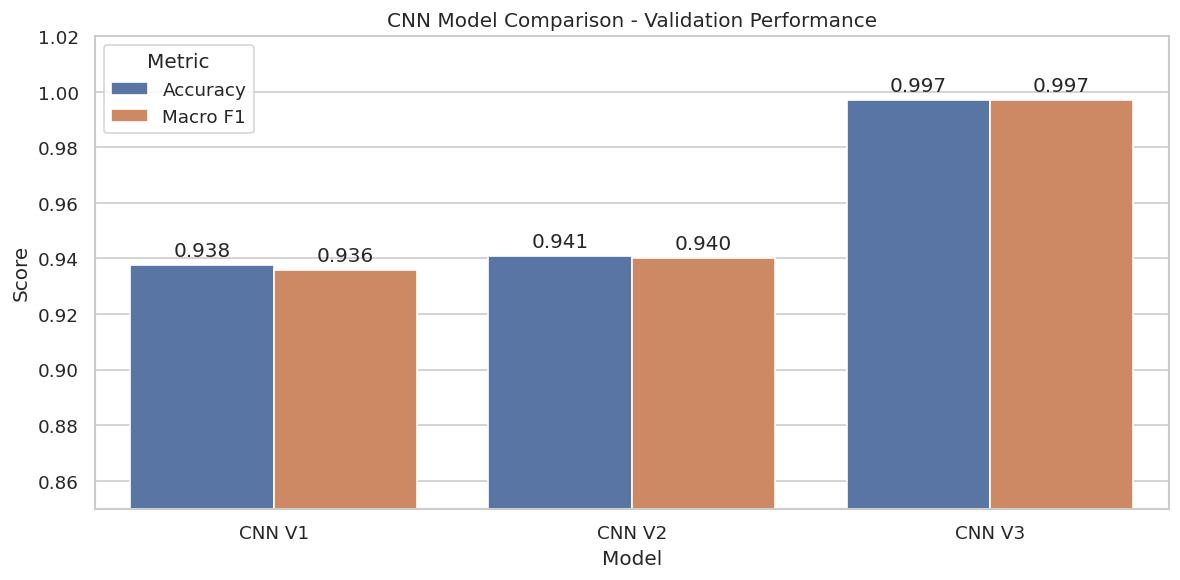

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

model_comparison = pd.DataFrame([
    {
        "Model": "CNN V1",
        "Accuracy": v1_results["Accuracy"],
        "Macro F1": v1_results["Macro F1"]
    },
    {
        "Model": "CNN V2",
        "Accuracy": v2_results["Accuracy"],
        "Macro F1": v2_results["Macro F1"]
    },
    {
        "Model": "CNN V3",
        "Accuracy": v3_results["Accuracy"],
        "Macro F1": v3_results["Macro F1"]
    }
])

print(model_comparison.round(4))

comparison_long = model_comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=comparison_long,
    x="Model",
    y="Score",
    hue="Metric"
)

ax.set_ylim(0.85, 1.02)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.title("CNN Model Comparison - Validation Performance")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

## 9. CNN V4 and CNN V5 Ablation Experiments

CNN V4 adjusts the learning rate, while CNN V5 removes dropout. These experiments compare stability, validation loss, and macro-F1 to choose a more reliable architecture.


### Cell 46: Build CNN V4

Creates CNN V4 by reusing the CNN V3 architecture with a lower learning rate for a more stable training run.


In [50]:
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

# Reuse the exact V3 architecture
cnn_v4 = build_cnn_v3()

# Change only the learning rate
cnn_v4.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN V4 — Learning Rate: 0.0003")
print("Parameters:", cnn_v4.count_params())
cnn_v4.summary()

CNN V4 — Learning Rate: 0.0003
Parameters: 110948


Model: "cnn_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_v3 (Sequential)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,948 (433.39 KB)

 Trainable params: 110,500 (431.64 KB)

 Non-trainable params: 448 (1.75 KB)

### Cell 47: Train CNN V4

Trains CNN V4 and checkpoints the best validation model.


In [51]:
from pathlib import Path

MODEL_DIR = Path("/content/rice_cnn_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

callbacks_v4 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "cnn_v4_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(MODEL_DIR / "cnn_v4_training.csv")
    )
]

history_v4 = cnn_v4.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_v4,
    verbose=1
)

Epoch 1/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.5964 - loss: 1.0449
Epoch 1: val_loss improved from None to 1.41181, saving model to /content/rice_cnn_models/cnn_v4_best.keras

Epoch 1: finished saving model to /content/rice_cnn_models/cnn_v4_best.keras
47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 165ms/step - accuracy: 0.7045 - loss: 0.8452 - val_accuracy: 0.2835 - val_loss: 1.4118
Epoch 2/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.7908 - loss: 0.5918
Epoch 2: val_loss did not improve from 1.41181
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 132ms/step - accuracy: 0.8082 - loss: 0.5509 - val_accuracy: 0.2835 - val_loss: 1.5575
Epoch 3/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.8187 - loss: 0.4856
Epoch 3: val_loss did not improve from 1.41181
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 135ms/step - accuracy: 0.8255 - loss: 0.4684 - val_accuracy: 0.2835 - val_loss: 1.7141
Epoch 4/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.8700 - loss: 0.3845
Epoch 4: val_loss did no

### Cell 48: Compare CNN V3 and V4 Training Curves

Compares CNN V3 and CNN V4 validation curves to evaluate the effect of lowering the learning rate.


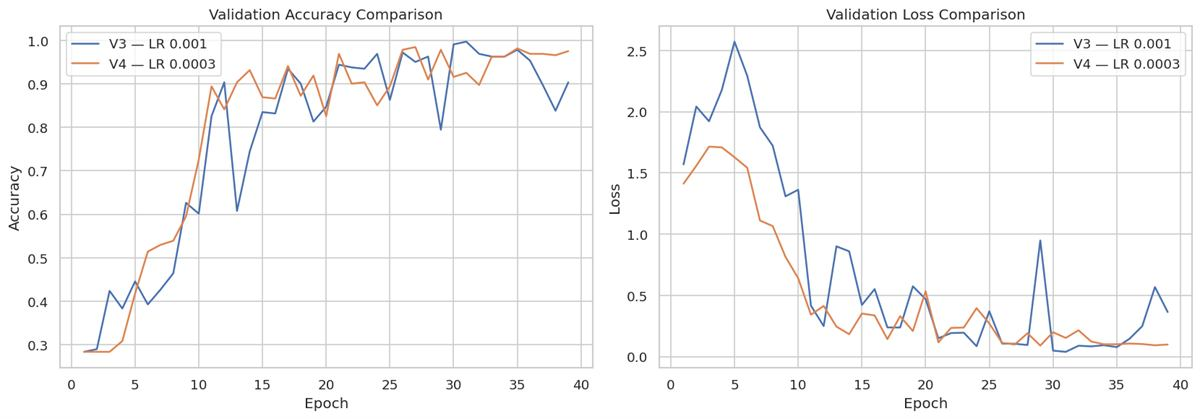


CNN V3
Best accuracy: 0.9969
Minimum loss: 0.0389
Last 10 epoch accuracy std: 0.0475

CNN V4
Best accuracy: 0.9844
Minimum loss: 0.0901
Last 10 epoch accuracy std: 0.0272


In [52]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in {
    "V3 — LR 0.001": history_v3,
    "V4 — LR 0.0003": history_v4
}.items():

    epochs = np.arange(
        1, len(history.history["val_accuracy"]) + 1
    )

    axes[0].plot(
        epochs,
        history.history["val_accuracy"],
        label=name
    )

    axes[1].plot(
        epochs,
        history.history["val_loss"],
        label=name
    )

axes[0].set_title("Validation Accuracy Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].set_title("Validation Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

for name, history in {
    "CNN V3": history_v3,
    "CNN V4": history_v4
}.items():

    acc = np.array(history.history["val_accuracy"])

    print(f"\n{name}")
    print("Best accuracy:", round(acc.max(), 4))
    print("Minimum loss:", round(
        min(history.history["val_loss"]), 4
    ))

    # Later-epoch variability
    last_values = acc[-10:]
    print("Last 10 epoch accuracy std:",
          round(last_values.std(), 4))

### Cell 49: Evaluate CNN V4

Evaluates CNN V4 on validation data and reports accuracy, macro precision, macro recall, macro-F1, and the classification report.


In [53]:
import tensorflow as tf
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

cnn_v4_best = tf.keras.models.load_model(
    "/content/rice_cnn_models/cnn_v4_best.keras"
)

y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

y_prob_v4 = cnn_v4_best.predict(val_ds, verbose=0)
y_pred_v4 = np.argmax(y_prob_v4, axis=1)

v4_results = {
    "Model": "CNN V4 - Learning Rate 0.0003",
    "Accuracy": accuracy_score(y_true, y_pred_v4),
    "Macro Precision": precision_score(
        y_true, y_pred_v4,
        average="macro",
        zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred_v4,
        average="macro",
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_true, y_pred_v4,
        average="macro",
        zero_division=0
    )
}

print("CNN V4 Validation Results\n")

for metric, value in v4_results.items():
    print(f"{metric}: {value}")

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred_v4,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

CNN V4 Validation Results

Model: CNN V4 - Learning Rate 0.0003
Accuracy: 0.9781931464174455
Macro Precision: 0.9782368537339814
Macro Recall: 0.9770958208458209
Macro F1: 0.9775293644568445

Classification Report:

                 precision    recall  f1-score   support

Bacterialblight       1.00      0.96      0.98        77
          Blast       0.95      0.96      0.95        72
      Brownspot       0.97      0.99      0.98        91
         Tungro       1.00      1.00      1.00        81

       accuracy                           0.98       321
      macro avg       0.98      0.98      0.98       321
   weighted avg       0.98      0.98      0.98       321



### Cell 50: Plot CNN V4 Confusion Matrix

Plots the CNN V4 confusion matrix so the learning-rate experiment can be inspected class by class.


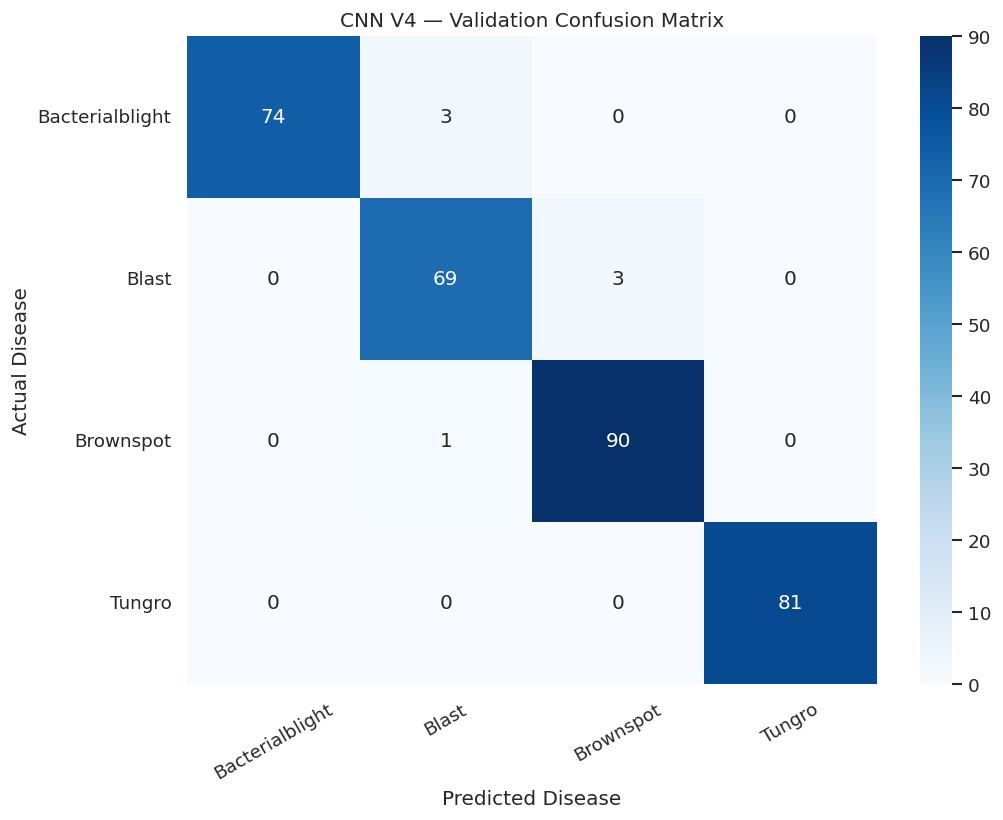

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_v4 = confusion_matrix(
    y_true,
    y_pred_v4,
    labels=range(len(class_names))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_v4,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN V4 — Validation Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")

plt.xticks(rotation=30)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Cell 51: Build CNN V5 No-Dropout Variant

Defines CNN V5 as a no-dropout ablation of the stronger CNN architecture.


In [59]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

def build_cnn_v5():

    inputs = layers.Input(shape=(224, 224, 3))

    x = tf.keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.08),
        layers.RandomContrast(0.10)
    ], name="augmentation_v5")(inputs)

    for filters in [32, 64, 128]:

        x = layers.Conv2D(
            filters,
            kernel_size=3,
            padding="same",
            use_bias=False
        )(x)

        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    # Dropout intentionally removed for ablation

    outputs = layers.Dense(
        4,
        activation="softmax"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="cnn_v5_no_dropout"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


cnn_v5 = build_cnn_v5()
cnn_v5.summary()

Model: "cnn_v5_no_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_v5 (Sequential)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,948 (433.39 KB)

 Trainable params: 110,500 (431.64 KB)

 Non-trainable params: 448 (1.75 KB)

### Cell 52: Train CNN V5

Trains CNN V5 to test whether dropout is helping or hurting model generalization.


In [57]:
from pathlib import Path

MODEL_DIR = Path("/content/rice_cnn_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

callbacks_v5 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "cnn_v5_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(MODEL_DIR / "cnn_v5_training.csv")
    )
]

history_v5 = cnn_v5.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_v5,
    verbose=1
)

Epoch 1/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.9775 - loss: 0.0745
Epoch 1: val_loss improved from None to 0.25118, saving model to /content/rice_cnn_models/cnn_v5_best.keras

Epoch 1: finished saving model to /content/rice_cnn_models/cnn_v5_best.keras
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 132ms/step - accuracy: 0.9619 - loss: 0.0988 - val_accuracy: 0.8941 - val_loss: 0.2512
Epoch 2/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.9573 - loss: 0.1185
Epoch 2: val_loss did not improve from 0.25118
47/47 ━━━━━━━━━━━━━━━━━━━━ 10s 133ms/step - accuracy: 0.9472 - loss: 0.1317 - val_accuracy: 0.6760 - val_loss: 1.9417
Epoch 3/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.9735 - loss: 0.0783
Epoch 3: val_loss did not improve from 0.25118
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - accuracy: 0.9840 - loss: 0.0642 - val_accuracy: 0.7664 - val_loss: 1.0156
Epoch 4/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.9794 - loss: 0.0655
Epoch 4: val_loss improv

### Cell 53: Compare CNN V3 and V5 Training Curves

Compares CNN V3 and CNN V5 to show whether removing dropout improves or weakens validation behavior.


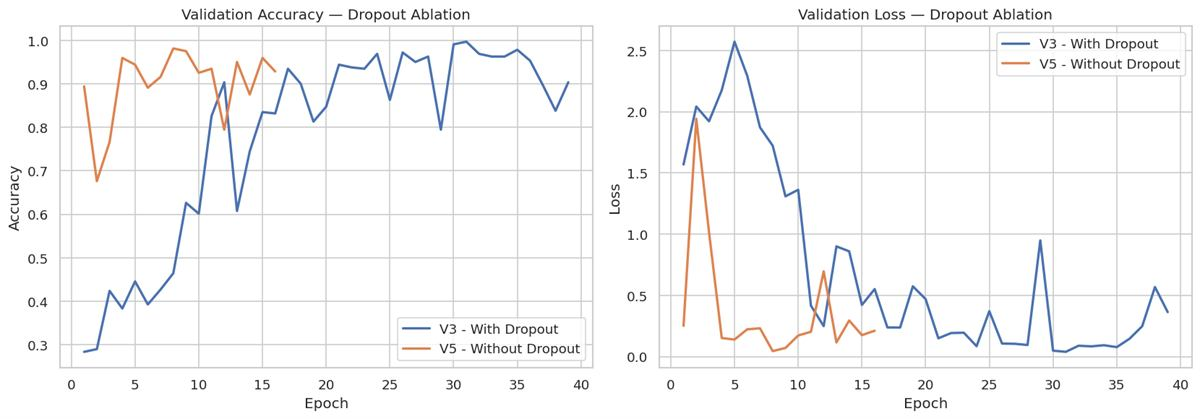


CNN V3
Peak validation accuracy: 0.9969
Minimum validation loss: 0.0389

CNN V5
Peak validation accuracy: 0.9813
Minimum validation loss: 0.0449


In [58]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in {
    "V3 - With Dropout": history_v3,
    "V5 - Without Dropout": history_v5
}.items():

    epochs = np.arange(
        1, len(history.history["val_accuracy"]) + 1
    )

    axes[0].plot(
        epochs,
        history.history["val_accuracy"],
        label=name,
        linewidth=2
    )

    axes[1].plot(
        epochs,
        history.history["val_loss"],
        label=name,
        linewidth=2
    )

axes[0].set_title("Validation Accuracy — Dropout Ablation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].set_title("Validation Loss — Dropout Ablation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

for name, history in {
    "CNN V3": history_v3,
    "CNN V5": history_v5
}.items():

    print(f"\n{name}")
    print(
        "Peak validation accuracy:",
        round(max(history.history["val_accuracy"]), 4)
    )
    print(
        "Minimum validation loss:",
        round(min(history.history["val_loss"]), 4)
    )

### Cell 54: Train CNN V5

Trains CNN V5 to test whether dropout is helping or hurting model generalization.


In [61]:
import tensorflow as tf
from pathlib import Path

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Create a completely new CNN V5
cnn_v5 = build_cnn_v5()

print("Fresh CNN V5 created.")
print("Trainable parameters:", cnn_v5.count_params())

MODEL_DIR = Path("/content/rice_cnn_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

callbacks_v5 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        start_from_epoch=12,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        str(MODEL_DIR / "cnn_v5_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(MODEL_DIR / "cnn_v5_training.csv"),
        append=False
    )
]

history_v5 = cnn_v5.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks_v5,
    verbose=1
)

Fresh CNN V5 created.
Trainable parameters: 110948
Epoch 1/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.6646 - loss: 0.8345
Epoch 1: val_loss improved from None to 1.60597, saving model to /content/rice_cnn_models/cnn_v5_best.keras

Epoch 1: finished saving model to /content/rice_cnn_models/cnn_v5_best.keras
47/47 ━━━━━━━━━━━━━━━━━━━━ 13s 136ms/step - accuracy: 0.7460 - loss: 0.6746 - val_accuracy: 0.2897 - val_loss: 1.6060
Epoch 2/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.8598 - loss: 0.4095
Epoch 2: val_loss did not improve from 1.60597
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 133ms/step - accuracy: 0.8583 - loss: 0.4010 - val_accuracy: 0.2835 - val_loss: 2.0024
Epoch 3/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.8468 - loss: 0.3798
Epoch 3: val_loss did not improve from 1.60597
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - accuracy: 0.8396 - loss: 0.3919 - val_accuracy: 0.4143 - val_loss: 1.6917
Epoch 4/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accur

### Cell 55: Evaluate CNN V5

Evaluates CNN V5 and reports validation metrics for the no-dropout ablation.


In [62]:
import tensorflow as tf
import numpy as np

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

cnn_v5_best = tf.keras.models.load_model(
    "/content/rice_cnn_models/cnn_v5_best.keras"
)

y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

y_prob_v5 = cnn_v5_best.predict(val_ds, verbose=0)
y_pred_v5 = np.argmax(y_prob_v5, axis=1)

v5_results = {
    "Model": "CNN V5 - No Dropout",
    "Accuracy": accuracy_score(y_true, y_pred_v5),
    "Macro Precision": precision_score(
        y_true, y_pred_v5,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred_v5,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_true, y_pred_v5,
        average="macro", zero_division=0
    )
}

print("CNN V5 Validation Results\n")

for metric, value in v5_results.items():
    print(f"{metric}: {value}")

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred_v5,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

CNN V5 Validation Results

Model: CNN V5 - No Dropout
Accuracy: 0.9626168224299065
Macro Precision: 0.9646542256753212
Macro Recall: 0.9585588023088023
Macro F1: 0.9599211590117217

Classification Report:

                 precision    recall  f1-score   support

Bacterialblight       0.93      0.99      0.96        77
          Blast       0.98      0.85      0.91        72
      Brownspot       0.95      1.00      0.97        91
         Tungro       1.00      1.00      1.00        81

       accuracy                           0.96       321
      macro avg       0.96      0.96      0.96       321
   weighted avg       0.96      0.96      0.96       321



### Cell 56: Evaluate CNN V5

Evaluates CNN V5 and reports validation metrics for the no-dropout ablation.


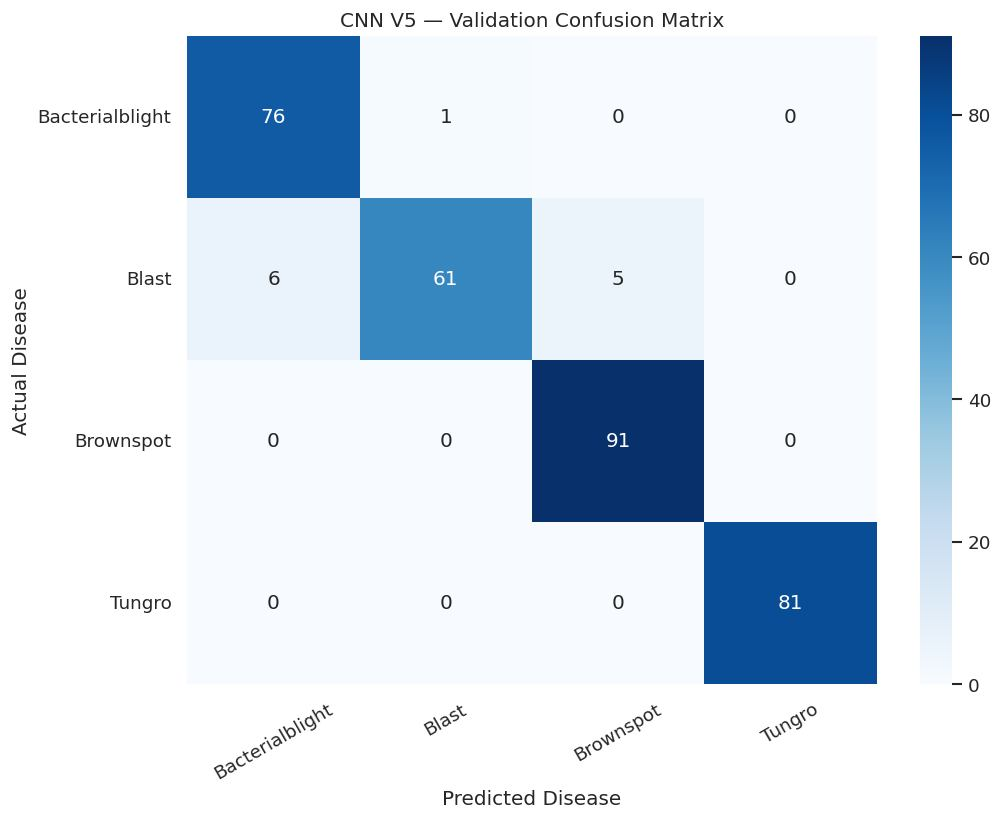

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_v5 = confusion_matrix(
    y_true,
    y_pred_v5,
    labels=range(len(class_names))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_v5,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN V5 — Validation Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")

plt.xticks(rotation=30)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Cell 57: Final CNN V1 to V5 Comparison

Combines CNN V1, CNN V2, CNN V3, CNN V4, and CNN V5 into one validation comparison table and plot.


FINAL CNN EXPERIMENT COMPARISON


,Model,Configuration,Learning Rate,Accuracy,Macro F1,Best Val Loss
0,CNN V1,Baseline,0.0010,0.9377,0.9357,0.1465
1,CNN V2,Augmentation,0.0010,0.9408,0.9401,0.1532
2,CNN V3,Augmentation + BN + Dropout,0.0010,0.9969,0.9969,0.0389
3,CNN V4,Reduced Learning Rate,0.0003,0.9782,0.9775,0.0901
4,CNN V5,No Dropout,0.0010,0.9626,0.9599,0.1435



Best validation candidate: CNN V3
Macro-F1: 0.9969


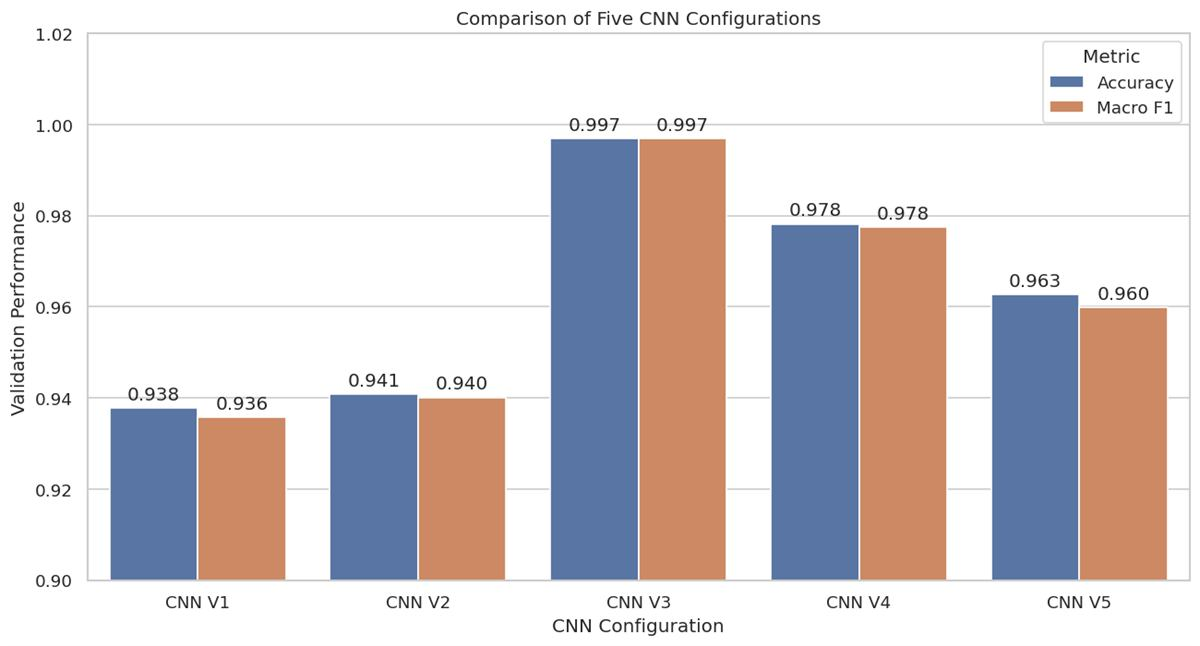

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results_df = pd.DataFrame([
    {
        "Model": "CNN V1",
        "Configuration": "Baseline",
        "Learning Rate": 0.001,
        "Accuracy": v1_results["Accuracy"],
        "Macro F1": v1_results["Macro F1"],
        "Best Val Loss": min(history_v1.history["val_loss"])
    },
    {
        "Model": "CNN V2",
        "Configuration": "Augmentation",
        "Learning Rate": 0.001,
        "Accuracy": v2_results["Accuracy"],
        "Macro F1": v2_results["Macro F1"],
        "Best Val Loss": min(history_v2.history["val_loss"])
    },
    {
        "Model": "CNN V3",
        "Configuration": "Augmentation + BN + Dropout",
        "Learning Rate": 0.001,
        "Accuracy": v3_results["Accuracy"],
        "Macro F1": v3_results["Macro F1"],
        "Best Val Loss": min(history_v3.history["val_loss"])
    },
    {
        "Model": "CNN V4",
        "Configuration": "Reduced Learning Rate",
        "Learning Rate": 0.0003,
        "Accuracy": v4_results["Accuracy"],
        "Macro F1": v4_results["Macro F1"],
        "Best Val Loss": min(history_v4.history["val_loss"])
    },
    {
        "Model": "CNN V5",
        "Configuration": "No Dropout",
        "Learning Rate": 0.001,
        "Accuracy": v5_results["Accuracy"],
        "Macro F1": v5_results["Macro F1"],
        "Best Val Loss": min(history_v5.history["val_loss"])
    }
])

print("FINAL CNN EXPERIMENT COMPARISON")
display(results_df.round(4))

# Best candidate based on validation Macro-F1
best_row = results_df.loc[
    results_df["Macro F1"].idxmax()
]

print("\nBest validation candidate:", best_row["Model"])
print("Macro-F1:", round(best_row["Macro F1"], 4))

# Visual comparison
plot_df = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Macro F1"],
    var_name="Metric",
    value_name="Score"
)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

ax.set_ylim(0.90, 1.02)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3)

plt.title("Comparison of Five CNN Configurations")
plt.ylabel("Validation Performance")
plt.xlabel("CNN Configuration")
plt.tight_layout()
plt.show()

# Save results for viva/report
results_df.to_csv(
    "/content/rice_cnn_models/model_comparison.csv",
    index=False
)

## 10. Reproducibility and Leakage Audit

The strongest model is retrained with additional random seeds, and the split is audited with perceptual-hash distances. This step identifies possible near-duplicate leakage between partitions and motivates a corrected grouped split.


### Cell 58: Run Reproducibility Check

Retrains the selected architecture with additional random seeds to see how stable the validation performance is.


In [65]:
import tensorflow as tf
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

SEEDS = [123, 2026]
repro_results = []

REPRO_DIR = Path("/content/rice_cnn_models/reproducibility")
REPRO_DIR.mkdir(parents=True, exist_ok=True)

# Obtain labels in the fixed validation order
y_true_repro = np.concatenate([
    labels.numpy() for _, labels in val_ds
])

for seed in SEEDS:

    print(f"\n{'='*50}")
    print(f"Training CNN V3 — Seed {seed}")
    print(f"{'='*50}")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    # A fresh model with V3 architecture
    model = build_cnn_v3()

    checkpoint_path = (
        REPRO_DIR / f"cnn_v3_seed_{seed}.keras"
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True,
            verbose=0
        )
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=40,
        callbacks=callbacks,
        verbose=1
    )

    best_model = tf.keras.models.load_model(
        checkpoint_path
    )

    probabilities = best_model.predict(
        val_ds, verbose=0
    )

    predictions = np.argmax(probabilities, axis=1)

    repro_results.append({
        "Seed": seed,
        "Accuracy": accuracy_score(
            y_true_repro, predictions
        ),
        "Macro F1": f1_score(
            y_true_repro,
            predictions,
            average="macro"
        ),
        "Minimum Val Loss": min(
            history.history["val_loss"]
        ),
        "Epochs": len(history.history["loss"])
    })

repro_df = pd.DataFrame(repro_results)

display(repro_df.round(4))


Training CNN V3 — Seed 123
Epoch 1/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 146ms/step - accuracy: 0.7273 - loss: 0.7286 - val_accuracy: 0.2835 - val_loss: 1.5463
Epoch 2/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - accuracy: 0.8075 - loss: 0.5106 - val_accuracy: 0.4268 - val_loss: 1.8589
Epoch 3/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 136ms/step - accuracy: 0.8469 - loss: 0.4005 - val_accuracy: 0.4050 - val_loss: 1.7669
Epoch 4/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 132ms/step - accuracy: 0.8523 - loss: 0.3630 - val_accuracy: 0.3053 - val_loss: 2.2781
Epoch 5/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 137ms/step - accuracy: 0.8837 - loss: 0.3160 - val_accuracy: 0.2773 - val_loss: 2.6573
Epoch 6/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 10s 138ms/step - accuracy: 0.8817 - loss: 0.2934 - val_accuracy: 0.2897 - val_loss: 2.9757
Epoch 7/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 131ms/step - accuracy: 0.9004 - loss: 0.2797 - val_accuracy: 0.2368 - val_loss: 3.6979
Epoch 8/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 129ms/step - accuracy: 0.9124 - l

,Seed,Accuracy,Macro F1,Minimum Val Loss,Epochs
0,123,0.9782,0.9782,0.0928,35
1,2026,0.9564,0.9564,0.1189,25


### Cell 59: Summarize Seed Sensitivity

Adds the original CNN V3 seed to the additional seed runs and visualizes how stable the model performance is across random seeds.


,Seed,Accuracy,Macro F1,Minimum Val Loss,Epochs
0,42,0.9969,0.9969,0.0389,39
1,123,0.9782,0.9782,0.0928,35
2,2026,0.9564,0.9564,0.1189,25


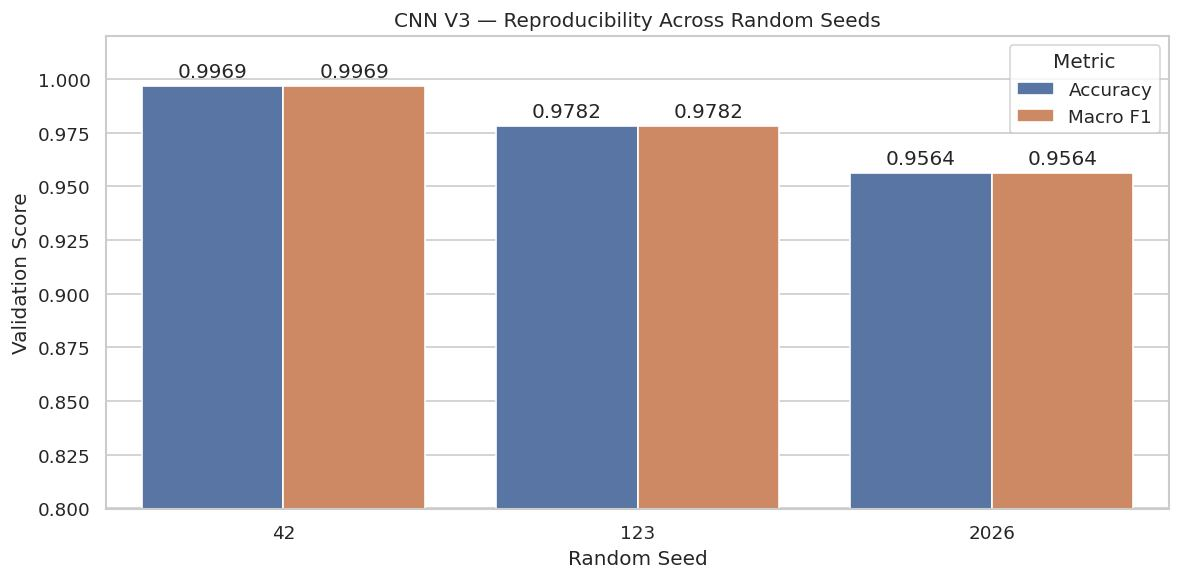


Mean validation accuracy: 0.9771547248182761
Accuracy standard deviation: 0.020269180992672
Mean Macro F1: 0.9771620900255642
Macro F1 standard deviation: 0.02028312391914135


In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

# Include original CNN V3 result
original_v3 = pd.DataFrame([{
    "Seed": 42,
    "Accuracy": v3_results["Accuracy"],
    "Macro F1": v3_results["Macro F1"],
    "Minimum Val Loss": min(
        history_v3.history["val_loss"]
    ),
    "Epochs": len(history_v3.history["loss"])
}])

all_repro = pd.concat(
    [original_v3, repro_df],
    ignore_index=True
)

display(all_repro.round(4))

plot_data = all_repro.melt(
    id_vars="Seed",
    value_vars=["Accuracy", "Macro F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=plot_data,
    x="Seed",
    y="Score",
    hue="Metric"
)

ax.set_ylim(0.80, 1.02)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.title("CNN V3 — Reproducibility Across Random Seeds")
plt.xlabel("Random Seed")
plt.ylabel("Validation Score")
plt.tight_layout()
plt.show()

print("\nMean validation accuracy:",
      all_repro["Accuracy"].mean())

print("Accuracy standard deviation:",
      all_repro["Accuracy"].std())

print("Mean Macro F1:",
      all_repro["Macro F1"].mean())

print("Macro F1 standard deviation:",
      all_repro["Macro F1"].std())

### Cell 60: Audit Cross-Split Similarity

Measures perceptual-hash distances between training, validation, and test images to detect possible near-duplicate leakage.


In [67]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

def phash_to_bits(hash_value):
    number = int(str(hash_value), 16)
    return np.array(
        [(number >> i) & 1 for i in range(63, -1, -1)],
        dtype=np.uint8
    )

# Existing pHash information from the cleaned dataset
hash_mapping = unique_df.set_index("filepath")["phash_str"].to_dict()

def get_hash_bits(dataframe):
    return np.stack([
        phash_to_bits(hash_mapping[path])
        for path in dataframe["filepath"]
    ])

train_bits = get_hash_bits(train_df)
val_bits = get_hash_bits(val_df)
test_bits = get_hash_bits(test_df)

def audit_split(name_a, bits_a, name_b, bits_b):
    distances = cdist(
        bits_a, bits_b,
        metric="hamming"
    ) * 64

    print(f"\n{name_a} vs {name_b}")
    print("Minimum pHash distance:", distances.min())

    for threshold in [0, 2, 4, 6, 8]:
        print(
            f"Pairs with distance <= {threshold}:",
            int(np.sum(distances <= threshold))
        )

    return distances

train_val_dist = audit_split(
    "Training", train_bits,
    "Validation", val_bits
)

train_test_dist = audit_split(
    "Training", train_bits,
    "Testing", test_bits
)

val_test_dist = audit_split(
    "Validation", val_bits,
    "Testing", test_bits
)


Training vs Validation
Minimum pHash distance: 6.0
Pairs with distance <= 0: 0
Pairs with distance <= 2: 0
Pairs with distance <= 4: 0
Pairs with distance <= 6: 13
Pairs with distance <= 8: 24

Training vs Testing
Minimum pHash distance: 6.0
Pairs with distance <= 0: 0
Pairs with distance <= 2: 0
Pairs with distance <= 4: 0
Pairs with distance <= 6: 14
Pairs with distance <= 8: 23

Validation vs Testing
Minimum pHash distance: 6.0
Pairs with distance <= 0: 0
Pairs with distance <= 2: 0
Pairs with distance <= 4: 0
Pairs with distance <= 6: 1
Pairs with distance <= 8: 3


### Cell 61: Inspect Near-Duplicate Examples

Displays near-duplicate examples and confirms whether similar images cross disease-class boundaries.


Total candidate pairs: 50
Cross-class candidate pairs: 0


distance,6,8
comparison,,
Train vs Test,14,9
Train vs Validation,13,11
Validation vs Test,1,2


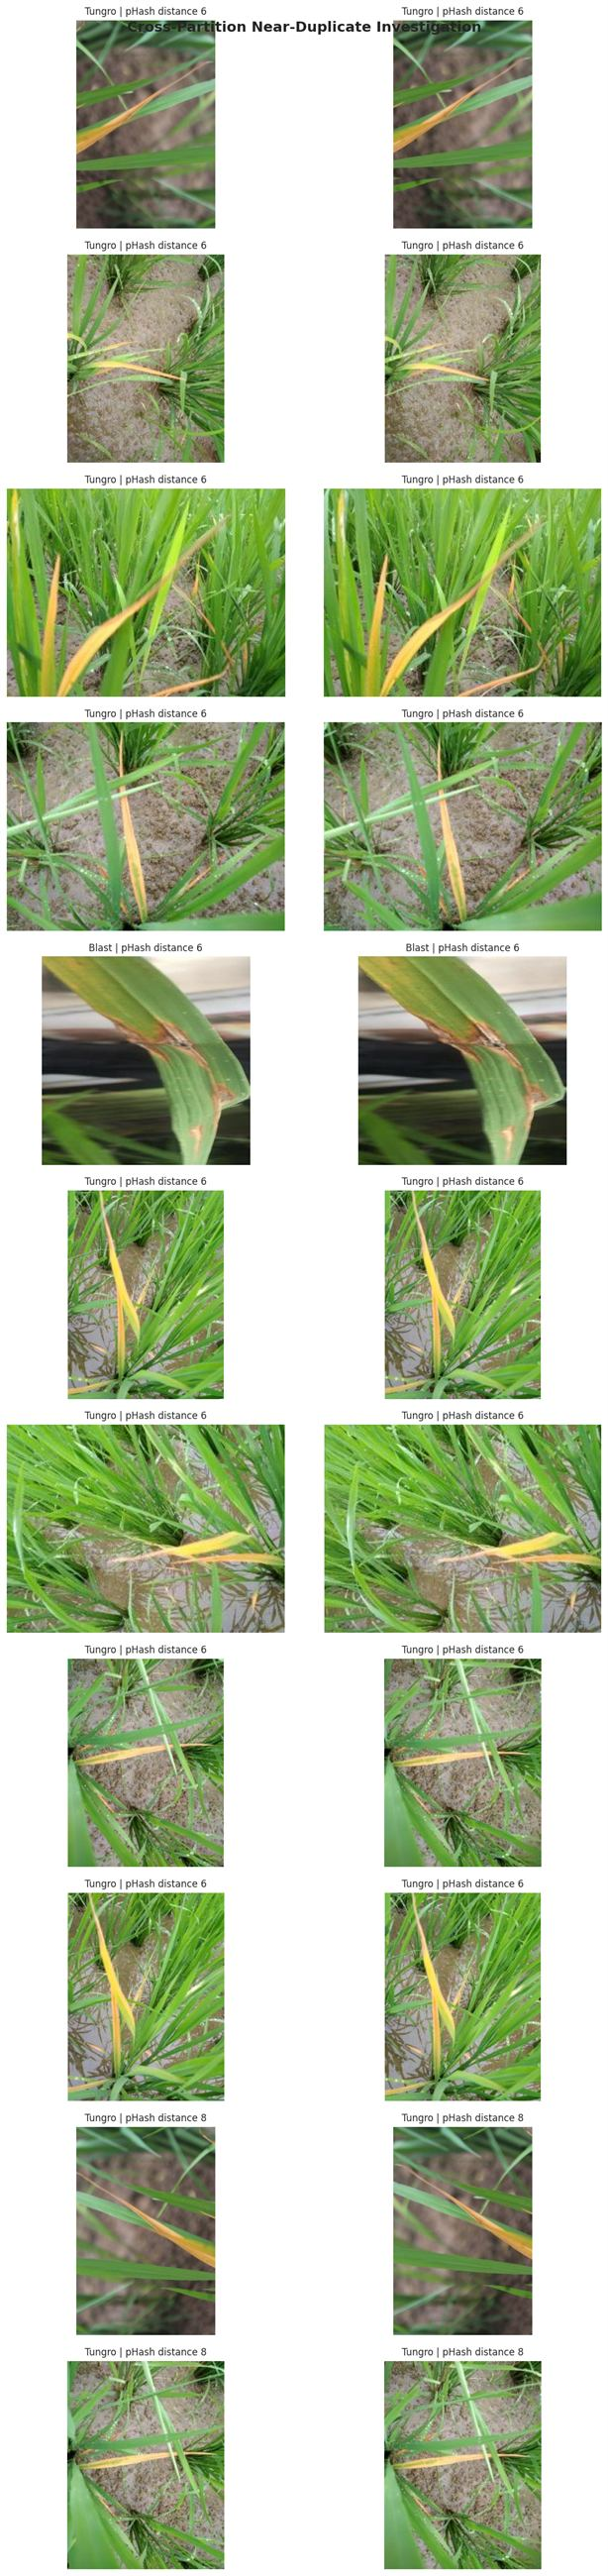

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

def get_candidate_pairs(df_a, df_b, distances, threshold=8):
    indices = np.argwhere(distances <= threshold)

    records = []

    for i, j in indices:
        records.append({
            "file_a": df_a.iloc[i]["filepath"],
            "file_b": df_b.iloc[j]["filepath"],
            "class_a": df_a.iloc[i]["class"],
            "class_b": df_b.iloc[j]["class"],
            "distance": int(distances[i, j])
        })

    return pd.DataFrame(
        records,
        columns=[
            "file_a", "file_b",
            "class_a", "class_b", "distance"
        ]
    )


pairs_tv = get_candidate_pairs(
    train_df, val_df, train_val_dist
)

pairs_tt = get_candidate_pairs(
    train_df, test_df, train_test_dist
)

pairs_vt = get_candidate_pairs(
    val_df, test_df, val_test_dist
)

pairs_tv["comparison"] = "Train vs Validation"
pairs_tt["comparison"] = "Train vs Test"
pairs_vt["comparison"] = "Validation vs Test"

all_pairs = pd.concat(
    [pairs_tv, pairs_tt, pairs_vt],
    ignore_index=True
).sort_values("distance").reset_index(drop=True)

print("Total candidate pairs:", len(all_pairs))

print(
    "Cross-class candidate pairs:",
    (all_pairs["class_a"] != all_pairs["class_b"]).sum()
)

display(all_pairs.groupby(
    ["comparison", "distance"]
).size().unstack(fill_value=0))


# Display 12 candidate pairs:
# prioritize distance 6 and include each comparison type.

selected = all_pairs.groupby(
    "comparison",
    group_keys=False
).head(4).head(12)

fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(10, 3.5 * len(selected)),
    squeeze=False
)

for row, (_, pair) in enumerate(selected.iterrows()):

    for col, key in enumerate(["file_a", "file_b"]):
        with Image.open(pair[key]) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].axis("off")
        axes[row, col].set_title(
            f"{pair['class_a' if col == 0 else 'class_b']}"
            f" | pHash distance {pair['distance']}",
            fontsize=10
        )

    axes[row, 0].set_ylabel(
        pair["comparison"],
        fontsize=9
    )

plt.suptitle(
    "Cross-Partition Near-Duplicate Investigation",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Cell 62: Find Near-Duplicate Distances

Computes Hamming distances between perceptual hashes to identify remaining near-duplicate image pairs.


In [69]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

# Start from the 2,138 representative images
audit_df = final_df.copy().reset_index(drop=True)

THRESHOLD = 8

def hash_to_bits(value):
    number = int(str(value), 16)
    return np.array(
        [(number >> i) & 1 for i in range(63, -1, -1)],
        dtype=np.uint8
    )

bits = np.stack([
    hash_to_bits(h)
    for h in audit_df["phash_str"]
])

distances = squareform(
    pdist(bits, metric="hamming") * 64
)

# Union-Find grouping
class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))

    def find(self, x):
        if self.parent[x] != x:
            self.parent[x] = self.find(self.parent[x])
        return self.parent[x]

    def union(self, a, b):
        ra = self.find(a)
        rb = self.find(b)

        if ra != rb:
            self.parent[rb] = ra

uf = UnionFind(len(audit_df))

labels = audit_df["class"].to_numpy()

cross_class_candidates = 0
edges_added = 0

for i in range(len(audit_df)):
    for j in range(i + 1, len(audit_df)):

        if distances[i, j] <= THRESHOLD:

            if labels[i] == labels[j]:
                uf.union(i, j)
                edges_added += 1
            else:
                cross_class_candidates += 1

audit_df["new_group"] = [
    uf.find(i)
    for i in range(len(audit_df))
]

group_sizes_new = (
    audit_df.groupby("new_group")
    .size()
    .sort_values(ascending=False)
)

print("Original representatives:", len(audit_df))
print("Provisional similarity groups:", len(group_sizes_new))
print("Largest group:", group_sizes_new.max())
print("Candidate similarity edges:", edges_added)
print("Cross-class candidate pairs:", cross_class_candidates)

print("\nGroup size distribution:")
print(group_sizes_new.value_counts().sort_index())

print("\nClass distribution:")
print(audit_df["class"].value_counts())

print("\nGroups containing multiple classes:")
print(
    (audit_df.groupby("new_group")["class"]
     .nunique() > 1).sum()
)

Original representatives: 2138
Provisional similarity groups: 2035
Largest group: 5
Candidate similarity edges: 104
Cross-class candidate pairs: 0

Group size distribution:
1    1955
2      63
3      12
4       4
5       1
Name: count, dtype: int64

Class distribution:
class
Brownspot          606
Tungro             538
Bacterialblight    514
Blast              480
Name: count, dtype: int64

Groups containing multiple classes:
0


### Cell 63: Inspect Largest Similarity Groups

Displays the largest similarity groups to manually check that grouped images really belong together.


Largest similarity groups:
new_group
1648    5
1790    4
1888    4
1690    4
1949    4
1726    3
1986    3
1850    3
1845    3
1841    3
dtype: int64


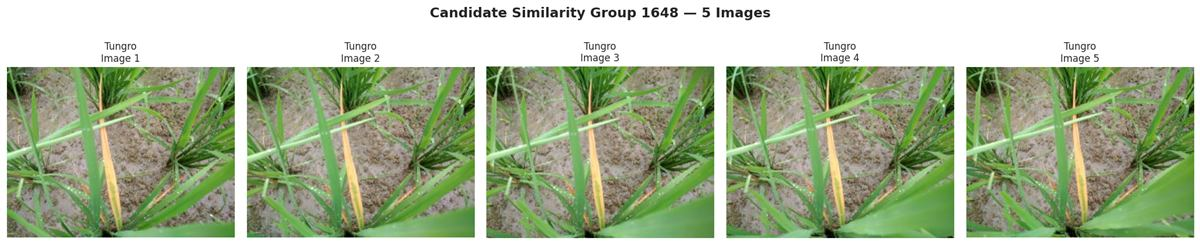

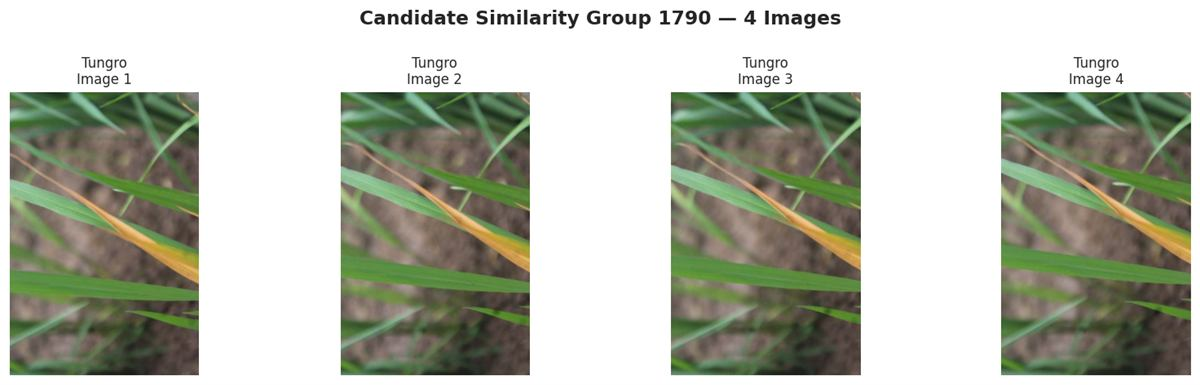

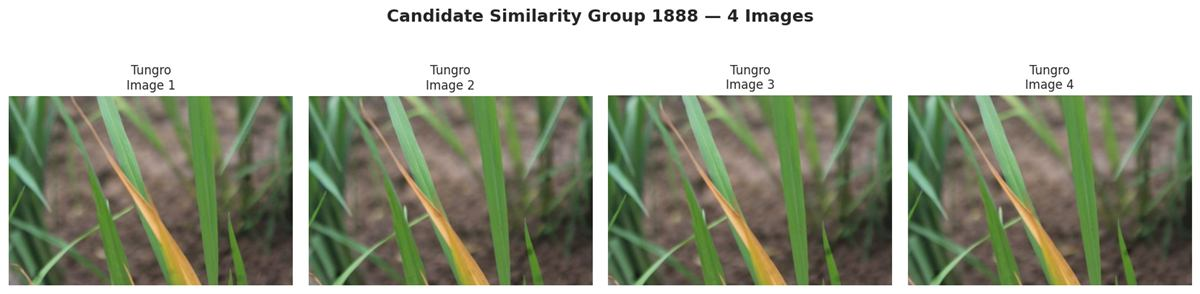

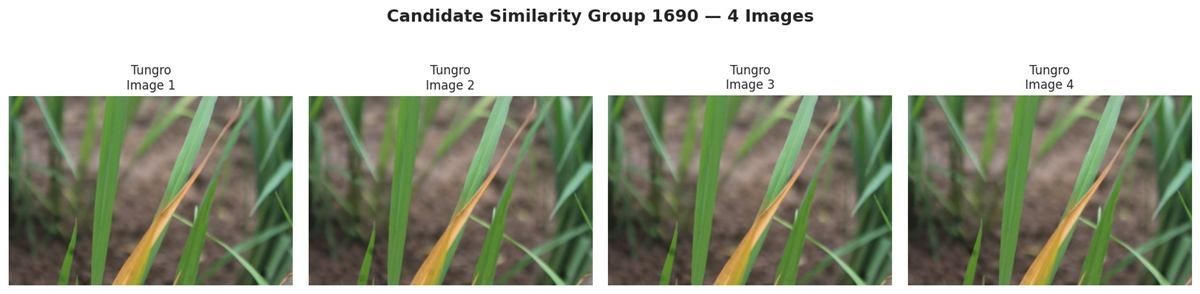

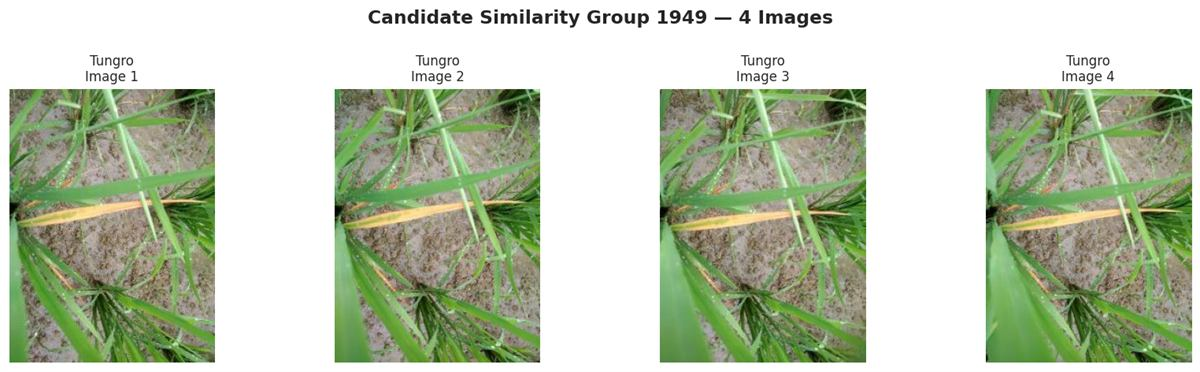

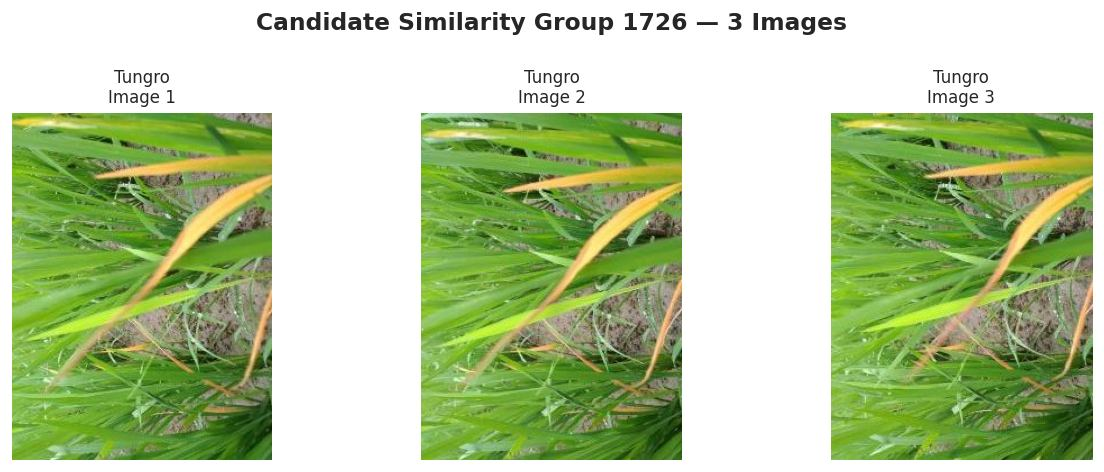

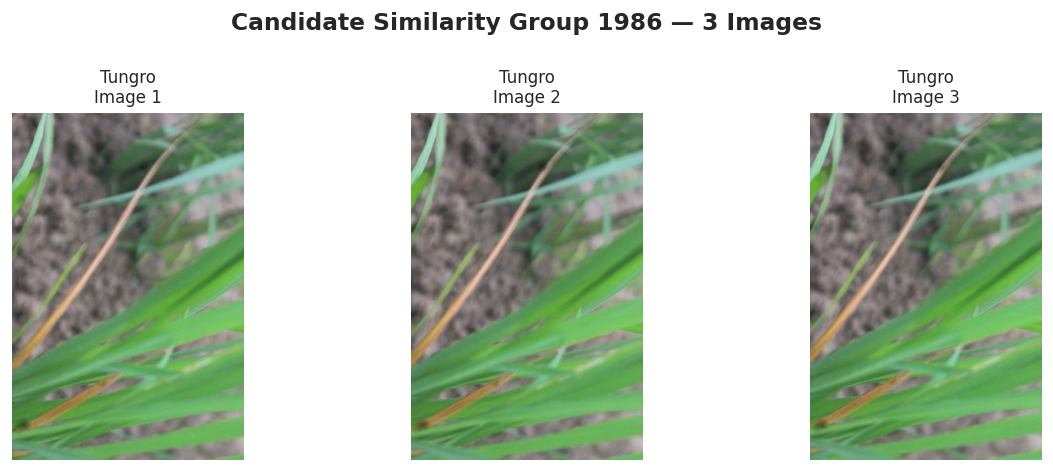

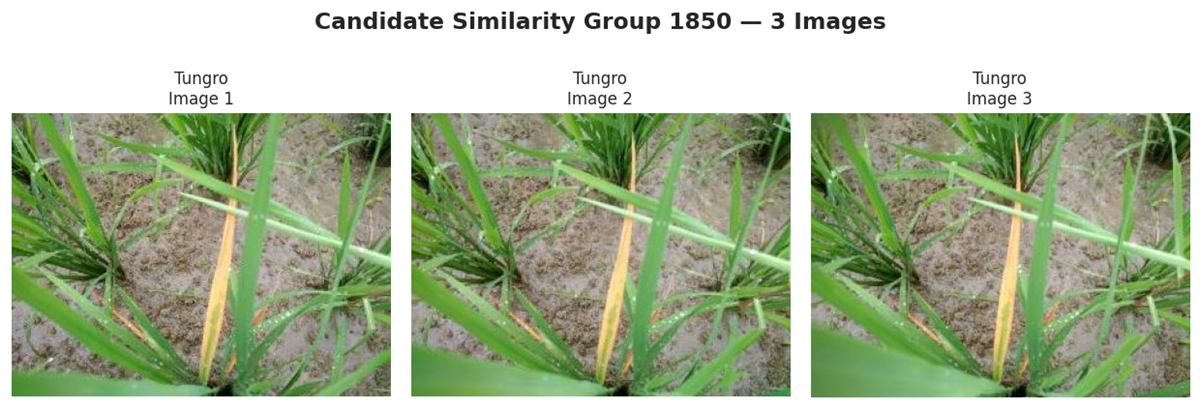

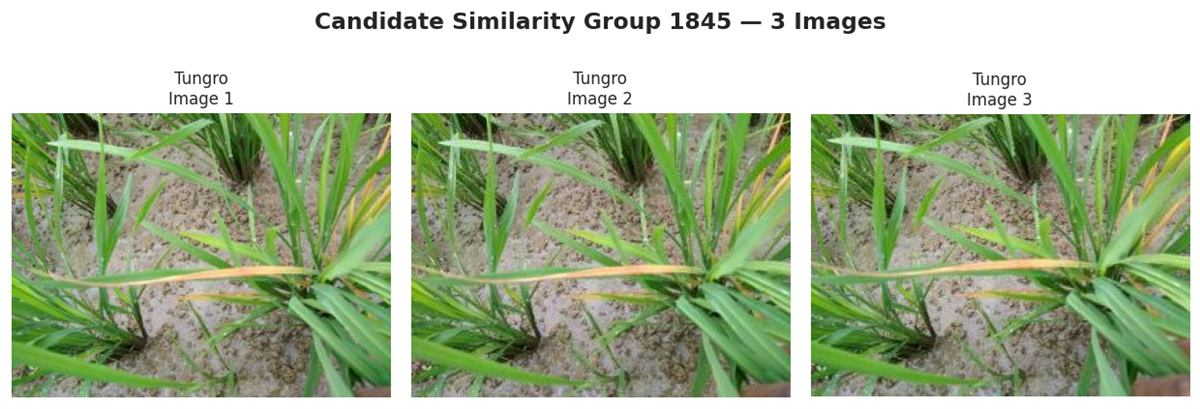

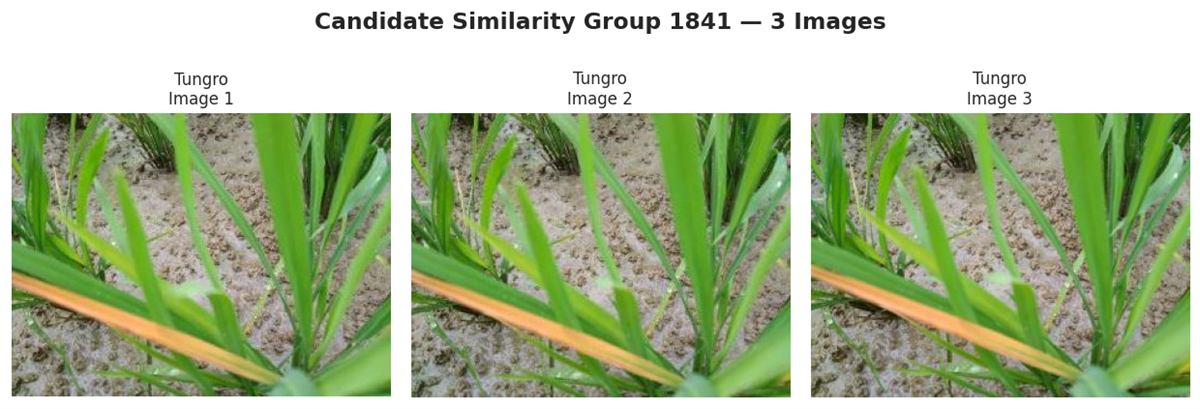

In [70]:
import matplotlib.pyplot as plt
from PIL import Image

# Select the largest non-singleton similarity groups
largest_groups = (
    audit_df.groupby("new_group")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print("Largest similarity groups:")
print(largest_groups)

for group_id, size in largest_groups.items():

    members = audit_df[
        audit_df["new_group"] == group_id
    ]

    if size < 2:
        continue

    fig, axes = plt.subplots(
        1, size,
        figsize=(3.5 * size, 4),
        squeeze=False
    )

    for i, (_, row) in enumerate(members.iterrows()):

        with Image.open(row["filepath"]) as img:
            axes[0, i].imshow(img.convert("RGB"))

        axes[0, i].set_title(
            f"{row['class']}\nImage {i+1}",
            fontsize=10
        )
        axes[0, i].axis("off")

    plt.suptitle(
        f"Candidate Similarity Group {group_id} "
        f"— {size} Images",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

## 11. Corrected Grouped Split

A corrected split is created using similarity groups so that near-duplicate images stay within the same partition. This gives a fairer estimate of model performance.


### Cell 64: Rebuild Similarity Groups for Audit

Creates updated similarity groups for the full representative dataset using a stricter leakage-audit process.


In [71]:
import numpy as np
import pandas as pd

from sklearn.model_selection import (
    StratifiedGroupKFold
)

SEED = 42

data = audit_df.copy().reset_index(drop=True)

X = data["filepath"]
y = data["class"]
groups = data["new_group"]

# Select approximately 15% of data for testing
# Using 7 folds gives about 14.3%
sgkf_test = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=SEED
)

trainval_idx, test_idx = next(
    sgkf_test.split(X, y, groups)
)

trainval_data = data.iloc[trainval_idx].copy()
test_clean_df = data.iloc[test_idx].copy()

# From remaining ~85.7%, select ~17.5% for validation
# 6 folds gives approximately 16.7% of remaining
sgkf_val = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=SEED
)

train_idx, val_idx = next(
    sgkf_val.split(
        trainval_data["filepath"],
        trainval_data["class"],
        trainval_data["new_group"]
    )
)

train_clean_df = trainval_data.iloc[train_idx].copy()
val_clean_df = trainval_data.iloc[val_idx].copy()

# Reset indexes
train_clean_df = train_clean_df.reset_index(drop=True)
val_clean_df = val_clean_df.reset_index(drop=True)
test_clean_df = test_clean_df.reset_index(drop=True)

print("Corrected split results:")
print("Training:", len(train_clean_df))
print("Validation:", len(val_clean_df))
print("Testing:", len(test_clean_df))

print("\nTotal:",
      len(train_clean_df)
      + len(val_clean_df)
      + len(test_clean_df))

Corrected split results:
Training: 1531
Validation: 304
Testing: 303

Total: 2138


### Cell 65: Validate Corrected Split

Checks that the corrected train, validation, and test sets have no shared files or similarity groups.


In [72]:
splits = {
    "Train": train_clean_df,
    "Validation": val_clean_df,
    "Test": test_clean_df
}

for name, split in splits.items():
    print(f"{name}: {len(split)} images")

print("\nChecking for similarity-group leakage...")

for name_a, df_a in splits.items():
    for name_b, df_b in splits.items():

        if name_a >= name_b:
            continue

        shared_groups = (
            set(df_a["new_group"])
            & set(df_b["new_group"])
        )

        shared_paths = (
            set(df_a["filepath"])
            & set(df_b["filepath"])
        )

        print(
            f"{name_a} vs {name_b}:",
            len(shared_groups),
            "shared groups,",
            len(shared_paths),
            "shared files"
        )

        assert len(shared_groups) == 0
        assert len(shared_paths) == 0

assert sum(len(x) for x in splits.values()) == len(data)

print("\nPASSED: No detected group or filepath overlap.")

Train: 1531 images
Validation: 304 images
Test: 303 images

Checking for similarity-group leakage...
Train vs Validation: 0 shared groups, 0 shared files
Test vs Train: 0 shared groups, 0 shared files
Test vs Validation: 0 shared groups, 0 shared files

PASSED: No detected group or filepath overlap.


### Cell 66: Plot Cleaned Class Distribution

Plots the class balance after duplicate removal to check whether the dataset is still usable for supervised training.


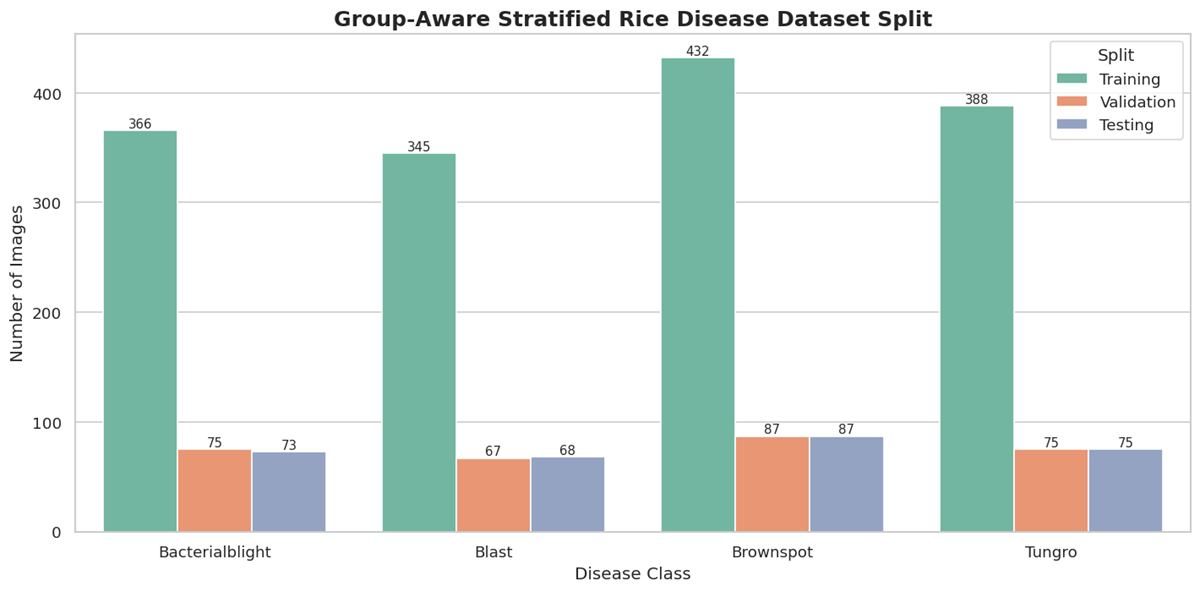


Class distribution by partition:
Split            Testing  Training  Validation
class                                         
Bacterialblight       73       366          75
Blast                 68       345          67
Brownspot             87       432          87
Tungro                75       388          75


In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = pd.concat([
    train_clean_df.assign(Split="Training"),
    val_clean_df.assign(Split="Validation"),
    test_clean_df.assign(Split="Testing")
])

plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=plot_df,
    x="class",
    hue="Split",
    palette="Set2"
)

for container in ax.containers:
    ax.bar_label(container, fontsize=9)

plt.title(
    "Group-Aware Stratified Rice Disease Dataset Split",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

print("\nClass distribution by partition:")

print(pd.crosstab(
    plot_df["class"],
    plot_df["Split"]
))

### Cell 67: Save Corrected Split Manifests

Saves the corrected train, validation, and test CSV manifests.


In [74]:
from pathlib import Path

SPLIT_DIR = Path(
    "/content/drive/MyDrive/Rice_CNN_Project/corrected_splits"
)

SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_clean_df.to_csv(SPLIT_DIR / "train.csv", index=False)
val_clean_df.to_csv(SPLIT_DIR / "validation.csv", index=False)
test_clean_df.to_csv(SPLIT_DIR / "test.csv", index=False)

print("Corrected dataset manifests saved.")

Corrected dataset manifests saved.


### Cell 68: Build Corrected TensorFlow Datasets

Creates TensorFlow datasets from the corrected split while preserving the original datasets for reference.


In [75]:
# Preserve original dataset objects for reference
train_ds_original = train_ds
val_ds_original = val_ds
test_ds_original = test_ds

# Create datasets from corrected partitions
train_ds_clean = create_dataset(
    train_clean_df,
    training=True
)

val_ds_clean = create_dataset(
    val_clean_df,
    training=False
)

test_ds_clean = create_dataset(
    test_clean_df,
    training=False
)

print("Corrected training batches:", len(train_ds_clean))
print("Corrected validation batches:", len(val_ds_clean))
print("Corrected test batches:", len(test_ds_clean))

for images, labels in train_ds_clean.take(1):
    print("\nImage shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Pixel range:",
          float(tf.reduce_min(images)),
          float(tf.reduce_max(images)))

Corrected training batches: 48
Corrected validation batches: 10
Corrected test batches: 10

Image shape: (32, 224, 224, 3)
Labels shape: (32,)
Pixel range: 0.0 1.0


### Cell 69: Validate Corrected Datasets

Confirms that the corrected TensorFlow datasets contain the expected image counts and valid batches.


In [76]:
for name, dataset, expected_count in [
    ("Training", train_ds_clean, 1531),
    ("Validation", val_ds_clean, 304),
    ("Testing", test_ds_clean, 303)
]:
    total = 0

    for images, labels in dataset:
        assert images.shape[1:] == (224, 224, 3)
        assert images.dtype == tf.float32

        assert tf.reduce_min(images).numpy() >= 0
        assert tf.reduce_max(images).numpy() <= 1

        total += len(labels)

    assert total == expected_count

    print(f"{name}: PASSED — {total} images")

print("\nAll corrected TensorFlow datasets validated.")

Training: PASSED — 1531 images
Validation: PASSED — 304 images
Testing: PASSED — 303 images

All corrected TensorFlow datasets validated.


## 12. Retraining on Corrected Splits

All major CNN variants are retrained and evaluated on the corrected split. This section provides the main comparison used to select the final model.


### Cell 70: Train CNN V1 Baseline

Trains CNN V1 with early stopping and checkpointing, then stores the training history for comparison.


In [77]:

import tensorflow as tf
from pathlib import Path

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

CLEAN_MODEL_DIR = Path(
    "/content/rice_cnn_models/corrected"
)
CLEAN_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Fresh baseline model
cnn_v1_clean = build_baseline_cnn()

callbacks_v1_clean = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            CLEAN_MODEL_DIR / "cnn_v1_clean_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(CLEAN_MODEL_DIR / "cnn_v1_clean_history.csv")
    )
]

history_v1_clean = cnn_v1_clean.fit(
    train_ds_clean,
    validation_data=val_ds_clean,
    epochs=40,
    callbacks=callbacks_v1_clean,
    verbose=1
)

print("\nCorrected CNN V1 training completed.")
print("Epochs:", len(history_v1_clean.history["loss"]))
print("Peak validation accuracy:",
      max(history_v1_clean.history["val_accuracy"]))
print("Minimum validation loss:",
      min(history_v1_clean.history["val_loss"]))


Epoch 1/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - accuracy: 0.4152 - loss: 1.2919
Epoch 1: val_loss improved from None to 0.88264, saving model to /content/rice_cnn_models/corrected/cnn_v1_clean_best.keras

Epoch 1: finished saving model to /content/rice_cnn_models/corrected/cnn_v1_clean_best.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 21s 298ms/step - accuracy: 0.4788 - loss: 1.1725 - val_accuracy: 0.6612 - val_loss: 0.8826
Epoch 2/40
47/48 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.6874 - loss: 0.7857
Epoch 2: val_loss improved from 0.88264 to 0.67661, saving model to /content/rice_cnn_models/corrected/cnn_v1_clean_best.keras

Epoch 2: finished saving model to /content/rice_cnn_models/corrected/cnn_v1_clean_best.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.7113 - loss: 0.6851 - val_accuracy: 0.7007 - val_loss: 0.6766
Epoch 3/40
47/48 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7294 - loss: 0.6278
Epoch 3: val_loss improved from 0.67661 to 0.62026, saving model to /co

### Cell 71: Evaluate Corrected CNN V1

Evaluates CNN V1 after the corrected split and reports validation metrics.


In [79]:

import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

best_v1_clean = tf.keras.models.load_model(
    CLEAN_MODEL_DIR / "cnn_v1_clean_best.keras"
)

y_val_clean = np.concatenate([
    labels.numpy()
    for _, labels in val_ds_clean
])

prob_v1_clean = best_v1_clean.predict(
    val_ds_clean,
    verbose=0
)

pred_v1_clean = np.argmax(prob_v1_clean, axis=1)

v1_clean_accuracy = accuracy_score(
    y_val_clean, pred_v1_clean
)

v1_clean_f1 = f1_score(
    y_val_clean,
    pred_v1_clean,
    average="macro"
)

print("Corrected CNN V1 Results")
print("Validation accuracy:", round(v1_clean_accuracy, 4))
print("Macro-F1:", round(v1_clean_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_val_clean,
    pred_v1_clean,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))


Corrected CNN V1 Results
Validation accuracy: 0.9375
Macro-F1: 0.9365

Classification Report:
                 precision    recall  f1-score   support

Bacterialblight       0.93      0.89      0.91        75
          Blast       0.97      0.85      0.90        67
      Brownspot       0.88      0.99      0.93        87
         Tungro       1.00      1.00      1.00        75

       accuracy                           0.94       304
      macro avg       0.94      0.93      0.94       304
   weighted avg       0.94      0.94      0.94       304



### Cell 72: Plot Corrected CNN V1 Results

Plots corrected CNN V1 training curves and its validation confusion matrix after the grouped split.


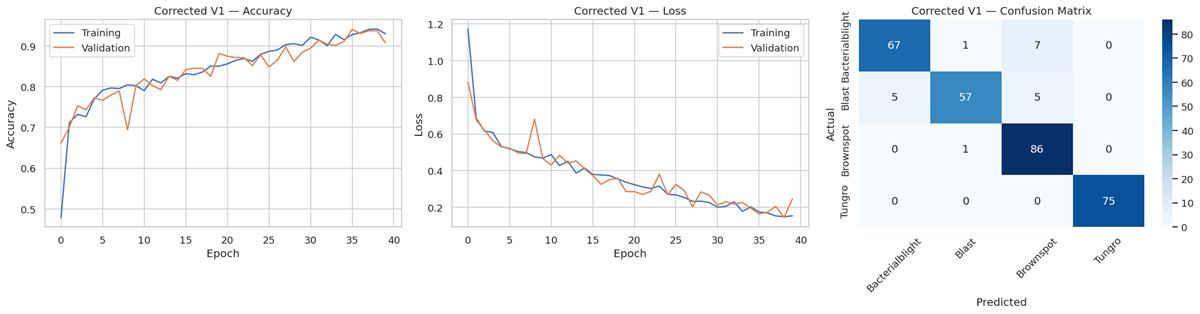

In [80]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    history_v1_clean.history["accuracy"],
    label="Training"
)
axes[0].plot(
    history_v1_clean.history["val_accuracy"],
    label="Validation"
)
axes[0].set_title("Corrected V1 — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    history_v1_clean.history["loss"],
    label="Training"
)
axes[1].plot(
    history_v1_clean.history["val_loss"],
    label="Validation"
)
axes[1].set_title("Corrected V1 — Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

cm = confusion_matrix(
    y_val_clean,
    pred_v1_clean,
    labels=range(len(class_names))
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[2]
)

axes[2].set_title("Corrected V1 — Confusion Matrix")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


### Cell 73: Retrain Corrected CNN V2

Builds and trains the corrected CNN V2 model with data augmentation on the grouped split.


In [81]:
import tensorflow as tf
from tensorflow.keras import layers
from pathlib import Path

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Independent augmentation pipeline
augmentation_v2_clean = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.10)
], name="augmentation_v2_clean")

# Fresh baseline CNN with augmentation
cnn_v2_clean = tf.keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    augmentation_v2_clean,
    build_baseline_cnn()
], name="cnn_v2_clean")

cnn_v2_clean.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_v2_clean.summary()

callbacks_v2_clean = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            CLEAN_MODEL_DIR / "cnn_v2_clean_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(CLEAN_MODEL_DIR / "cnn_v2_clean_history.csv")
    )
]

history_v2_clean = cnn_v2_clean.fit(
    train_ds_clean,
    validation_data=val_ds_clean,
    epochs=40,
    callbacks=callbacks_v2_clean,
    verbose=1
)

print("\nCorrected CNN V2 training completed.")
print("Epochs:", len(history_v2_clean.history["loss"]))
print(
    "Peak validation accuracy:",
    max(history_v2_clean.history["val_accuracy"])
)
print(
    "Minimum validation loss:",
    min(history_v2_clean.history["val_loss"])
)

Model: "cnn_v2_clean"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation_v2_clean           │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 4)              │       110,276 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.3710 - loss: 1.3216
Epoch 1: val_loss improved from None to 0.76493, saving model to /content/rice_cnn_models/corrected/cnn_v2_clean_best.keras

Epoch 1: finished saving model to /content/rice_cnn_models/corrected/cnn_v2_clean_best.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 11s 163ms/step - accuracy: 0.4644 - loss: 1.1918 - val_accuracy: 0.6447 - val_loss: 0.7649
Epoch 2/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.6363 - loss: 0.7803
Epoch 2: val_loss improved from 0.76493 to 0.62701, saving model to /content/rice_cnn_models/corrected/cnn_v2_clean_best.keras

Epoch 2: finished saving model to /content/rice_cnn_models/corrected/cnn_v2_clean_best.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.6447 - loss: 0.7616 - val_accuracy: 0.7171 - val_loss: 0.6270
Epoch 3/40
47/48 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7185 - loss: 0.6051
Epoch 3: val_loss improved from 0.62701 to 0.53581, saving model to /co

### Cell 74: Retrain Corrected CNN V2

Retrains the augmented CNN V2 using the corrected split.


In [82]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

best_v2_clean = tf.keras.models.load_model(
    CLEAN_MODEL_DIR / "cnn_v2_clean_best.keras"
)

prob_v2_clean = best_v2_clean.predict(
    val_ds_clean,
    verbose=0
)

pred_v2_clean = np.argmax(prob_v2_clean, axis=1)

v2_clean_accuracy = accuracy_score(
    y_val_clean,
    pred_v2_clean
)

v2_clean_f1 = f1_score(
    y_val_clean,
    pred_v2_clean,
    average="macro"
)

print("CNN V2 — Corrected Validation Results")
print("Accuracy:", round(v2_clean_accuracy, 4))
print("Macro-F1:", round(v2_clean_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_val_clean,
    pred_v2_clean,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

comparison_v1_v2 = pd.DataFrame([
    {
        "Model": "CNN V1",
        "Accuracy": v1_clean_accuracy,
        "Macro F1": v1_clean_f1
    },
    {
        "Model": "CNN V2",
        "Accuracy": v2_clean_accuracy,
        "Macro F1": v2_clean_f1
    }
])

display(comparison_v1_v2.round(4))

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


CNN V2 — Corrected Validation Results
Accuracy: 0.9474
Macro-F1: 0.9463

Classification Report:
                 precision    recall  f1-score   support

Bacterialblight       0.96      0.95      0.95        75
          Blast       0.87      0.91      0.89        67
      Brownspot       0.95      0.93      0.94        87
         Tungro       1.00      1.00      1.00        75

       accuracy                           0.95       304
      macro avg       0.95      0.95      0.95       304
   weighted avg       0.95      0.95      0.95       304



,Model,Accuracy,Macro F1
0,CNN V1,0.9375,0.9365
1,CNN V2,0.9474,0.9463


### Cell 75: Compare Corrected CNN V1 and V2

Compares corrected CNN V1 and CNN V2 training curves and validation behavior.


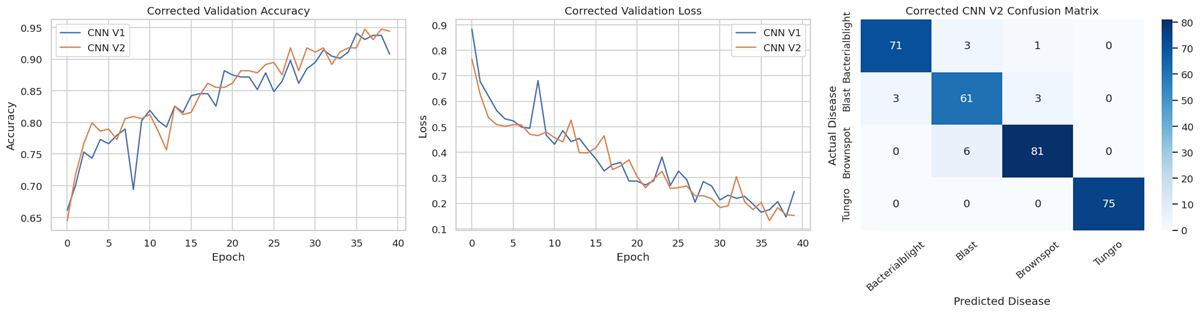

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for name, history in {
    "CNN V1": history_v1_clean,
    "CNN V2": history_v2_clean
}.items():
    axes[0].plot(
        history.history["val_accuracy"],
        label=name
    )
    axes[1].plot(
        history.history["val_loss"],
        label=name
    )

axes[0].set_title("Corrected Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].set_title("Corrected Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

cm_v2_clean = confusion_matrix(
    y_val_clean,
    pred_v2_clean,
    labels=range(len(class_names))
)

sns.heatmap(
    cm_v2_clean,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[2]
)

axes[2].set_title("Corrected CNN V2 Confusion Matrix")
axes[2].set_xlabel("Predicted Disease")
axes[2].set_ylabel("Actual Disease")
axes[2].tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.show()

### Cell 76: Retrain Corrected CNN V3

Builds and trains CNN V3 again using the corrected grouped split.


In [84]:

import tensorflow as tf
from pathlib import Path

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

CLEAN_MODEL_DIR = Path(
    "/content/rice_cnn_models/corrected"
)
CLEAN_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Fresh V3 model: Augmentation + BatchNorm + Dropout
cnn_v3_clean = build_cnn_v3()

print("Corrected CNN V3")
cnn_v3_clean.summary()

callbacks_v3_clean = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            CLEAN_MODEL_DIR / "cnn_v3_clean_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(CLEAN_MODEL_DIR / "cnn_v3_clean_history.csv")
    )
]

history_v3_clean = cnn_v3_clean.fit(
    train_ds_clean,
    validation_data=val_ds_clean,
    epochs=40,
    callbacks=callbacks_v3_clean,
    verbose=1
)

print("\nCorrected CNN V3 training completed.")
print("Epochs:", len(history_v3_clean.history["loss"]))
print("Peak validation accuracy:",
      max(history_v3_clean.history["val_accuracy"]))
print("Minimum validation loss:",
      min(history_v3_clean.history["val_loss"]))


Corrected CNN V3


Model: "cnn_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_v3 (Sequential)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,948 (433.39 KB)

 Trainable params: 110,500 (431.64 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.6652 - loss: 0.8729
Epoch 1: val_loss improved from None to 1.55710, saving model to /content/rice_cnn_models/corrected/cnn_v3_clean_best.keras

Epoch 1: finished saving model to /content/rice_cnn_models/corrected/cnn_v3_clean_best.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 18s 187ms/step - accuracy: 0.7420 - loss: 0.6874 - val_accuracy: 0.2961 - val_loss: 1.5571
Epoch 2/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.8159 - loss: 0.4924
Epoch 2: val_loss did not improve from 1.55710
48/48 ━━━━━━━━━━━━━━━━━━━━ 8s 158ms/step - accuracy: 0.8289 - loss: 0.4644 - val_accuracy: 0.2862 - val_loss: 1.9646
Epoch 3/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.8470 - loss: 0.4082
Epoch 3: val_loss did not improve from 1.55710
48/48 ━━━━━━━━━━━━━━━━━━━━ 10s 148ms/step - accuracy: 0.8491 - loss: 0.4017 - val_accuracy: 0.3454 - val_loss: 1.9736
Epoch 4/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.8584 - loss

### Cell 77: Evaluate Corrected CNN V3

Evaluates corrected CNN V3 and plots its validation confusion matrix.


CNN V3 — Corrected Validation Results
Accuracy: 0.9803
Macro-F1: 0.9795

Classification Report:
                 precision    recall  f1-score   support

Bacterialblight       0.96      1.00      0.98        75
          Blast       0.96      0.96      0.96        67
      Brownspot       1.00      0.97      0.98        87
         Tungro       1.00      1.00      1.00        75

       accuracy                           0.98       304
      macro avg       0.98      0.98      0.98       304
   weighted avg       0.98      0.98      0.98       304



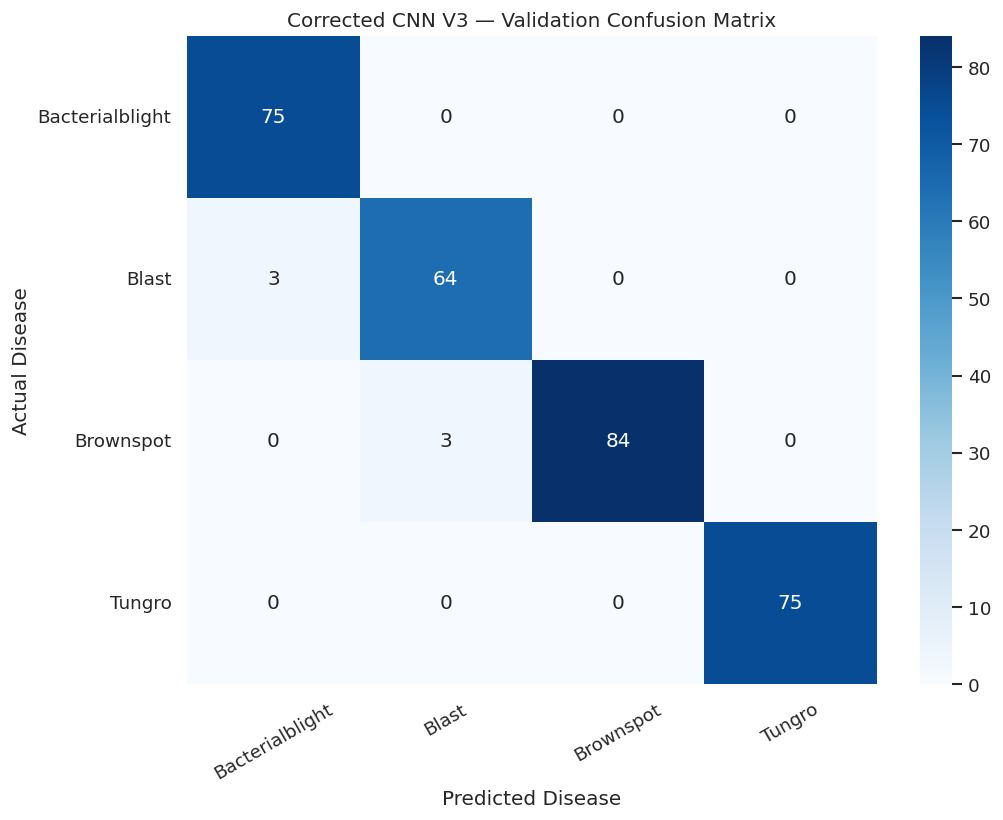

In [85]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

best_v3_clean = tf.keras.models.load_model(
    CLEAN_MODEL_DIR / "cnn_v3_clean_best.keras",
    compile=False
)

prob_v3_clean = best_v3_clean.predict(
    val_ds_clean, verbose=0
)

pred_v3_clean = np.argmax(prob_v3_clean, axis=1)

v3_clean_accuracy = accuracy_score(
    y_val_clean, pred_v3_clean
)

v3_clean_f1 = f1_score(
    y_val_clean,
    pred_v3_clean,
    average="macro",
    zero_division=0
)

print("CNN V3 — Corrected Validation Results")
print("Accuracy:", round(v3_clean_accuracy, 4))
print("Macro-F1:", round(v3_clean_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_val_clean,
    pred_v3_clean,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

cm_v3_clean = confusion_matrix(
    y_val_clean,
    pred_v3_clean,
    labels=range(len(class_names))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_v3_clean,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Corrected CNN V3 — Validation Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=30)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Cell 78: Retrain Corrected CNN V4

Builds and trains CNN V4 with the lower learning rate using the corrected grouped split.


In [86]:

import tensorflow as tf
from pathlib import Path

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Fresh V3 architecture with modified learning rate
cnn_v4_clean = build_cnn_v3()

cnn_v4_clean.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_v4_clean = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            CLEAN_MODEL_DIR / "cnn_v4_clean_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(CLEAN_MODEL_DIR / "cnn_v4_clean_history.csv")
    )
]

history_v4_clean = cnn_v4_clean.fit(
    train_ds_clean,
    validation_data=val_ds_clean,
    epochs=40,
    callbacks=callbacks_v4_clean,
    verbose=1
)

print("\nCorrected CNN V4 training completed.")
print("Epochs:", len(history_v4_clean.history["loss"]))
print("Peak validation accuracy:",
      max(history_v4_clean.history["val_accuracy"]))
print("Minimum validation loss:",
      min(history_v4_clean.history["val_loss"]))


Epoch 1/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.5478 - loss: 1.0948
Epoch 1: val_loss improved from None to 1.42023, saving model to /content/rice_cnn_models/corrected/cnn_v4_clean_best.keras

Epoch 1: finished saving model to /content/rice_cnn_models/corrected/cnn_v4_clean_best.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 13s 154ms/step - accuracy: 0.6845 - loss: 0.8521 - val_accuracy: 0.2862 - val_loss: 1.4202
Epoch 2/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.8088 - loss: 0.5646
Epoch 2: val_loss did not improve from 1.42023
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 133ms/step - accuracy: 0.8158 - loss: 0.5350 - val_accuracy: 0.2862 - val_loss: 1.6129
Epoch 3/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.8419 - loss: 0.4400
Epoch 3: val_loss did not improve from 1.42023
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 127ms/step - accuracy: 0.8308 - loss: 0.4637 - val_accuracy: 0.2862 - val_loss: 1.8501
Epoch 4/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.8480 - loss:

### Cell 79: Evaluate Corrected CNN V4

Evaluates corrected CNN V4. This validation result supports selecting CNN V4 as the final model.


CNN V4 — Corrected Validation Results
Accuracy: 0.9868
Macro-F1: 0.9867

Classification Report:
                 precision    recall  f1-score   support

Bacterialblight       0.99      0.99      0.99        75
          Blast       0.98      0.97      0.98        67
      Brownspot       0.98      0.99      0.98        87
         Tungro       1.00      1.00      1.00        75

       accuracy                           0.99       304
      macro avg       0.99      0.99      0.99       304
   weighted avg       0.99      0.99      0.99       304



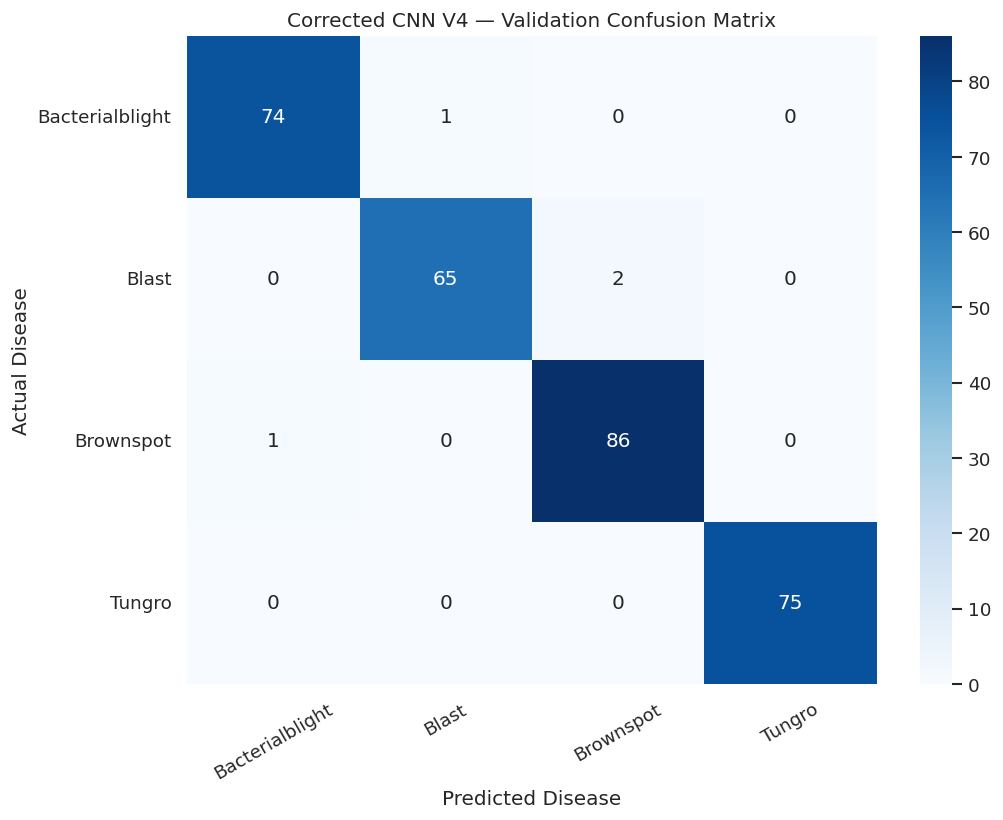

In [87]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

best_v4_clean = tf.keras.models.load_model(
    CLEAN_MODEL_DIR / "cnn_v4_clean_best.keras",
    compile=False
)

prob_v4_clean = best_v4_clean.predict(
    val_ds_clean,
    verbose=0
)

pred_v4_clean = np.argmax(prob_v4_clean, axis=1)

v4_clean_accuracy = accuracy_score(
    y_val_clean, pred_v4_clean
)

v4_clean_f1 = f1_score(
    y_val_clean,
    pred_v4_clean,
    average="macro",
    zero_division=0
)

print("CNN V4 — Corrected Validation Results")
print("Accuracy:", round(v4_clean_accuracy, 4))
print("Macro-F1:", round(v4_clean_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_val_clean,
    pred_v4_clean,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

cm_v4_clean = confusion_matrix(
    y_val_clean,
    pred_v4_clean,
    labels=range(len(class_names))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_v4_clean,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Corrected CNN V4 — Validation Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=30)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Cell 80: Compare Corrected CNN V3 and V4

Compares corrected CNN V3 and CNN V4 training curves to judge stability and validation performance.


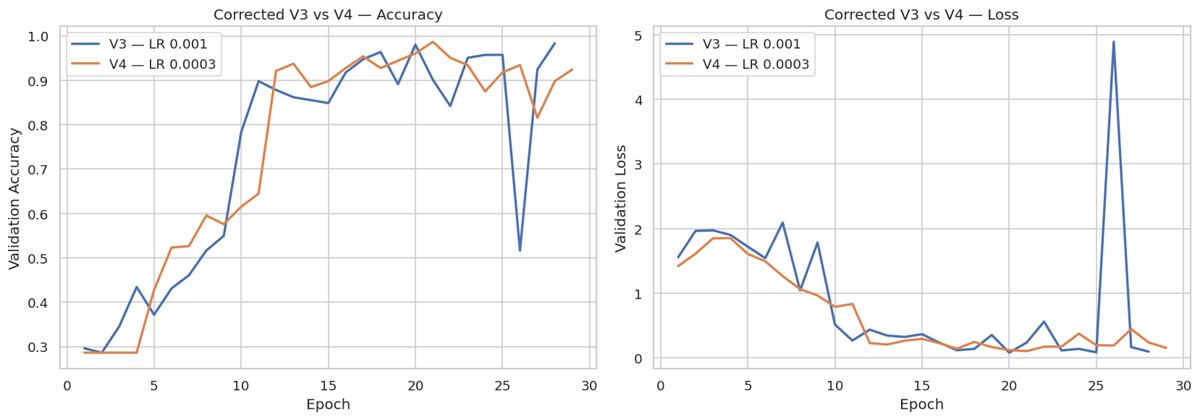


CNN V3
Peak accuracy: 0.9836
Minimum loss: 0.0802
Last 10 epochs accuracy std: 0.1314

CNN V4
Peak accuracy: 0.9868
Minimum loss: 0.1049
Last 10 epochs accuracy std: 0.0457


In [88]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in {
    "V3 — LR 0.001": history_v3_clean,
    "V4 — LR 0.0003": history_v4_clean
}.items():

    epochs = np.arange(
        1, len(history.history["val_accuracy"]) + 1
    )

    axes[0].plot(
        epochs,
        history.history["val_accuracy"],
        label=name,
        linewidth=2
    )

    axes[1].plot(
        epochs,
        history.history["val_loss"],
        label=name,
        linewidth=2
    )

axes[0].set_title("Corrected V3 vs V4 — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Accuracy")

axes[1].set_title("Corrected V3 vs V4 — Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Loss")

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

for name, history in {
    "CNN V3": history_v3_clean,
    "CNN V4": history_v4_clean
}.items():

    accuracy = np.array(
        history.history["val_accuracy"]
    )

    print(f"\n{name}")
    print("Peak accuracy:", round(accuracy.max(), 4))
    print("Minimum loss:", round(
        min(history.history["val_loss"]), 4
    ))
    print("Last 10 epochs accuracy std:",
          round(accuracy[-10:].std(), 4))


### Cell 81: Retrain Corrected CNN V5

Builds and trains corrected CNN V5 without dropout on the grouped split.


In [89]:

import tensorflow as tf
from pathlib import Path

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Fresh V5 architecture: BatchNorm, no Dropout
cnn_v5_clean = build_cnn_v5()

print("Corrected CNN V5 — No Dropout")
cnn_v5_clean.summary()

callbacks_v5_clean = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            CLEAN_MODEL_DIR / "cnn_v5_clean_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(CLEAN_MODEL_DIR / "cnn_v5_clean_history.csv")
    )
]

history_v5_clean = cnn_v5_clean.fit(
    train_ds_clean,
    validation_data=val_ds_clean,
    epochs=40,
    callbacks=callbacks_v5_clean,
    verbose=1
)

print("\nCorrected V5 training completed.")
print("Epochs:", len(history_v5_clean.history["loss"]))
print("Peak validation accuracy:",
      max(history_v5_clean.history["val_accuracy"]))
print("Minimum validation loss:",
      min(history_v5_clean.history["val_loss"]))


Corrected CNN V5 — No Dropout


Model: "cnn_v5_no_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_v5 (Sequential)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,948 (433.39 KB)

 Trainable params: 110,500 (431.64 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.7000 - loss: 0.7840
Epoch 1: val_loss improved from None to 1.60497, saving model to /content/rice_cnn_models/corrected/cnn_v5_clean_best.keras

Epoch 1: finished saving model to /content/rice_cnn_models/corrected/cnn_v5_clean_best.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 15s 163ms/step - accuracy: 0.7701 - loss: 0.6272 - val_accuracy: 0.2862 - val_loss: 1.6050
Epoch 2/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.8443 - loss: 0.4448
Epoch 2: val_loss did not improve from 1.60497
48/48 ━━━━━━━━━━━━━━━━━━━━ 9s 131ms/step - accuracy: 0.8413 - loss: 0.4255 - val_accuracy: 0.3487 - val_loss: 2.0382
Epoch 3/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.8513 - loss: 0.3948
Epoch 3: val_loss did not improve from 1.60497
48/48 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - accuracy: 0.8596 - loss: 0.3669 - val_accuracy: 0.4013 - val_loss: 1.9688
Epoch 4/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.8792 - loss:

### Cell 82: Evaluate Corrected CNN V5

Evaluates corrected CNN V5 and plots its validation confusion matrix.


Corrected CNN V5 — Validation Results
Accuracy: 0.9474
Macro-F1: 0.9464

Classification Report:
                 precision    recall  f1-score   support

Bacterialblight       0.88      1.00      0.94        75
          Blast       1.00      0.85      0.92        67
      Brownspot       0.95      0.93      0.94        87
         Tungro       0.97      1.00      0.99        75

       accuracy                           0.95       304
      macro avg       0.95      0.95      0.95       304
   weighted avg       0.95      0.95      0.95       304



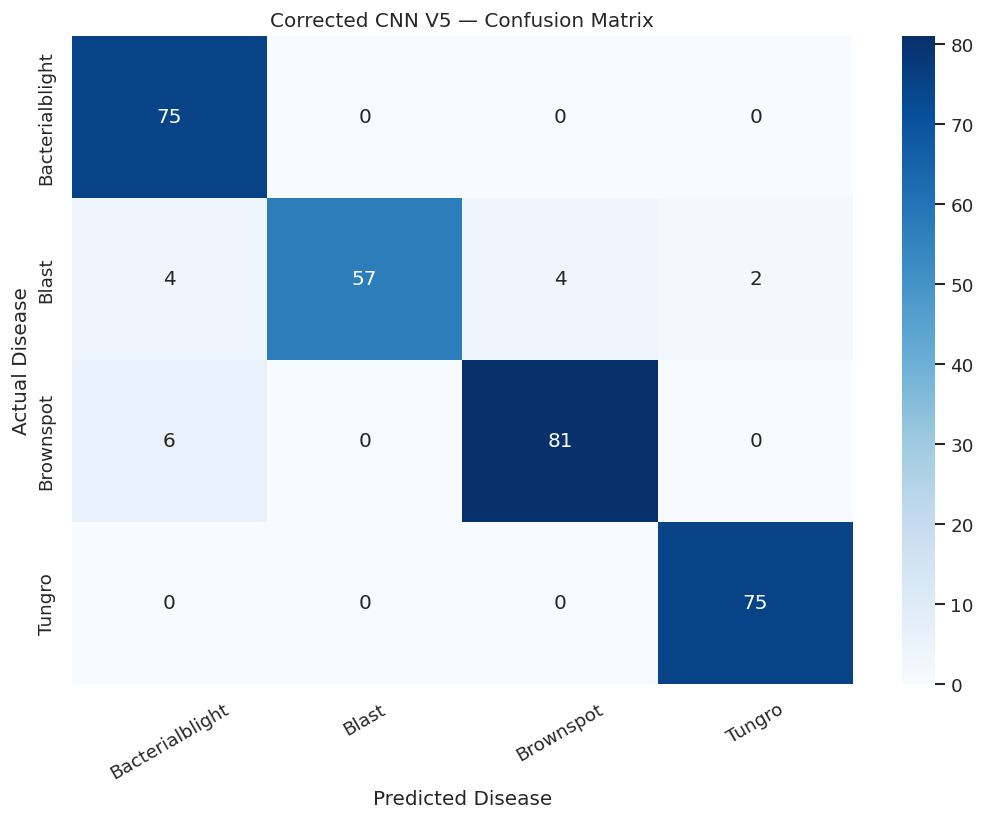

In [90]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

best_v5_clean = tf.keras.models.load_model(
    CLEAN_MODEL_DIR / "cnn_v5_clean_best.keras",
    compile=False
)

prob_v5_clean = best_v5_clean.predict(
    val_ds_clean,
    verbose=0
)

pred_v5_clean = np.argmax(prob_v5_clean, axis=1)

v5_clean_accuracy = accuracy_score(
    y_val_clean, pred_v5_clean
)

v5_clean_f1 = f1_score(
    y_val_clean,
    pred_v5_clean,
    average="macro",
    zero_division=0
)

print("Corrected CNN V5 — Validation Results")
print("Accuracy:", round(v5_clean_accuracy, 4))
print("Macro-F1:", round(v5_clean_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_val_clean,
    pred_v5_clean,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

cm_v5_clean = confusion_matrix(
    y_val_clean,
    pred_v5_clean,
    labels=range(len(class_names))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_v5_clean,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Corrected CNN V5 — Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 13. Final Model Selection

Across the corrected validation experiments, CNN V4 provides the strongest balance of accuracy, macro-F1, and training stability. It is preserved as the final selected checkpoint.


### Cell 83: Final Corrected CNN Comparison

Compares all corrected CNN versions and identifies CNN V4 as the best final candidate.


,Model,Validation Accuracy,Macro F1,Minimum Validation Loss,Epochs Trained
0,CNN V1,0.9375,0.9365,0.1457,40
1,CNN V2,0.9474,0.9463,0.1315,40
2,CNN V3,0.9803,0.9795,0.0802,28
3,CNN V4,0.9868,0.9867,0.1049,29
4,CNN V5,0.9474,0.9464,0.1158,25


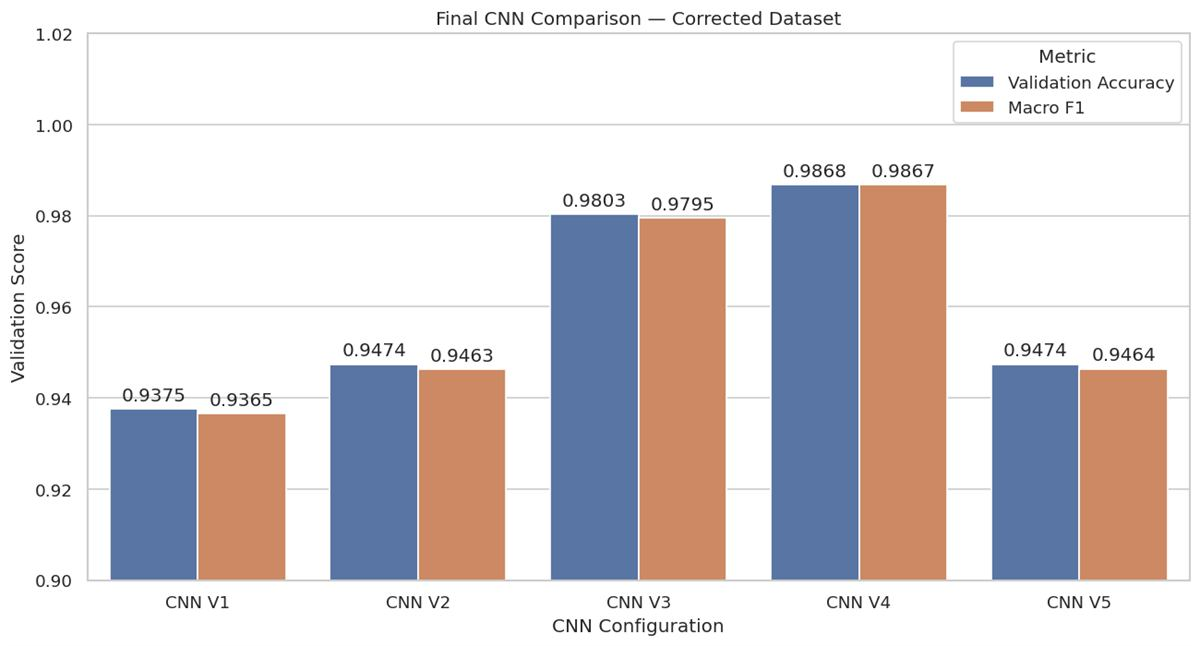

Selected model: CNN V4


In [91]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

models = [
    ("CNN V1", v1_clean_accuracy, v1_clean_f1,
     history_v1_clean),
    ("CNN V2", v2_clean_accuracy, v2_clean_f1,
     history_v2_clean),
    ("CNN V3", v3_clean_accuracy, v3_clean_f1,
     history_v3_clean),
    ("CNN V4", v4_clean_accuracy, v4_clean_f1,
     history_v4_clean),
    ("CNN V5", v5_clean_accuracy, v5_clean_f1,
     history_v5_clean)
]

final_comparison_df = pd.DataFrame([
    {
        "Model": name,
        "Validation Accuracy": accuracy,
        "Macro F1": f1,
        "Minimum Validation Loss":
            min(history.history["val_loss"]),
        "Epochs Trained":
            len(history.history["loss"])
    }
    for name, accuracy, f1, history in models
])

display(final_comparison_df.round(4))

# Comparison of accuracy and macro-F1
plot_df = final_comparison_df.melt(
    id_vars="Model",
    value_vars=["Validation Accuracy", "Macro F1"],
    var_name="Metric",
    value_name="Score"
)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

ax.set_ylim(0.90, 1.02)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

plt.title("Final CNN Comparison — Corrected Dataset")
plt.xlabel("CNN Configuration")
plt.ylabel("Validation Score")
plt.tight_layout()

plt.savefig(
    CLEAN_MODEL_DIR / "final_cnn_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

final_comparison_df.to_csv(
    CLEAN_MODEL_DIR / "final_cnn_comparison.csv",
    index=False
)

selected_model = final_comparison_df.loc[
    final_comparison_df["Macro F1"].idxmax(),
    "Model"
]

print("Selected model:", selected_model)


### Cell 84: Save Final CNN V4 Checkpoint

Preserves the selected CNN V4 model checkpoint and records the final class mapping for inference.


In [92]:

import tensorflow as tf
from pathlib import Path
import shutil
import json

SELECTED_MODEL = "CNN V4"

source_checkpoint = (
    CLEAN_MODEL_DIR / "cnn_v4_clean_best.keras"
)

final_checkpoint = (
    CLEAN_MODEL_DIR / "rice_disease_final_cnn.keras"
)

assert source_checkpoint.exists(), "V4 checkpoint missing"

# Copy the existing best checkpoint.
# No retraining or test-set evaluation.
shutil.copy2(source_checkpoint, final_checkpoint)

final_model = tf.keras.models.load_model(
    final_checkpoint,
    compile=False
)

metadata = {
    "selected_model": SELECTED_MODEL,
    "selection_metric": "Validation Macro F1",
    "validation_accuracy": float(v4_clean_accuracy),
    "validation_macro_f1": float(v4_clean_f1),
    "learning_rate": 0.0003,
    "input_shape": [224, 224, 3],
    "class_names": class_names,
    "preprocessing": "RGB, resize_with_pad, divide by 255",
    "dataset": "Corrected group-aware split",
    "test_evaluated": False
}

with open(
    CLEAN_MODEL_DIR / "final_model_metadata.json",
    "w"
) as file:
    json.dump(metadata, file, indent=4)

print("Final model checkpoint preserved.")
print("Selected model:", SELECTED_MODEL)
print("Input shape:", final_model.input_shape)
print("Output shape:", final_model.output_shape)
print("Class mapping:", class_names)


Final model checkpoint preserved.
Selected model: CNN V4
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Class mapping: ['Bacterialblight', 'Blast', 'Brownspot', 'Tungro']


## 14. Held-Out Test Evaluation

The selected CNN V4 model is evaluated on the held-out test set. These results are the most important performance evidence because the test set is not used for model selection.


### Cell 85: Evaluate Final Model on Held-Out Test Set

Runs the selected CNN V4 model on the corrected test set and reports the final test metrics.


In [93]:

import tensorflow as tf
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load the frozen selected model
final_model = tf.keras.models.load_model(
    CLEAN_MODEL_DIR / "rice_disease_final_cnn.keras",
    compile=False
)

# Obtain ground-truth labels
y_test = np.concatenate([
    labels.numpy()
    for _, labels in test_ds_clean
])

# One final inference pass
test_probabilities = final_model.predict(
    test_ds_clean,
    verbose=1
)

y_test_pred = np.argmax(
    test_probabilities,
    axis=1
)

# Calculate evaluation metrics
test_results = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Macro Precision": precision_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    )
}

# Cross-entropy loss without recompiling
test_loss = tf.keras.losses.sparse_categorical_crossentropy(
    tf.convert_to_tensor(y_test),
    tf.convert_to_tensor(test_probabilities)
)

test_results["Cross-Entropy Loss"] = float(
    tf.reduce_mean(test_loss).numpy()
)

print("\nFINAL CNN V4 — HELD-OUT TEST RESULTS")
print("=" * 45)

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_test_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

print("\nCorrect predictions:",
      np.sum(y_test == y_test_pred))

print("Incorrect predictions:",
      np.sum(y_test != y_test_pred))


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step

FINAL CNN V4 — HELD-OUT TEST RESULTS
Accuracy: 0.9868
Macro Precision: 0.9863
Macro Recall: 0.9863
Macro F1: 0.9863
Cross-Entropy Loss: 0.1084

Classification Report:

                 precision    recall  f1-score   support

Bacterialblight       0.99      0.99      0.99        73
          Blast       0.97      0.97      0.97        68
      Brownspot       0.99      0.99      0.99        87
         Tungro       1.00      1.00      1.00        75

       accuracy                           0.99       303
      macro avg       0.99      0.99      0.99       303
   weighted avg       0.99      0.99      0.99       303


Correct predictions: 299
Incorrect predictions: 4


### Cell 86: Plot Final Test Confusion Matrix

Visualizes the final model's test-set confusion matrix and class-level test performance.


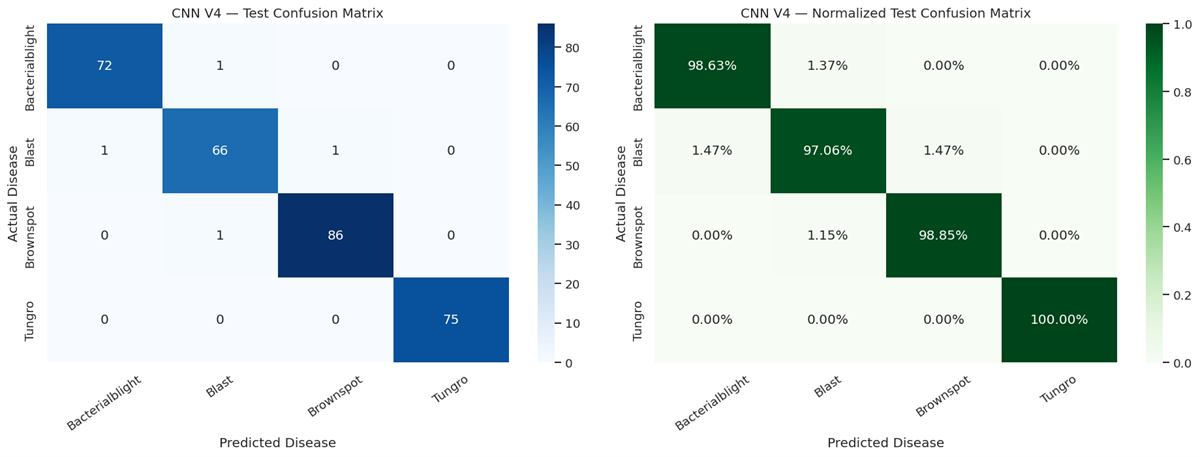

In [94]:

import matplotlib.pyplot as plt
import seaborn as sns

cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=range(len(class_names))
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw confusion matrix
sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)

axes[0].set_title("CNN V4 — Test Confusion Matrix")
axes[0].set_xlabel("Predicted Disease")
axes[0].set_ylabel("Actual Disease")

# Row-normalized matrix
sns.heatmap(
    cm_test / cm_test.sum(axis=1, keepdims=True),
    annot=True,
    fmt=".2%",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1]
)

axes[1].set_title("CNN V4 — Normalized Test Confusion Matrix")
axes[1].set_xlabel("Predicted Disease")
axes[1].set_ylabel("Actual Disease")

for ax in axes:
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()

plt.savefig(
    CLEAN_MODEL_DIR / "final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 15. Error Analysis

Misclassified test images and class probabilities are inspected to understand where the model is uncertain or confused between disease classes.


### Cell 87: Display Misclassified Test Images

Shows the test images the final model classified incorrectly for qualitative error analysis.


Misclassified images: 4


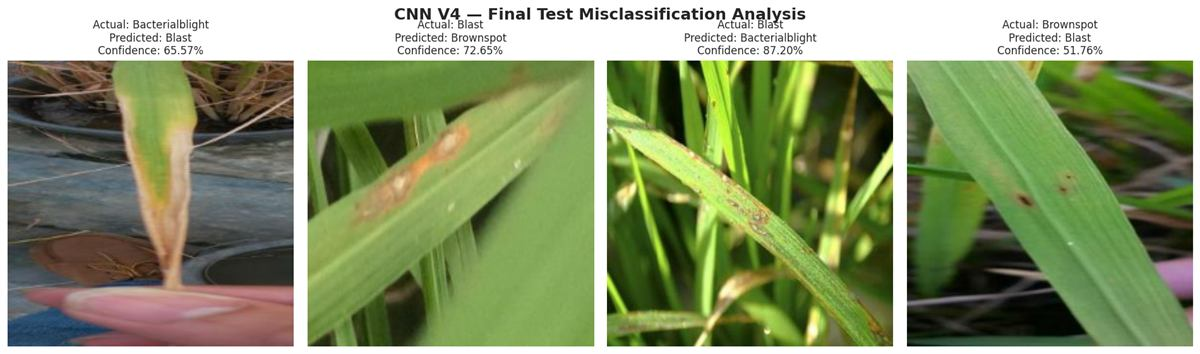

In [95]:

import numpy as np
import matplotlib.pyplot as plt

# Collect images and labels in test dataset order
test_images = np.concatenate([
    images.numpy()
    for images, labels in test_ds_clean
])

test_labels = np.concatenate([
    labels.numpy()
    for images, labels in test_ds_clean
])

# Ensure predictions correspond to the same image order
assert np.array_equal(test_labels, y_test)

incorrect_indices = np.where(
    y_test != y_test_pred
)[0]

print("Misclassified images:", len(incorrect_indices))

fig, axes = plt.subplots(
    1,
    len(incorrect_indices),
    figsize=(4 * len(incorrect_indices), 5),
    squeeze=False
)

for i, idx in enumerate(incorrect_indices):

    ax = axes[0, i]

    ax.imshow(test_images[idx])

    true_class = class_names[y_test[idx]]
    pred_class = class_names[y_test_pred[idx]]

    confidence = test_probabilities[
        idx, y_test_pred[idx]
    ]

    ax.set_title(
        f"Actual: {true_class}\n"
        f"Predicted: {pred_class}\n"
        f"Confidence: {confidence:.2%}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "CNN V4 — Final Test Misclassification Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    CLEAN_MODEL_DIR / "misclassified_test_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Cell 88: Display Misclassified Test Images

Shows the test images the final model classified incorrectly for qualitative error analysis.


,Bacterialblight,Blast,Brownspot,Tungro
Bacterialblight → Blast,0.3435,0.6557,0.0007,0.0001
Blast → Brownspot,0.0742,0.1989,0.7265,0.0003
Blast → Bacterialblight,0.8720,0.1264,0.0016,0.0001
Brownspot → Blast,0.0034,0.5176,0.4714,0.0076


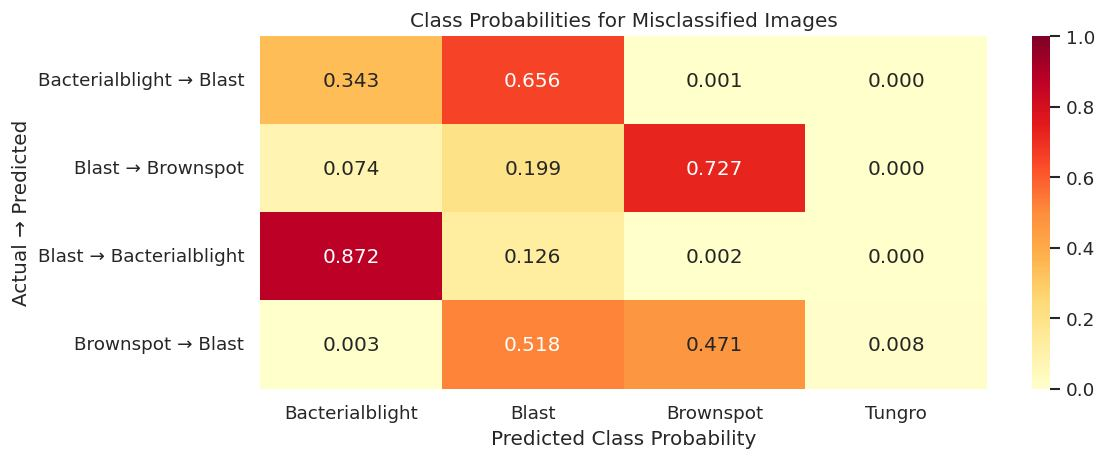

In [96]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

error_probabilities = test_probabilities[
    incorrect_indices
]

error_labels = [
    f"{class_names[y_test[idx]]} → "
    f"{class_names[y_test_pred[idx]]}"
    for idx in incorrect_indices
]

probability_df = pd.DataFrame(
    error_probabilities,
    columns=class_names,
    index=error_labels
)

display(probability_df.round(4))

plt.figure(figsize=(10, 4))

sns.heatmap(
    probability_df,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1
)

plt.title("Class Probabilities for Misclassified Images")
plt.xlabel("Predicted Class Probability")
plt.ylabel("Actual → Predicted")

plt.tight_layout()
plt.show()


## 16. Grad-CAM Interpretability

Grad-CAM visualizations highlight the image regions that most influenced the CNN predictions. This helps confirm whether the model focuses on meaningful leaf-disease patterns rather than irrelevant background areas.


### Cell 89: Prepare Grad-CAM

Builds a Grad-CAM helper model from the final CNN to inspect which image regions influence predictions.


In [97]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers

# Use frozen final CNN V4
model = tf.keras.models.load_model(
    CLEAN_MODEL_DIR / "rice_disease_final_cnn.keras",
    compile=False
)

# Identify final convolutional layer
conv_layers = [
    layer for layer in model.layers
    if isinstance(layer, layers.Conv2D)
]

assert conv_layers, "No convolutional layers found."

last_conv_layer = conv_layers[-1]

print("Grad-CAM target:", last_conv_layer.name)
print("Output shape:", last_conv_layer.output.shape)

# Output feature maps and predictions
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        last_conv_layer.output,
        model.output
    ]
)

print("Grad-CAM model ready.")


Grad-CAM target: conv2d_2
Output shape: (None, 56, 56, 128)
Grad-CAM model ready.


### Cell 90: Define Grad-CAM Function

Defines the function that computes Grad-CAM heatmaps for a selected image and class.


In [100]:

def generate_gradcam(image, grad_model, class_index=None):

    # image is already normalized and resized
    image_batch = tf.expand_dims(
        tf.convert_to_tensor(image, dtype=tf.float32),
        axis=0
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            image_batch,
            training=False
        )

        if class_index is None:
            class_index = int(
                tf.argmax(predictions[0]).numpy()
            )

        target_score = predictions[:, class_index]

    gradients = tape.gradient(
        target_score, conv_outputs
    )

    if gradients is None:
        raise RuntimeError("Grad-CAM gradients unavailable.")

    # Average gradients across spatial dimensions
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_outputs * weights[:, None, None, :],
        axis=-1
    )[0]

    # Keep positive contributions
    heatmap = tf.maximum(heatmap, 0)

    # Normalize for display
    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    # Resize to original model input dimensions
    heatmap = tf.image.resize(
        heatmap[..., None],
        (224, 224)
    )

    return heatmap.numpy().squeeze()


### Cell 91: Show Grad-CAM for Incorrect Predictions

Applies Grad-CAM to misclassified images to investigate what the model focused on when it made mistakes.


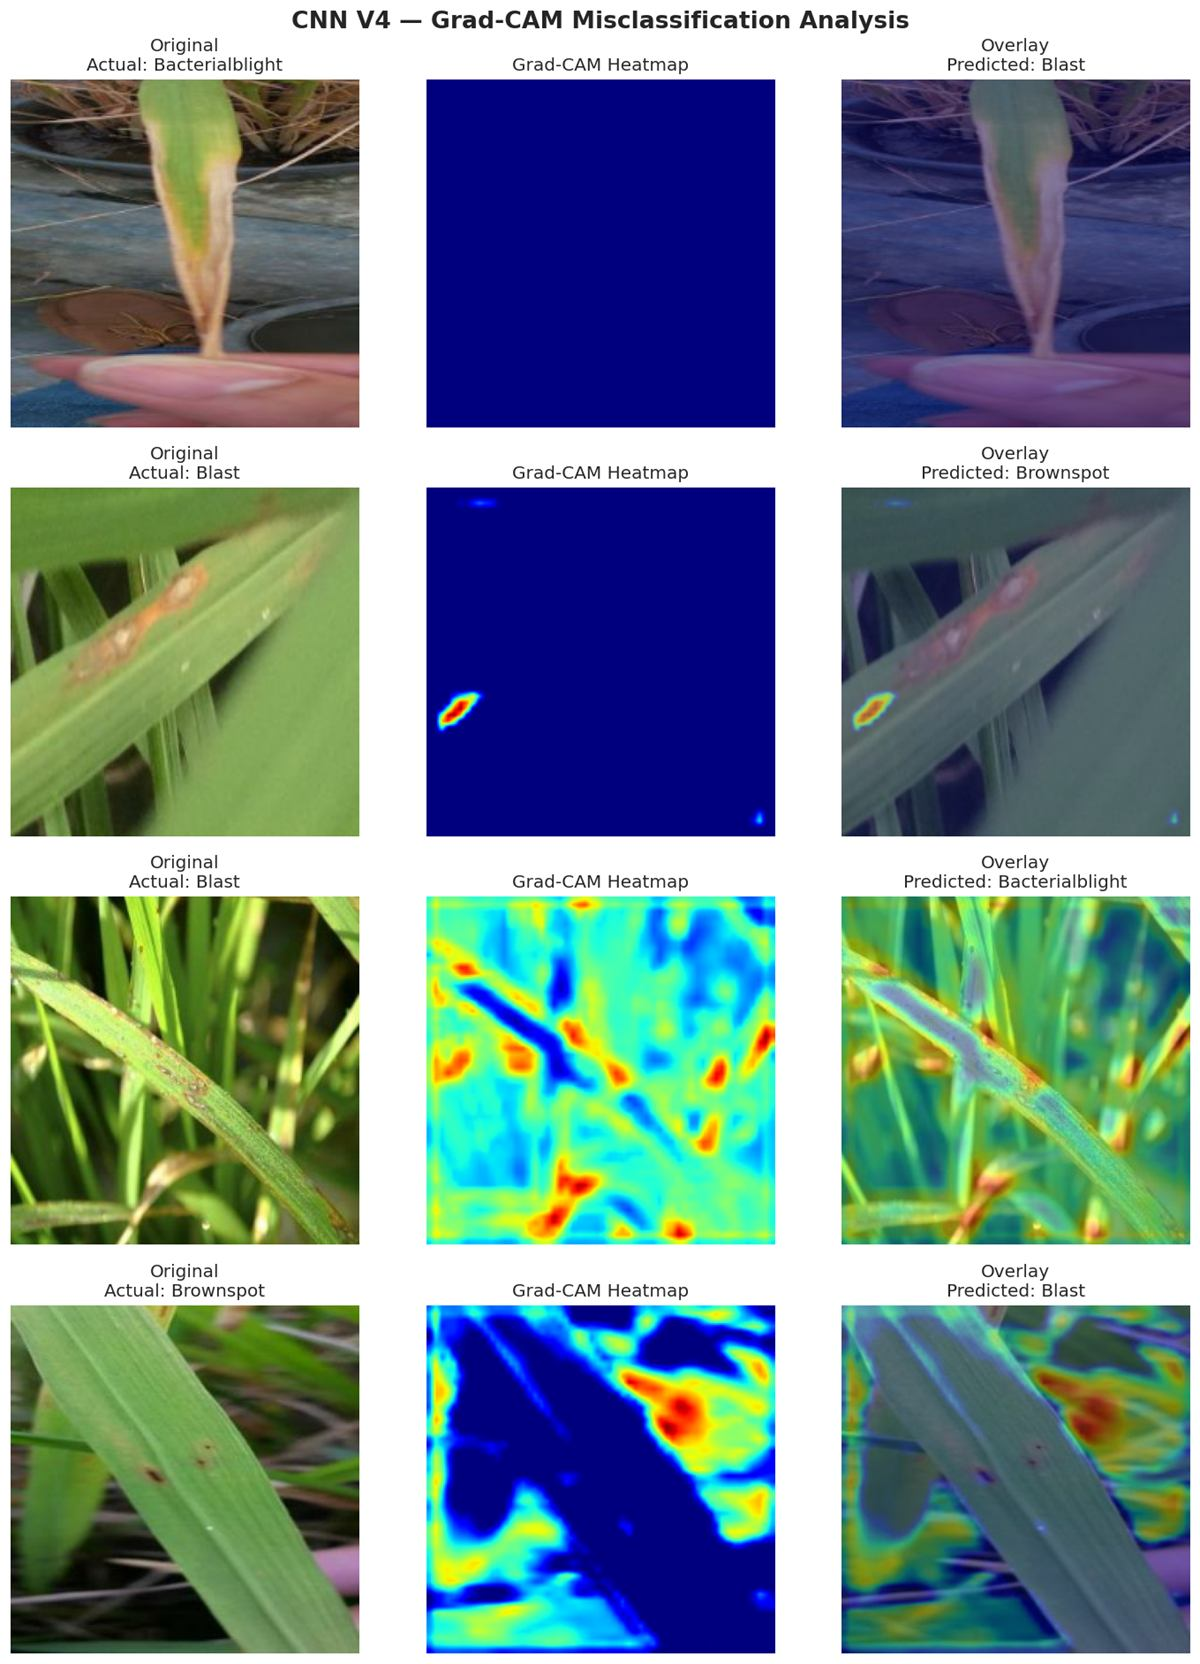

In [99]:

from matplotlib import colormaps

incorrect_indices = np.where(
    y_test != y_test_pred
)[0]

fig, axes = plt.subplots(
    len(incorrect_indices), 3,
    figsize=(12, 4 * len(incorrect_indices)),
    squeeze=False
)

for row, idx in enumerate(incorrect_indices):

    image = test_images[idx]
    actual = class_names[int(y_test[idx])]
    predicted = class_names[int(y_test_pred[idx])]

    heatmap = generate_gradcam(
        image,
        grad_model,
        class_index=int(y_test_pred[idx])
    )

    # Create colored overlay
    colors = colormaps["jet"](heatmap)[..., :3]
    overlay = np.clip(
        0.6 * image + 0.4 * colors,
        0, 1
    )

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(
        f"Original\nActual: {actual}"
    )

    axes[row, 1].imshow(
        heatmap,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[row, 1].set_title("Grad-CAM Heatmap")

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(
        f"Overlay\nPredicted: {predicted}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    "CNN V4 — Grad-CAM Misclassification Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    CLEAN_MODEL_DIR / "gradcam_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Cell 92: Define Grad-CAM Function

Defines the function that computes Grad-CAM heatmaps for a selected image and class.


In [101]:

import tensorflow as tf
import numpy as np

# Use the already-loaded final model
model = final_model

last_conv_layer = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
][-1]

# Create a feature extractor
feature_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=last_conv_layer.output
)

# Final classifier layers
gap_layer = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D)
][-1]

dense_layers = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Dense)
]

hidden_dense = dense_layers[-2]
output_dense = dense_layers[-1]

# The existing output Dense has softmax activation.
# Reuse its learned kernel and bias to compute logits.

def generate_gradcam_logits(image, class_index):

    image_batch = tf.expand_dims(
        tf.convert_to_tensor(image, dtype=tf.float32),
        axis=0
    )

    with tf.GradientTape() as tape:

        conv_output = feature_model(
            image_batch,
            training=False
        )

        x = gap_layer(conv_output)
        x = hidden_dense(x, training=False)

        # Dropout is inactive during inference.
        logits = tf.matmul(
            x, output_dense.kernel
        ) + output_dense.bias

        target = logits[:, class_index]

    gradients = tape.gradient(target, conv_output)

    if gradients is None:
        raise RuntimeError("Gradients unavailable.")

    weights = tf.reduce_mean(
        gradients, axis=(1, 2)
    )

    cam = tf.reduce_sum(
        conv_output * weights[:, None, None, :],
        axis=-1
    )[0]

    cam = tf.maximum(cam, 0)

    maximum = float(tf.reduce_max(cam).numpy())

    if maximum > 1e-8:
        cam = cam / maximum

    cam = tf.image.resize(
        cam[..., None], (224, 224)
    )

    return cam.numpy().squeeze(), maximum


### Cell 93: Code Step 93

Runs this part of the notebook workflow: `import tensorflow as tf`.


In [106]:

import tensorflow as tf
import numpy as np

# Load the final trained CNN V4
model = tf.keras.models.load_model(
    "/content/rice_cnn_models/corrected/rice_disease_final_cnn.keras",
    compile=False
)

# Find the final convolutional layer
last_conv = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
][-1]

# Find the final Dense classification layer
output_dense = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Dense)
][-1]

# Create the feature extraction model
feature_and_penultimate_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        last_conv.output,
        output_dense.input,
        model.output
    ]
)

print("Grad-CAM setup completed.")
print("Convolutional layer:", last_conv.name)
print("Output layer:", output_dense.name)


Grad-CAM setup completed.
Convolutional layer: conv2d_2
Output layer: dense_1


### Cell 94: Verify Grad-CAM Prediction Consistency

Checks that the Grad-CAM feature model produces predictions consistent with the final CNN model.


In [107]:

sample_batch = tf.convert_to_tensor(
    test_images[:8],
    dtype=tf.float32
)

original_predictions = model(
    sample_batch,
    training=False
).numpy()

_, _, extracted_predictions = (
    feature_and_penultimate_model(
        sample_batch,
        training=False
    )
)

difference = np.max(
    np.abs(
        original_predictions -
        extracted_predictions.numpy()
    )
)

print("Maximum prediction difference:", difference)

assert difference < 1e-6

print("Prediction consistency: PASSED")


Maximum prediction difference: 0.0
Prediction consistency: PASSED


### Cell 95: Define Verified Grad-CAM Function

Defines a verified Grad-CAM implementation after checking prediction consistency.


In [108]:

import tensorflow as tf
import numpy as np

def generate_verified_gradcam(image, class_index=None):

    image_batch = tf.convert_to_tensor(
        image[None, ...],
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:
        conv_features, penultimate, probabilities = (
            feature_and_penultimate_model(
                image_batch, training=False
            )
        )

        if class_index is None:
            class_index = int(tf.argmax(probabilities[0]))

        logits = tf.matmul(
            penultimate, output_dense.kernel
        )

        if output_dense.use_bias:
            logits += output_dense.bias

        score = logits[:, class_index]

    gradients = tape.gradient(score, conv_features)

    if gradients is None:
        raise RuntimeError("Grad-CAM gradients unavailable")

    weights = tf.reduce_mean(gradients, axis=(1, 2))

    heatmap = tf.reduce_sum(
        conv_features * weights[:, None, None, :],
        axis=-1
    )[0]

    heatmap = tf.maximum(heatmap, 0)

    maximum = float(tf.reduce_max(heatmap).numpy())

    if maximum > 1e-8:
        heatmap = heatmap / maximum

    heatmap = tf.image.resize(
        heatmap[..., None], (224, 224)
    )

    return heatmap.numpy().squeeze(), maximum


### Cell 96: Show Grad-CAM for Incorrect Predictions

Applies Grad-CAM to misclassified images to investigate what the model focused on when it made mistakes.


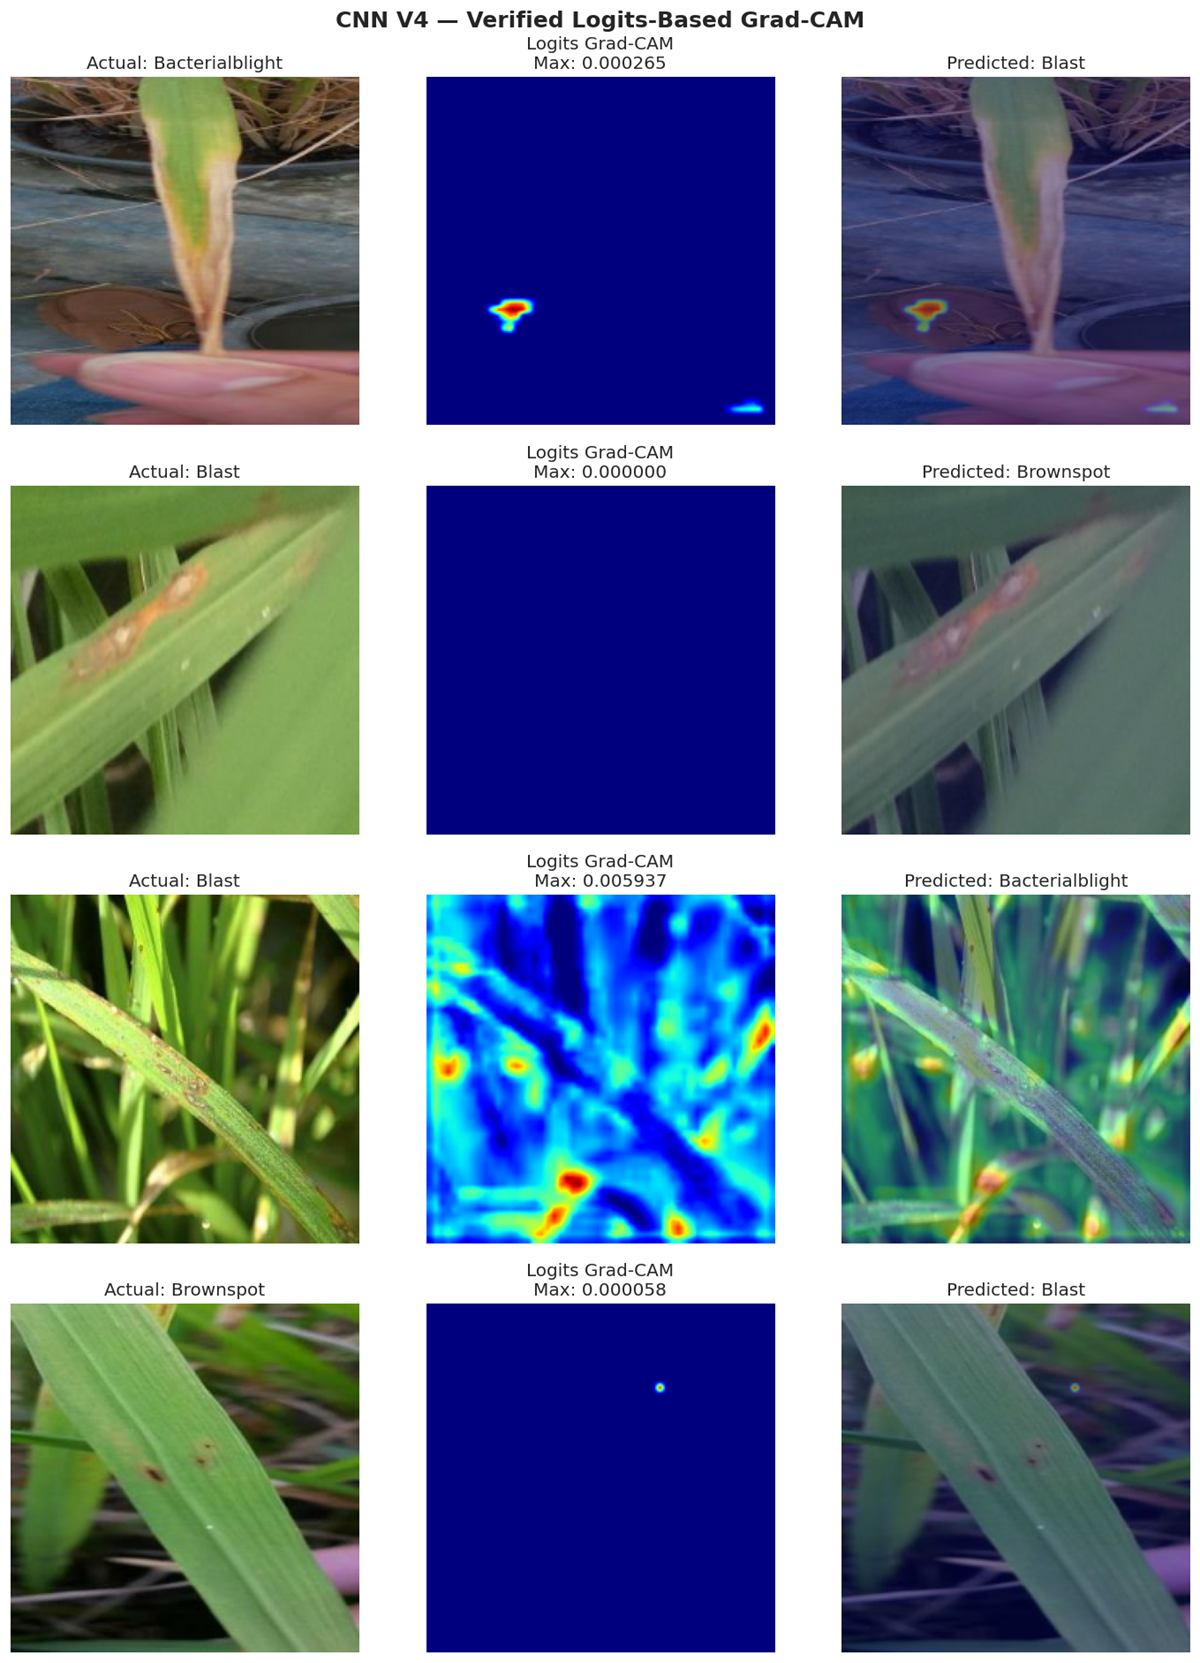

In [109]:

import matplotlib.pyplot as plt
from matplotlib import colormaps

incorrect_indices = np.where(y_test != y_test_pred)[0]

fig, axes = plt.subplots(
    len(incorrect_indices), 3,
    figsize=(12, 4 * len(incorrect_indices)),
    squeeze=False
)

for row, idx in enumerate(incorrect_indices):
    image = test_images[idx]

    actual = class_names[int(y_test[idx])]
    predicted = class_names[int(y_test_pred[idx])]

    heatmap, maximum = generate_verified_gradcam(
        image,
        class_index=int(y_test_pred[idx])
    )

    colors = colormaps["jet"](heatmap)[..., :3]

    overlay = np.clip(
        0.65 * image + 0.35 * colors, 0, 1
    )

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Actual: {actual}")

    axes[row, 1].imshow(
        heatmap, cmap="jet", vmin=0, vmax=1
    )
    axes[row, 1].set_title(
        f"Logits Grad-CAM\nMax: {maximum:.6f}"
    )

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(
        f"Predicted: {predicted}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    "CNN V4 — Verified Logits-Based Grad-CAM",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    CLEAN_MODEL_DIR / "verified_logits_gradcam.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Cell 97: Show Grad-CAM for Correct Predictions

Displays Grad-CAM heatmaps for correctly classified images to confirm the model focuses on meaningful disease regions.


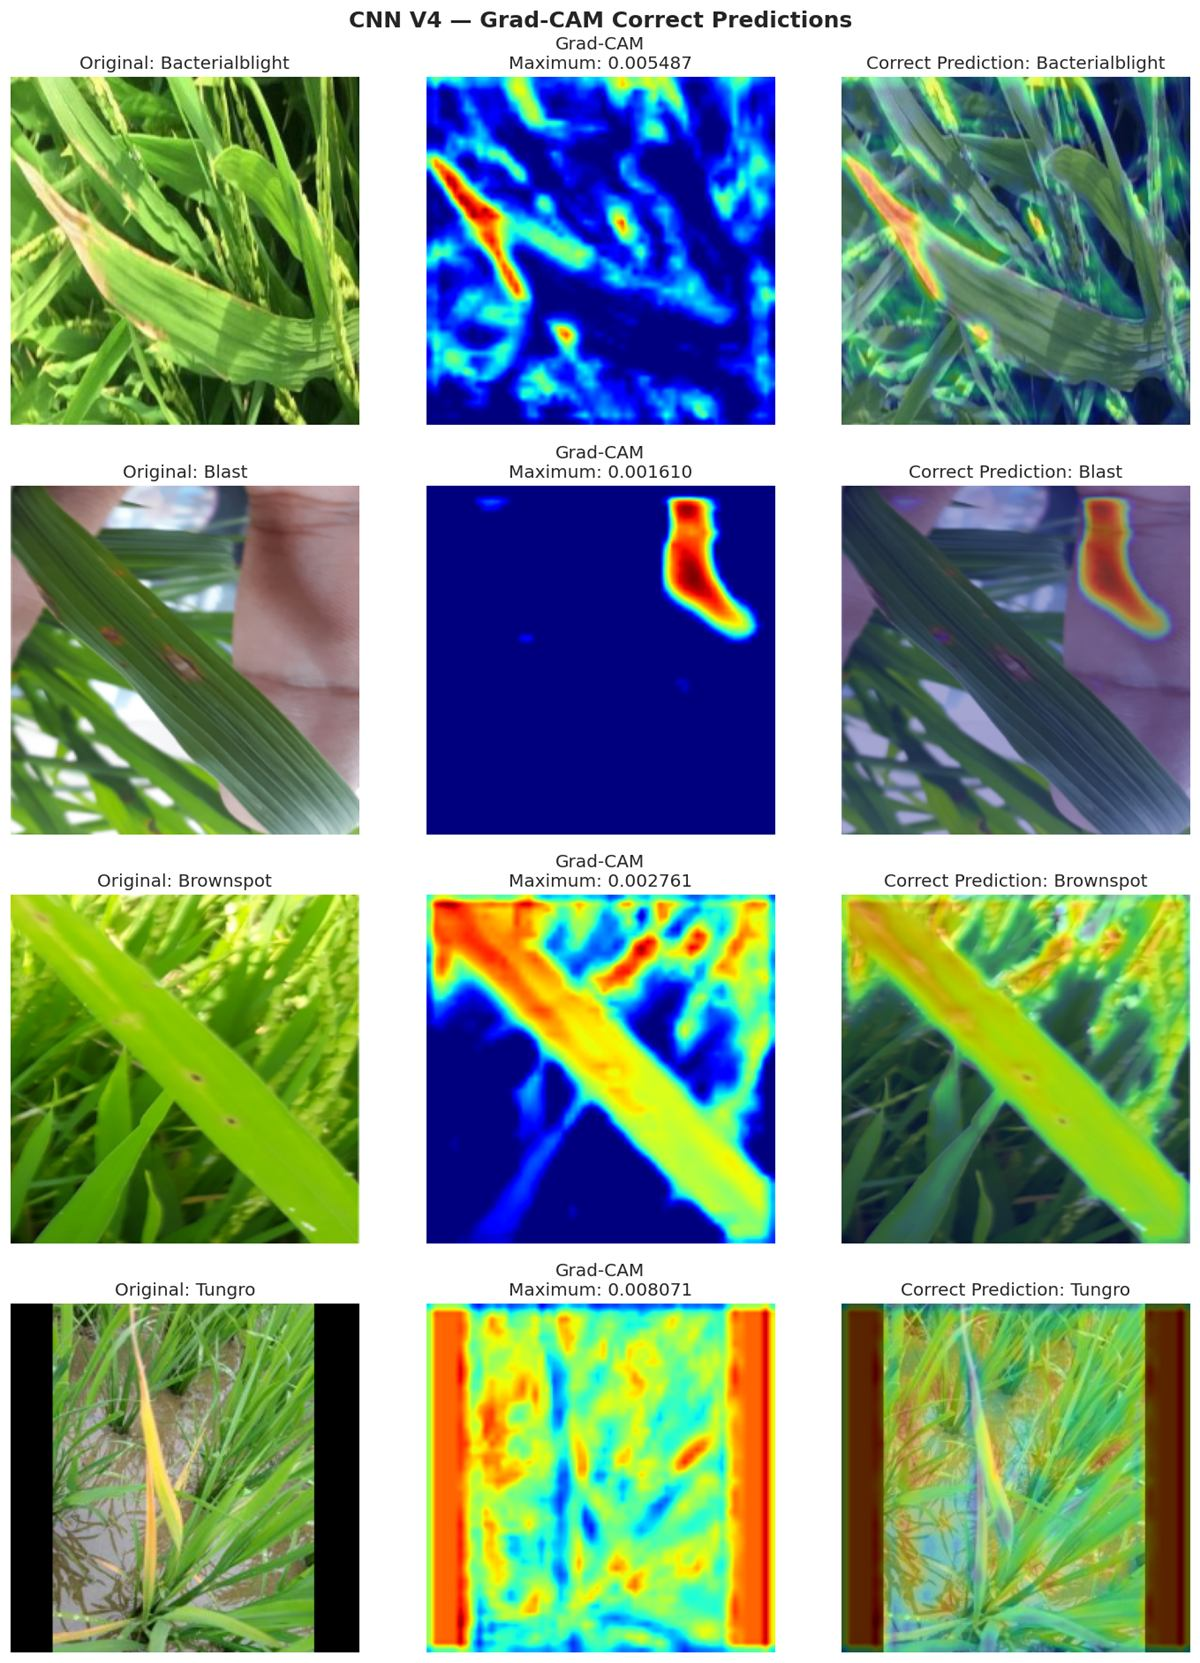

In [110]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps

# Correctly classified test images
correct_indices = np.where(
    y_test == y_test_pred
)[0]

# Select one correct example from each class
selected_indices = []

for class_index in range(len(class_names)):
    candidates = [
        idx for idx in correct_indices
        if y_test[idx] == class_index
    ]

    if candidates:
        selected_indices.append(candidates[0])

fig, axes = plt.subplots(
    len(selected_indices), 3,
    figsize=(12, 4 * len(selected_indices)),
    squeeze=False
)

for row, idx in enumerate(selected_indices):

    image = test_images[idx]
    predicted_class = int(y_test_pred[idx])
    disease = class_names[predicted_class]

    heatmap, maximum = generate_verified_gradcam(
        image,
        class_index=predicted_class
    )

    colors = colormaps["jet"](heatmap)[..., :3]
    overlay = np.clip(
        0.65 * image + 0.35 * colors,
        0, 1
    )

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original: {disease}")

    axes[row, 1].imshow(
        heatmap,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[row, 1].set_title(
        f"Grad-CAM\nMaximum: {maximum:.6f}"
    )

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title(
        f"Correct Prediction: {disease}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    "CNN V4 — Grad-CAM Correct Predictions",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    CLEAN_MODEL_DIR / "gradcam_correct_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 17. Single-Image Prediction Demo

The final cell demonstrates how the selected CNN model can be used to classify an uploaded image and display the predicted disease with class probabilities.


### Cell 98: Run Single-Image Upload Prediction

Provides a Colab upload demo that predicts the disease class for a new image using the final CNN V4 model.


Saving images.jpg to images.jpg

Image: images.jpg
Predicted disease: Tungro
Model probability: 94.93%

Class probabilities:
Bacterialblight: 4.71%
Blast: 0.35%
Brownspot: 0.00%
Tungro: 94.93%


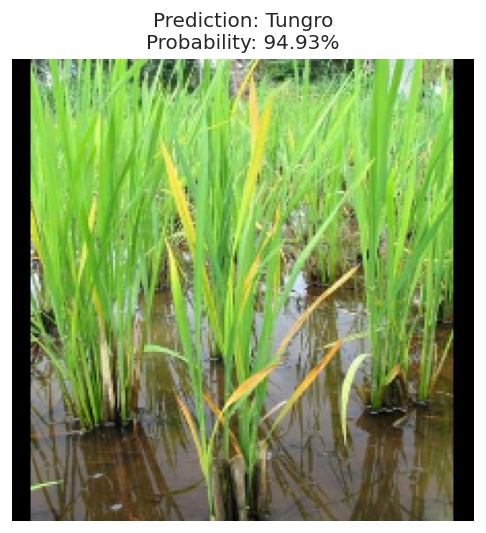

In [112]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image
from io import BytesIO

# Use the frozen, selected CNN V4
final_model = tf.keras.models.load_model(
    "/content/rice_cnn_models/corrected/rice_disease_final_cnn.keras",
    compile=False
)

class_names = [
    "Bacterialblight",
    "Blast",
    "Brownspot",
    "Tungro"
]

def prepare_uploaded_image(image_bytes):
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image = tf.image.convert_image_dtype(
        image, tf.float32
    )
    image = tf.image.resize_with_pad(
        image, 224, 224
    )

    return image.numpy()

uploaded = files.upload()

for filename, contents in uploaded.items():

    image = prepare_uploaded_image(contents)

    probabilities = final_model.predict(
        image[None, ...],
        verbose=0
    )[0]

    predicted_idx = int(np.argmax(probabilities))

    print("\nImage:", filename)
    print("Predicted disease:", class_names[predicted_idx])
    print("Model probability:",
          f"{probabilities[predicted_idx]:.2%}")

    print("\nClass probabilities:")
    for name, probability in zip(
        class_names, probabilities
    ):
        print(f"{name}: {probability:.2%}")

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"Prediction: {class_names[predicted_idx]}\n"
        f"Probability: {probabilities[predicted_idx]:.2%}"
    )
    plt.axis("off")
    plt.show()


## Conclusion

This notebook builds and evaluates a custom CNN pipeline for rice leaf disease classification. The main technical strengths are the duplicate-analysis workflow, corrected grouped splitting, multiple CNN ablation experiments, final held-out test evaluation, and Grad-CAM interpretability.

The selected final model is CNN V4. On the held-out corrected test set, it reports approximately 98.68% accuracy, with macro precision, recall, and F1 also reported in the test-evaluation output above.

For presentation, the most important message is that the final result is not based only on an initial split: the notebook audits possible near-duplicate leakage, rebuilds corrected partitions, retrains the models, and then evaluates the selected model on the held-out test set.
